# 📊 Data Preparation — VISBI 2026
**Digital Marketing Analytics Dashboard Competition**

Pada Notebook ini dilakukan proses **Exploratory Data Analysis (EDA)**, **Data Cleaning**, dan **Validasi Integritas Data** sebelum data digunakan untuk pembuatan dashboard.

---
**Struktur Notebook:**
1. Import Library  
2. Load Dataset  
3. Analisis & Cleaning `dim_date`  
4. Analisis & Cleaning `dim_channel`  
5. Analisis & Cleaning `dim_campaign`  
6. Analisis & Cleaning `dim_ad_content`  
7. Analisis & Cleaning `dim_kol`  
8. Analisis & Cleaning `dim_product`  
9. Analisis & Cleaning `dim_customer`  
10. Analisis & Cleaning `fact_marketing_daily`  
11. Analisis & Cleaning `fact_web_events`  
12. Analisis & Cleaning `fact_orders`  
13. Analisis & Cleaning `fact_budget`  
14. Analisis Relasi Antar Tabel  
15. Simpan Dataset Hasil Cleaning  

---
## 1. Import Library

In [239]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
import os

warnings.filterwarnings('ignore')

# Konfigurasi tampilan
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:,.4f}'.format)
pd.set_option('display.width', 200)

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 100

print('Libraries berhasil diimport')
print(f'Pandas version : {pd.__version__}')
print(f'NumPy version  : {np.__version__}')

Libraries berhasil diimport
Pandas version : 3.0.1
NumPy version  : 2.1.2


---
## 2. Load Dataset

In [240]:
# Path dataset
DATA_PATH = 'dataset/'

# Load semua tabel
dim_date             = pd.read_csv(DATA_PATH + 'dim_date.csv')
dim_channel          = pd.read_csv(DATA_PATH + 'dim_channel.csv')
dim_campaign         = pd.read_csv(DATA_PATH + 'dim_campaign.csv')
dim_ad_content       = pd.read_csv(DATA_PATH + 'dim_ad_content.csv')
dim_kol              = pd.read_csv(DATA_PATH + 'dim_kol.csv')
dim_product          = pd.read_csv(DATA_PATH + 'dim_product.csv')
dim_customer         = pd.read_csv(DATA_PATH + 'dim_customer.csv')
fact_marketing_daily = pd.read_csv(DATA_PATH + 'fact_marketing_daily.csv')
fact_web_events      = pd.read_csv(DATA_PATH + 'fact_web_events.csv')
fact_orders          = pd.read_csv(DATA_PATH + 'fact_orders.csv')
fact_budget          = pd.read_csv(DATA_PATH + 'fact_budget.csv')

tables = {
    'dim_date'             : dim_date,
    'dim_channel'          : dim_channel,
    'dim_campaign'         : dim_campaign,
    'dim_ad_content'       : dim_ad_content,
    'dim_kol'              : dim_kol,
    'dim_product'          : dim_product,
    'dim_customer'         : dim_customer,
    'fact_marketing_daily' : fact_marketing_daily,
    'fact_web_events'      : fact_web_events,
    'fact_orders'          : fact_orders,
    'fact_budget'          : fact_budget,
}

# Ringkasan awal 
print('=' * 60)
print(f'{"Tabel":<25} {"Baris":>10} {"Kolom":>8}')
print('=' * 60)
for name, df in tables.items():
    print(f'{name:<25} {df.shape[0]:>10,} {df.shape[1]:>8}')
print('=' * 60)
print('Dataset berhasil dimuat')

Tabel                          Baris    Kolom
dim_date                         365       12
dim_channel                       12        6
dim_campaign                      62       12
dim_ad_content                   194        9
dim_kol                           28       12
dim_product                       40        8
dim_customer                  15,000       12
fact_marketing_daily          15,849       22
fact_web_events               72,881       19
fact_orders                    1,490       17
fact_budget                      228        8
Dataset berhasil dimuat


---
## 3. Analisis & Cleaning — `dim_date`

Tabel dimensi kalender untuk analisis temporal.

**Primary Key:** `date_id`

### 3.1 Gambaran Dataset

In [241]:
print('Shape :', dim_date.shape)
print()
dim_date.info()

Shape : (365, 12)

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   date_id          365 non-null    int64
 1   date             365 non-null    str  
 2   year             365 non-null    int64
 3   quarter          365 non-null    str  
 4   month            365 non-null    int64
 5   month_name       365 non-null    str  
 6   week             365 non-null    int64
 7   day              365 non-null    int64
 8   day_name         365 non-null    str  
 9   is_weekend       365 non-null    bool 
 10  is_holiday       365 non-null    bool 
 11  campaign_season  365 non-null    str  
dtypes: bool(2), int64(5), str(5)
memory usage: 29.4 KB


In [242]:
display(dim_date.head(5))
display(dim_date.sample(5, random_state=42))

,date_id,date,year,quarter,month,month_name,week,day,day_name,is_weekend,is_holiday,campaign_season
0,20250101,2025-01-01,2025,Q1,1,January,1,1,Wednesday,False,True,Double Date Flash Sale
1,20250102,2025-01-02,2025,Q1,1,January,1,2,Thursday,False,False,Early Month
2,20250103,2025-01-03,2025,Q1,1,January,1,3,Friday,False,False,Early Month
3,20250104,2025-01-04,2025,Q1,1,January,1,4,Saturday,True,False,Regular
4,20250105,2025-01-05,2025,Q1,1,January,1,5,Sunday,True,False,Regular


,date_id,date,year,quarter,month,month_name,week,day,day_name,is_weekend,is_holiday,campaign_season
193,20250713,2025-07-13,2025,Q3,7,July,28,13,Sunday,True,False,Regular
33,20250203,2025-02-03,2025,Q1,2,February,6,3,Monday,False,False,Early Month
15,20250116,2025-01-16,2025,Q1,1,January,3,16,Thursday,False,False,Regular
309,20251106,2025-11-06,2025,Q4,11,November,45,6,Thursday,False,False,Regular
57,20250227,2025-02-27,2025,Q1,2,February,9,27,Thursday,False,False,Payday


### 3.2 Statistik Deskriptif

In [243]:
# Kolom numerik
display(dim_date.describe())

# Kolom kategorikal
cat_cols = dim_date.select_dtypes(include='object').columns.tolist()
for col in cat_cols:
    print(f'\n{col} ({dim_date[col].nunique()} unique)')
    print(dim_date[col].value_counts().head(10))

,date_id,year,month,week,day
count,365.0000,365.0000,365.0000,365.0000,365.0000
mean,"20,250,668.3233","2,025.0000",6.5260,26.4301,15.7205
std,345.4755,0.0000,3.4526,15.0676,8.8083
min,"20,250,101.0000","2,025.0000",1.0000,1.0000,1.0000
25%,"20,250,402.0000","2,025.0000",4.0000,13.0000,8.0000
50%,"20,250,702.0000","2,025.0000",7.0000,26.0000,16.0000
75%,"20,251,001.0000","2,025.0000",10.0000,39.0000,23.0000
max,"20,251,231.0000","2,025.0000",12.0000,52.0000,31.0000



date (365 unique)
date
2025-01-01    1
2025-01-02    1
2025-01-03    1
2025-01-04    1
2025-01-05    1
2025-01-06    1
2025-01-07    1
2025-01-08    1
2025-01-09    1
2025-01-10    1
Name: count, dtype: int64

quarter (4 unique)
quarter
Q3    92
Q4    92
Q2    91
Q1    90
Name: count, dtype: int64

month_name (12 unique)
month_name
January      31
March        31
May          31
July         31
August       31
October      31
December     31
April        30
June         30
September    30
Name: count, dtype: int64

day_name (7 unique)
day_name
Wednesday    53
Thursday     52
Friday       52
Saturday     52
Sunday       52
Monday       52
Tuesday      52
Name: count, dtype: int64

campaign_season (7 unique)
campaign_season
Regular                   196
Payday                     63
Ramadan                    30
Year End Sale              30
Early Month                25
Double Date Flash Sale     12
Lebaran                     9
Name: count, dtype: int64


### 3.3 Missing Value Analysis

In [244]:
mv = dim_date.isnull().sum()
mv_pct = (mv / len(dim_date) * 100).round(2)
mv_df = pd.DataFrame({'missing_count': mv, 'missing_pct': mv_pct})
mv_df = mv_df[mv_df['missing_count'] > 0]
if mv_df.empty:
    print('Tidak ada missing value pada dim_date')
else:
    display(mv_df)

Tidak ada missing value pada dim_date


### 3.4 Duplicate Analysis

In [245]:
dup_rows = dim_date.duplicated().sum()
dup_pk   = dim_date.duplicated(subset=['date_id']).sum()
print(f'Duplicate rows       : {dup_rows}')
print(f'Duplicate date_id PK : {dup_pk}')

Duplicate rows       : 0
Duplicate date_id PK : 0


### 3.5 Unique Value Analysis

In [246]:
print('Jumlah unique value per kolom:')
print(dim_date.nunique())

# Cek kategori kolom kategorikal
for col in cat_cols:
    print(f'\nUnique [{col}]')
    print(dim_date[col].unique())

Jumlah unique value per kolom:
date_id            365
date               365
year                 1
quarter              4
month               12
month_name          12
week                52
day                 31
day_name             7
is_weekend           2
is_holiday           2
campaign_season      7
dtype: int64

Unique [date]
<StringArray>
['2025-01-01', '2025-01-02', '2025-01-03', '2025-01-04', '2025-01-05', '2025-01-06', '2025-01-07', '2025-01-08', '2025-01-09', '2025-01-10',
 ...
 '2025-12-22', '2025-12-23', '2025-12-24', '2025-12-25', '2025-12-26', '2025-12-27', '2025-12-28', '2025-12-29', '2025-12-30', '2025-12-31']
Length: 365, dtype: str

Unique [quarter]
<StringArray>
['Q1', 'Q2', 'Q3', 'Q4']
Length: 4, dtype: str

Unique [month_name]
<StringArray>
['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
Length: 12, dtype: str

Unique [day_name]
<StringArray>
['Wednesday', 'Thursday', 'Friday', 'Saturday',

### 3.6 Data Type Validation

In [247]:
print('Tipe data sebelum cleaning:')
print(dim_date.dtypes)

Tipe data sebelum cleaning:
date_id            int64
date                 str
year               int64
quarter              str
month              int64
month_name           str
week               int64
day                int64
day_name             str
is_weekend          bool
is_holiday          bool
campaign_season      str
dtype: object


### 3.7 Validasi Nilai

In [248]:
# Cek apakah kolom 'date' memiliki format tanggal yang valid
try:
    parsed = pd.to_datetime(dim_date['date'], errors='coerce')
    invalid_dates = parsed.isna().sum()
    print(f'Tanggal tidak valid (NaT) : {invalid_dates}')
    print(f'Rentang tanggal           : {parsed.min()} → {parsed.max()}')
except Exception as e:
    print(f'Error parsing tanggal: {e}')

# Validasi bulan, hari, tahun
print(f'\nRentang year  : {dim_date["year"].min()} — {dim_date["year"].max()}')
print(f'Rentang month : {dim_date["month"].min()} — {dim_date["month"].max()}')
print(f'Rentang day   : {dim_date["day"].min()} — {dim_date["day"].max()}')
print(f'Rentang week  : {dim_date["week"].min()} — {dim_date["week"].max()}')

Tanggal tidak valid (NaT) : 0
Rentang tanggal           : 2025-01-01 00:00:00 → 2025-12-31 00:00:00

Rentang year  : 2025 — 2025
Rentang month : 1 — 12
Rentang day   : 1 — 31
Rentang week  : 1 — 52


### 3.8 Cleaning dim_date

In [249]:
dim_date_clean = dim_date.copy()

# 1. Konversi kolom 'date' ke tipe datetime 
# Alasan: kolom date dibaca sebagai object, perlu dikonversi ke datetime
dim_date_clean['date'] = pd.to_datetime(dim_date_clean['date'], errors='coerce')

# 2. Konversi date_id ke string 
# Alasan: date_id digunakan sebagai FK, disimpan sebagai string agar konsisten
dim_date_clean['date_id'] = dim_date_clean['date_id'].astype(str)

# 3. Standardisasi kolom boolean 
# Alasan: is_weekend dan is_holiday bisa terbaca sebagai string 'True'/'False'
for col in ['is_weekend', 'is_holiday']:
    if dim_date_clean[col].dtype == object:
        dim_date_clean[col] = dim_date_clean[col].map({'True': True, 'False': False})

# 4. Strip whitespace kolom kategorikal
for col in ['month_name', 'day_name', 'quarter', 'campaign_season']:
    if col in dim_date_clean.columns:
        dim_date_clean[col] = dim_date_clean[col].str.strip()

# 5. Hapus duplicate rows
before = len(dim_date_clean)
dim_date_clean.drop_duplicates(inplace=True)
print(f'Duplicate dihapus: {before - len(dim_date_clean)} baris')

print('\nTipe data setelah cleaning:')
print(dim_date_clean.dtypes)
print(f'\nShape akhir: {dim_date_clean.shape}')
print('dim_date cleaning selesai')

Duplicate dihapus: 0 baris

Tipe data setelah cleaning:
date_id                       str
date               datetime64[us]
year                        int64
quarter                       str
month                       int64
month_name                    str
week                        int64
day                         int64
day_name                      str
is_weekend                   bool
is_holiday                   bool
campaign_season               str
dtype: object

Shape akhir: (365, 12)
dim_date cleaning selesai


---
## 4. Analisis & Cleaning — `dim_channel`

Master data kanal pemasaran.

**Primary Key:** `channel_id`

### 4.1 Gambaran Dataset

In [250]:
print('Shape :', dim_channel.shape)
print()
dim_channel.info()
display(dim_channel.head())
display(dim_channel.sample(min(5, len(dim_channel)), random_state=42))

Shape : (12, 6)

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   channel_id         12 non-null     str  
 1   channel_name       12 non-null     str  
 2   channel_type       12 non-null     str  
 3   platform           12 non-null     str  
 4   paid_or_organic    12 non-null     str  
 5   objective_default  12 non-null     str  
dtypes: str(6)
memory usage: 708.0 bytes


,channel_id,channel_name,channel_type,platform,paid_or_organic,objective_default
0,CH001,Meta Ads,Paid Social,Meta,Paid,Conversion
1,CH002,Google Ads,Paid Search,Google,Paid,Conversion
2,CH003,TikTok Ads,Paid Social,TikTok,Paid,Traffic
3,CH004,Instagram Organic,Organic Social,Instagram,Organic,Engagement
4,CH005,TikTok Organic,Organic Social,TikTok,Organic,Engagement


,channel_id,channel_name,channel_type,platform,paid_or_organic,objective_default
10,CH011,Marketplace Ads,Paid Marketplace,Shopee/Tokopedia,Paid,Conversion
9,CH010,KOL,Influencer,Multi Platform,Paid,Awareness
0,CH001,Meta Ads,Paid Social,Meta,Paid,Conversion
8,CH009,Affiliate,Partnership,Affiliate Network,Partner,Conversion
5,CH006,Email Marketing,CRM,Email,Owned,Retention


### 4.2 Statistik Deskriptif

In [251]:
cat_cols_ch = dim_channel.select_dtypes(include='object').columns.tolist()
for col in cat_cols_ch:
    print(f'\n{col} ({dim_channel[col].nunique()} unique) ')
    print(dim_channel[col].value_counts())


channel_id (12 unique) 
channel_id
CH001    1
CH002    1
CH003    1
CH004    1
CH005    1
CH006    1
CH007    1
CH008    1
CH009    1
CH010    1
CH011    1
CH012    1
Name: count, dtype: int64

channel_name (12 unique) 
channel_name
Meta Ads              1
Google Ads            1
TikTok Ads            1
Instagram Organic     1
TikTok Organic        1
Email Marketing       1
WhatsApp Broadcast    1
SEO                   1
Affiliate             1
KOL                   1
Marketplace Ads       1
Direct                1
Name: count, dtype: int64

channel_type (9 unique) 
channel_type
Paid Social         2
Organic Social      2
CRM                 2
Paid Search         1
Organic Search      1
Partnership         1
Influencer          1
Paid Marketplace    1
Direct              1
Name: count, dtype: int64

platform (10 unique) 
platform
Google               2
TikTok               2
Meta                 1
Instagram            1
Email                1
WhatsApp             1
Affiliate Network  

### 4.3 Missing Value Analysis

In [252]:
mv = dim_channel.isnull().sum()
mv_pct = (mv / len(dim_channel) * 100).round(2)
mv_df = pd.DataFrame({'missing_count': mv, 'missing_pct': mv_pct})
mv_df = mv_df[mv_df['missing_count'] > 0]
if mv_df.empty:
    print('Tidak ada missing value pada dim_channel')
else:
    display(mv_df)

Tidak ada missing value pada dim_channel


### 4.4 Duplicate Analysis

In [253]:
print(f'Duplicate rows         : {dim_channel.duplicated().sum()}')
print(f'Duplicate channel_id PK: {dim_channel.duplicated(subset=["channel_id"]).sum()}')

Duplicate rows         : 0
Duplicate channel_id PK: 0


### 4.5 Unique Value Analysis

In [254]:
print('Jumlah unique per kolom:')
print(dim_channel.nunique())

for col in cat_cols_ch:
    print(f'\nUnique [{col}] ')
    print(sorted(dim_channel[col].dropna().unique()))

Jumlah unique per kolom:
channel_id           12
channel_name         12
channel_type          9
platform             10
paid_or_organic       4
objective_default     5
dtype: int64

Unique [channel_id] 
['CH001', 'CH002', 'CH003', 'CH004', 'CH005', 'CH006', 'CH007', 'CH008', 'CH009', 'CH010', 'CH011', 'CH012']

Unique [channel_name] 
['Affiliate', 'Direct', 'Email Marketing', 'Google Ads', 'Instagram Organic', 'KOL', 'Marketplace Ads', 'Meta Ads', 'SEO', 'TikTok Ads', 'TikTok Organic', 'WhatsApp Broadcast']

Unique [channel_type] 
['CRM', 'Direct', 'Influencer', 'Organic Search', 'Organic Social', 'Paid Marketplace', 'Paid Search', 'Paid Social', 'Partnership']

Unique [platform] 
['Affiliate Network', 'Email', 'Google', 'Instagram', 'Meta', 'Multi Platform', 'Shopee/Tokopedia', 'TikTok', 'Website', 'WhatsApp']

Unique [paid_or_organic] 
['Organic', 'Owned', 'Paid', 'Partner']

Unique [objective_default] 
['Awareness', 'Conversion', 'Engagement', 'Retention', 'Traffic']


### 4.6 Cleaning dim_channel

In [255]:
dim_channel_clean = dim_channel.copy()

# 1. Strip whitespace pada semua kolom string
for col in dim_channel_clean.select_dtypes(include='object').columns:
    dim_channel_clean[col] = dim_channel_clean[col].str.strip()

# 2. Standardisasi kapital kategori (Title Case)
# Alasan: menghindari inkonsistensi kapitalisasi pada kolom kategori
for col in ['channel_type', 'paid_or_organic', 'objective_default']:
    if col in dim_channel_clean.columns:
        dim_channel_clean[col] = dim_channel_clean[col].str.title()

# 3. Hapus duplicate
before = len(dim_channel_clean)
dim_channel_clean.drop_duplicates(inplace=True)
print(f'Duplicate dihapus: {before - len(dim_channel_clean)} baris')

print(f'Shape akhir: {dim_channel_clean.shape}')
display(dim_channel_clean)
print('dim_channel cleaning selesai')

Duplicate dihapus: 0 baris
Shape akhir: (12, 6)


,channel_id,channel_name,channel_type,platform,paid_or_organic,objective_default
0,CH001,Meta Ads,Paid Social,Meta,Paid,Conversion
1,CH002,Google Ads,Paid Search,Google,Paid,Conversion
2,CH003,TikTok Ads,Paid Social,TikTok,Paid,Traffic
3,CH004,Instagram Organic,Organic Social,Instagram,Organic,Engagement
4,CH005,TikTok Organic,Organic Social,TikTok,Organic,Engagement
5,CH006,Email Marketing,Crm,Email,Owned,Retention
6,CH007,WhatsApp Broadcast,Crm,WhatsApp,Owned,Retention
7,CH008,SEO,Organic Search,Google,Organic,Traffic
8,CH009,Affiliate,Partnership,Affiliate Network,Partner,Conversion
9,CH010,KOL,Influencer,Multi Platform,Paid,Awareness


dim_channel cleaning selesai


In [256]:
cat_cols_ch = dim_channel_clean.select_dtypes(include='object').columns.tolist()
for col in cat_cols_ch:
    print(f'\n{col} ({dim_channel_clean[col].nunique()} unique) ')
    print(dim_channel_clean[col].value_counts())


channel_id (12 unique) 
channel_id
CH001    1
CH002    1
CH003    1
CH004    1
CH005    1
CH006    1
CH007    1
CH008    1
CH009    1
CH010    1
CH011    1
CH012    1
Name: count, dtype: int64

channel_name (12 unique) 
channel_name
Meta Ads              1
Google Ads            1
TikTok Ads            1
Instagram Organic     1
TikTok Organic        1
Email Marketing       1
WhatsApp Broadcast    1
SEO                   1
Affiliate             1
KOL                   1
Marketplace Ads       1
Direct                1
Name: count, dtype: int64

channel_type (9 unique) 
channel_type
Paid Social         2
Organic Social      2
Crm                 2
Paid Search         1
Organic Search      1
Partnership         1
Influencer          1
Paid Marketplace    1
Direct              1
Name: count, dtype: int64

platform (10 unique) 
platform
Google               2
TikTok               2
Meta                 1
Instagram            1
Email                1
WhatsApp             1
Affiliate Network  

---
## 5. Analisis & Cleaning `dim_campaign`

Master data kampanye pemasaran.

**Primary Key:** `campaign_id`

### 5.1 Gambaran Dataset

In [257]:
print('Shape :', dim_campaign.shape)
print()
dim_campaign.info()
display(dim_campaign.head(5))
display(dim_campaign.sample(5, random_state=42))

Shape : (62, 12)

<class 'pandas.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   campaign_id             62 non-null     str  
 1   campaign_name           62 non-null     str  
 2   channel_id              62 non-null     str  
 3   objective               62 non-null     str  
 4   campaign_type           62 non-null     str  
 5   start_date              62 non-null     str  
 6   end_date                62 non-null     str  
 7   budget_planned          62 non-null     int64
 8   target_audience         62 non-null     str  
 9   product_category_focus  62 non-null     str  
 10  funnel_stage            62 non-null     str  
 11  campaign_status         62 non-null     str  
dtypes: int64(1), str(11)
memory usage: 5.9 KB


,campaign_id,campaign_name,channel_id,objective,campaign_type,start_date,end_date,budget_planned,target_audience,product_category_focus,funnel_stage,campaign_status
0,CMP0001,Meta Broad Prospecting - Glow Serum,CH001,Conversion,Always On,2025-01-05,2025-06-30,950000000,Female 18-34 Broad,Skincare,Consideration,Completed
1,CMP0002,Meta Retargeting Cart Saver,CH001,Retargeting,Retargeting,2025-02-01,2025-12-31,260000000,ATC 14 days,Bundle,Conversion,Completed
2,CMP0003,TikTok Viral Traffic - Glow Routine,CH003,Traffic,Viral Video,2025-03-01,2025-08-31,520000000,Gen Z Beauty Interest,Skincare,Consideration,Paused
3,CMP0004,Google Search High Intent Skincare,CH002,Conversion,Search,2025-01-01,2025-12-31,620000000,Keyword high intent,Skincare,Conversion,Completed
4,CMP0005,Email Payday Retention Blast,CH006,Retention,CRM,2025-01-20,2025-12-31,65000000,Existing Buyers,Bundle,Retention,Completed


,campaign_id,campaign_name,channel_id,objective,campaign_type,start_date,end_date,budget_planned,target_audience,product_category_focus,funnel_stage,campaign_status
50,CMP0051,Affiliate Brand Video - Family Care Feb,CH009,Awareness,Brand Video,2025-02-17,2025-04-14,103560000,Existing Customer,Family Care,Awareness,Completed
56,CMP0057,Direct Always On - Bundle Jul,CH012,Conversion,Always On,2025-07-06,2025-10-13,2750000,Existing Customer,Bundle,Conversion,Completed
0,CMP0001,Meta Broad Prospecting - Glow Serum,CH001,Conversion,Always On,2025-01-05,2025-06-30,950000000,Female 18-34 Broad,Skincare,Consideration,Completed
57,CMP0058,TikTok Ads Influencer Launch - Family Care Mar,CH003,Awareness,Influencer Launch,2025-03-30,2025-05-09,139615000,Male 18-34 Grooming Interest,Family Care,Awareness,Completed
5,CMP0006,Mega KOL Awareness Lifestyle,CH010,Awareness,Influencer Launch,2025-05-01,2025-05-31,380000000,Mass audience,Wellness,Awareness,Completed


### 5.2 Statistik Deskriptif

In [258]:
# Numerik
display(dim_campaign.describe(include='number'))

# Kategorikal
cat_cols_cmp = dim_campaign.select_dtypes(include='object').columns.tolist()
for col in cat_cols_cmp:
    if col not in ['campaign_id', 'campaign_name', 'start_date', 'end_date']:
        print(f'\n{col} ({dim_campaign[col].nunique()} unique)')
        print(dim_campaign[col].value_counts())

,budget_planned
count,62.0000
mean,"134,632,032.2581"
std,"163,358,061.1697"
min,"2,750,000.0000"
25%,"21,904,000.0000"
50%,"99,900,000.0000"
75%,"159,121,500.0000"
max,"950,000,000.0000"



channel_id (11 unique)
channel_id
CH001    12
CH002     9
CH010     8
CH012     8
CH011     6
CH003     5
CH007     5
CH009     4
CH006     3
CH008     1
CH004     1
Name: count, dtype: int64

objective (7 unique)
objective
Conversion         24
Awareness          11
Traffic             9
Retargeting         7
Retention           7
Lead Generation     3
Engagement          1
Name: count, dtype: int64

campaign_type (19 unique)
campaign_type
Always On                   10
Search                       7
Flash Sale                   6
CRM                          5
Marketplace Sale             5
Influencer Launch            4
Brand Video                  4
Reach                        3
Product View Retargeting     3
Cart Recovery                3
Lead Magnet                  2
Content Distribution         2
VIP Promo                    2
Retargeting                  1
Viral Video                  1
Influencer Review            1
Spark Ads                    1
UGC Challenge              

### 5.3 Missing Value Analysis

In [259]:
mv = dim_campaign.isnull().sum()
mv_pct = (mv / len(dim_campaign) * 100).round(2)
mv_df = pd.DataFrame({'missing_count': mv, 'missing_pct': mv_pct})
mv_df = mv_df[mv_df['missing_count'] > 0]
if mv_df.empty:
    print('Tidak ada missing value pada dim_campaign')
else:
    display(mv_df)

Tidak ada missing value pada dim_campaign


### 5.4 Duplicate Analysis

In [260]:
print(f'Duplicate rows          : {dim_campaign.duplicated().sum()}')
print(f'Duplicate campaign_id PK: {dim_campaign.duplicated(subset=["campaign_id"]).sum()}')

Duplicate rows          : 0
Duplicate campaign_id PK: 0


### 5.5 Unique Value Analysis

In [261]:
print('Jumlah unique per kolom:')
print(dim_campaign.nunique())

for col in ['objective', 'campaign_type', 'funnel_stage', 'campaign_status']:
    print(f'\nUnique [{col}]')
    print(sorted(dim_campaign[col].dropna().unique()))

Jumlah unique per kolom:
campaign_id               62
campaign_name             61
channel_id                11
objective                  7
campaign_type             19
start_date                57
end_date                  47
budget_planned            62
target_audience           21
product_category_focus     8
funnel_stage               4
campaign_status            3
dtype: int64

Unique [objective]
['Awareness', 'Conversion', 'Engagement', 'Lead Generation', 'Retargeting', 'Retention', 'Traffic']

Unique [campaign_type]
['Always On', 'Brand Video', 'CRM', 'Cart Recovery', 'Content Distribution', 'Flash Sale', 'Influencer Launch', 'Influencer Review', 'Lead Magnet', 'Marketplace Sale', 'Product View Retargeting', 'Quiz', 'Reach', 'Retargeting', 'Search', 'Spark Ads', 'UGC Challenge', 'VIP Promo', 'Viral Video']

Unique [funnel_stage]
['Awareness', 'Consideration', 'Conversion', 'Retention']

Unique [campaign_status]
['Active', 'Completed', 'Paused']


### 5.6 Validasi Nilai

In [262]:
# Validasi tanggal: start_date dan end_date
dim_campaign['start_date_parsed'] = pd.to_datetime(dim_campaign['start_date'], errors='coerce')
dim_campaign['end_date_parsed']   = pd.to_datetime(dim_campaign['end_date'],   errors='coerce')

invalid_start = dim_campaign['start_date_parsed'].isna().sum()
invalid_end   = dim_campaign['end_date_parsed'].isna().sum()
print(f'Tanggal start tidak valid : {invalid_start}')
print(f'Tanggal end tidak valid   : {invalid_end}')

# Cek logika: end_date >= start_date
invalid_logic = (dim_campaign['end_date_parsed'] < dim_campaign['start_date_parsed']).sum()
print(f'end_date < start_date (tidak logis): {invalid_logic}')

# Budget direncanakan tidak boleh negatif
neg_budget = (dim_campaign['budget_planned'] < 0).sum()
print(f'Budget negatif: {neg_budget}')

Tanggal start tidak valid : 0
Tanggal end tidak valid   : 0
end_date < start_date (tidak logis): 1
Budget negatif: 0


In [263]:
# Cari semua baris yang end_date lebih kecil dari start_date
invalid_mask = dim_campaign['end_date_parsed'] < dim_campaign['start_date_parsed']

# Swap kolom parsed dates untuk baris yang invalid
dim_campaign.loc[invalid_mask, ['start_date_parsed', 'end_date_parsed']] = \
    dim_campaign.loc[invalid_mask, ['end_date_parsed', 'start_date_parsed']].values

# Swap kolom asli (string dates) juga biar konsisten
dim_campaign.loc[invalid_mask, ['start_date', 'end_date']] = \
    dim_campaign.loc[invalid_mask, ['end_date', 'start_date']].values

# ============================
# Validasi ulang setelah swap
# ============================

# Cek apakah masih ada baris end_date < start_date
invalid_after_swap = dim_campaign[dim_campaign['end_date_parsed'] < dim_campaign['start_date_parsed']]

print("Jumlah baris invalid setelah swap:", invalid_after_swap.shape[0])
print("Detail baris invalid (kalau masih ada):")
print(invalid_after_swap[['campaign_id','start_date','end_date','start_date_parsed','end_date_parsed']])

Jumlah baris invalid setelah swap: 0
Detail baris invalid (kalau masih ada):
Empty DataFrame
Columns: [campaign_id, start_date, end_date, start_date_parsed, end_date_parsed]
Index: []


### 5.7 Cleaning dim_campaign

In [264]:
dim_campaign_clean = dim_campaign.copy()

# 1. Konversi kolom tanggal ke datetime 
dim_campaign_clean['start_date'] = pd.to_datetime(dim_campaign_clean['start_date'], errors='coerce')
dim_campaign_clean['end_date']   = pd.to_datetime(dim_campaign_clean['end_date'],   errors='coerce')

# 2. Hapus kolom bantu parsing yang sudah tidak diperlukan 
for col in ['start_date_parsed', 'end_date_parsed']:
    if col in dim_campaign_clean.columns:
        dim_campaign_clean.drop(columns=[col], inplace=True)

# 3. Strip whitespace pada semua kolom string
for col in dim_campaign_clean.select_dtypes(include='object').columns:
    dim_campaign_clean[col] = dim_campaign_clean[col].str.strip()

# 4. Standardisasi kapital kategori 
for col in ['objective', 'campaign_type', 'funnel_stage', 'campaign_status']:
    if col in dim_campaign_clean.columns:
        dim_campaign_clean[col] = dim_campaign_clean[col].str.strip().str.title()

# 5. Hapus duplicate 
before = len(dim_campaign_clean)
dim_campaign_clean.drop_duplicates(inplace=True)
print(f'Duplicate dihapus: {before - len(dim_campaign_clean)} baris')

print(f'Shape akhir: {dim_campaign_clean.shape}')
print('dim_campaign cleaning selesai')

Duplicate dihapus: 0 baris
Shape akhir: (62, 12)
dim_campaign cleaning selesai


In [265]:

# Kategorikal
cat_cols_cmp = dim_campaign_clean.select_dtypes(include='object').columns.tolist()
for col in cat_cols_cmp:
    if col not in ['campaign_id', 'campaign_name', 'start_date', 'end_date']:
        print(f'\n{col} ({dim_campaign_clean[col].nunique()} unique)')
        print(dim_campaign_clean[col].value_counts())


channel_id (11 unique)
channel_id
CH001    12
CH002     9
CH010     8
CH012     8
CH011     6
CH003     5
CH007     5
CH009     4
CH006     3
CH008     1
CH004     1
Name: count, dtype: int64

objective (7 unique)
objective
Conversion         24
Awareness          11
Traffic             9
Retargeting         7
Retention           7
Lead Generation     3
Engagement          1
Name: count, dtype: int64

campaign_type (19 unique)
campaign_type
Always On                   10
Search                       7
Flash Sale                   6
Crm                          5
Marketplace Sale             5
Influencer Launch            4
Brand Video                  4
Reach                        3
Product View Retargeting     3
Cart Recovery                3
Lead Magnet                  2
Content Distribution         2
Vip Promo                    2
Retargeting                  1
Viral Video                  1
Influencer Review            1
Spark Ads                    1
Ugc Challenge              

---
## 6. Analisis & Cleaning  `dim_ad_content`

Master data iklan, konten kreatif, CTA, dan landing page.

**Primary Key:** `ad_id`

### 6.1 Gambaran Dataset

In [266]:
print('Shape :', dim_ad_content.shape)
print()
dim_ad_content.info()
display(dim_ad_content.head(5))
display(dim_ad_content.sample(5, random_state=42))

Shape : (194, 9)

<class 'pandas.DataFrame'>
RangeIndex: 194 entries, 0 to 193
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   ad_id          194 non-null    str  
 1   campaign_id    194 non-null    str  
 2   creative_type  194 non-null    str  
 3   content_angle  194 non-null    str  
 4   headline       194 non-null    str  
 5   CTA            194 non-null    str  
 6   landing_page   194 non-null    str  
 7   offer_type     194 non-null    str  
 8   ad_format      194 non-null    str  
dtypes: str(9)
memory usage: 13.8 KB


,ad_id,campaign_id,creative_type,content_angle,headline,CTA,landing_page,offer_type,ad_format
0,AD00001,CMP0001,Video,Problem Solution,Problem Solution untuk Skincare - Claim Voucher,Claim Voucher,/product/glow-serum,No Offer,Message
1,AD00002,CMP0001,Carousel,Urgency,Urgency untuk Skincare - Claim Voucher,Claim Voucher,/bundle/glow-routine,20% Discount,Feed
2,AD00003,CMP0001,Video,Discount,Discount untuk Skincare - Subscribe,Subscribe,/promo-flash-sale,Voucher Cashback,Feed
3,AD00004,CMP0002,Static Image,Problem Solution,Problem Solution untuk Bundle - Buy Now,Buy Now,/product/glow-serum,Buy 1 Get 1,Search
4,AD00005,CMP0002,Reels,Testimonial,Testimonial untuk Bundle - Claim Voucher,Claim Voucher,/product/glow-serum,Voucher Cashback,Search


,ad_id,campaign_id,creative_type,content_angle,headline,CTA,landing_page,offer_type,ad_format
138,AD00139,CMP0044,Carousel,Product Benefit,Product Benefit untuk Skincare - Shop Now,Shop Now,/,No Offer,Short Video
16,AD00017,CMP0005,Static Image,Product Benefit,Product Benefit untuk Bundle - Shop Now,Shop Now,/blog/skincare-routine,10% Discount,Story
155,AD00156,CMP0049,Marketplace Banner,Problem Solution,Problem Solution untuk Wellness - Buy Now,Buy Now,/marketplace-official-store,Voucher Cashback,Story
96,AD00097,CMP0030,Static Image,Lifestyle,Lifestyle untuk Bundle - Shop Now,Shop Now,/promo-flash-sale,10% Discount,Short Video
68,AD00069,CMP0021,Video,Educational,Educational untuk Skincare - Subscribe,Subscribe,/checkout-shipping,Voucher Cashback,Search


### 6.2 Statistik Deskriptif

In [267]:
cat_cols_ad = dim_ad_content.select_dtypes(include='object').columns.tolist()
for col in cat_cols_ad:
    if col not in ['ad_id', 'headline', 'landing_page']:
        print(f'\n{col} ({dim_ad_content[col].nunique()} unique) ')
        print(dim_ad_content[col].value_counts())


campaign_id (62 unique) 
campaign_id
CMP0002    4
CMP0004    4
CMP0005    4
CMP0006    4
CMP0007    4
CMP0008    4
CMP0012    4
CMP0013    4
CMP0015    4
CMP0016    4
CMP0018    4
CMP0022    4
CMP0024    4
CMP0029    4
CMP0030    4
CMP0037    4
CMP0040    4
CMP0041    4
CMP0042    4
CMP0043    4
CMP0046    4
CMP0047    4
CMP0053    4
CMP0060    4
CMP0001    3
CMP0003    3
CMP0010    3
CMP0017    3
CMP0019    3
CMP0020    3
CMP0023    3
CMP0026    3
CMP0033    3
CMP0034    3
CMP0035    3
CMP0036    3
CMP0044    3
CMP0048    3
CMP0051    3
CMP0052    3
CMP0054    3
CMP0055    3
CMP0057    3
CMP0059    3
CMP0061    3
CMP0062    3
CMP0009    2
CMP0011    2
CMP0014    2
CMP0021    2
CMP0025    2
CMP0027    2
CMP0028    2
CMP0031    2
CMP0032    2
CMP0038    2
CMP0039    2
CMP0045    2
CMP0049    2
CMP0050    2
CMP0056    2
CMP0058    2
Name: count, dtype: int64

creative_type (13 unique) 
creative_type
Static Image          35
Search Ad             24
Reels                 23
Video        

### 6.3 Missing Value Analysis

In [268]:
mv = dim_ad_content.isnull().sum()
mv_pct = (mv / len(dim_ad_content) * 100).round(2)
mv_df = pd.DataFrame({'missing_count': mv, 'missing_pct': mv_pct})
mv_df = mv_df[mv_df['missing_count'] > 0]
if mv_df.empty:
    print(' Tidak ada missing value pada dim_ad_content')
else:
    display(mv_df)

 Tidak ada missing value pada dim_ad_content


### 6.4 Duplicate Analysis

In [269]:
print(f'Duplicate rows   : {dim_ad_content.duplicated().sum()}')
print(f'Duplicate ad_id  : {dim_ad_content.duplicated(subset=["ad_id"]).sum()}')

Duplicate rows   : 0
Duplicate ad_id  : 0


### 6.5 Unique Value Analysis

In [270]:
print('Jumlah unique per kolom:')
print(dim_ad_content.nunique())

for col in ['creative_type', 'content_angle', 'CTA', 'offer_type', 'ad_format']:
    print(f'\nUnique [{col}] ')
    print(sorted(dim_ad_content[col].dropna().unique()))

Jumlah unique per kolom:
ad_id            194
campaign_id       62
creative_type     13
content_angle      7
headline         137
CTA                7
landing_page      15
offer_type         8
ad_format          7
dtype: int64

Unique [creative_type] 
['Affiliate Link', 'Carousel', 'Display Banner', 'Email Banner', 'Marketplace Banner', 'Message Template', 'Reels', 'SEO Article', 'Search Ad', 'Static Image', 'Story', 'Video', 'Website Direct']

Unique [content_angle] 
['Discount', 'Educational', 'Lifestyle', 'Problem Solution', 'Product Benefit', 'Testimonial', 'Urgency']

Unique [CTA] 
['Add to Cart', 'Buy Now', 'Chat Admin', 'Claim Voucher', 'Learn More', 'Shop Now', 'Subscribe']

Unique [offer_type] 
['10% Discount', '20% Discount', 'Bundle Deal', 'Buy 1 Get 1', 'Free Guide', 'Free Shipping', 'No Offer', 'Voucher Cashback']

Unique [ad_format] 
['Display', 'Feed', 'Marketplace Slot', 'Message', 'Search', 'Short Video', 'Story']


### 6.6 Cleaning dim_ad_content

In [271]:
dim_ad_content_clean = dim_ad_content.copy()

# 1. Strip whitespace pada semua kolom string
for col in dim_ad_content_clean.select_dtypes(include='object').columns:
    dim_ad_content_clean[col] = dim_ad_content_clean[col].str.strip()

# 2. Standardisasi kapital kategori 
for col in ['creative_type', 'content_angle', 'CTA', 'offer_type', 'ad_format']:
    if col in dim_ad_content_clean.columns:
        dim_ad_content_clean[col] = dim_ad_content_clean[col].str.title()

# 3. Hapus duplicate 
before = len(dim_ad_content_clean)
dim_ad_content_clean.drop_duplicates(inplace=True)
print(f'Duplicate dihapus: {before - len(dim_ad_content_clean)} baris')

print(f'Shape akhir: {dim_ad_content_clean.shape}')
print('dim_ad_content cleaning selesai ')

Duplicate dihapus: 0 baris
Shape akhir: (194, 9)
dim_ad_content cleaning selesai 


---
## 7. Analisis & Cleaning `dim_kol`

Master data KOL (Key Opinion Leader) / Influencer.

**Primary Key:** `kol_id`

### 7.1 Gambaran Dataset

In [272]:
print('Shape :', dim_kol.shape)
print()
dim_kol.info()
display(dim_kol.head())
display(dim_kol.sample(min(5, len(dim_kol)), random_state=42))

Shape : (28, 12)

<class 'pandas.DataFrame'>
RangeIndex: 28 entries, 0 to 27
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   kol_id                    28 non-null     str    
 1   kol_name                  28 non-null     str    
 2   platform                  28 non-null     str    
 3   follower_count            28 non-null     int64  
 4   engagement_rate           28 non-null     float64
 5   niche                     28 non-null     str    
 6   audience_gender_dominant  28 non-null     str    
 7   audience_age_group        28 non-null     str    
 8   rate_card                 28 non-null     int64  
 9   kol_tier                  28 non-null     str    
 10  city                      28 non-null     str    
 11  credibility_score         28 non-null     float64
dtypes: float64(2), int64(2), str(8)
memory usage: 2.8 KB


,kol_id,kol_name,platform,follower_count,engagement_rate,niche,audience_gender_dominant,audience_age_group,rate_card,kol_tier,city,credibility_score
0,KOL001,Ayu Beauty,Instagram,356445,0.0218,Lifestyle,Female,25-34,88770000,Macro,Yogyakarta,88.8000
1,KOL002,Raka Review,Instagram,983850,0.0190,Lifestyle,Male,18-24,48813000,Macro,Jakarta,75.1000
2,KOL003,Nadia Skincare,TikTok,79396,0.0432,Beauty,Mixed,25-34,11361000,Micro,Semarang,80.4000
3,KOL004,Fitri Glow,Instagram,11547,0.0681,Skincare,Female,35-44,9720000,Micro,Jakarta,97.7000
4,KOL005,Dimas Deals,Instagram,8227,0.0780,Fashion,Male,45-54,1063000,Nano,Jakarta,81.1000


,kol_id,kol_name,platform,follower_count,engagement_rate,niche,audience_gender_dominant,audience_age_group,rate_card,kol_tier,city,credibility_score
9,KOL010,Bima Grooming,Instagram,339906,0.0409,Skincare,Male,18-24,36025000,Mid-tier,Jakarta,97.7000
25,KOL026,ayu beauty,YouTube,7881,0.0860,Lifestyle,Female,18-24,1633000,Nano,Denpasar,60.4000
8,KOL009,Tara Wellness,Instagram,7644,0.0906,Wellness,Female,35-44,941000,Nano,Bandung,66.5000
21,KOL022,Tasya Routine,TikTok,308510,0.0291,Fashion,Male,18-24,38536000,Mid-tier,Yogyakarta,62.0000
0,KOL001,Ayu Beauty,Instagram,356445,0.0218,Lifestyle,Female,25-34,88770000,Macro,Yogyakarta,88.8000


### 7.2 Statistik Deskriptif

In [273]:
display(dim_kol.describe(include='number'))

cat_cols_kol = dim_kol.select_dtypes(include='object').columns.tolist()
for col in cat_cols_kol:
    if col not in ['kol_id', 'kol_name', 'city']:
        print(f'\n{col} ({dim_kol[col].nunique()} unique) ')
        print(dim_kol[col].value_counts())

,follower_count,engagement_rate,rate_card,credibility_score
count,28.0000,28.0000,28.0000,28.0000
mean,"272,057.3929",0.0764,"28,899,285.7143",77.6857
std,"621,083.2877",0.1143,"58,329,086.7533",11.4966
min,"3,491.0000",0.0190,"941,000.0000",60.4000
25%,"8,611.0000",0.0426,"2,371,750.0000",69.5750
50%,"53,356.0000",0.0511,"9,030,000.0000",75.5000
75%,"281,792.7500",0.0713,"29,204,500.0000",84.2250
max,"3,200,000.0000",0.6500,"300,000,000.0000",97.7000



platform (4 unique) 
platform
Instagram         14
TikTok             8
YouTube            4
Multi Platform     2
Name: count, dtype: int64

niche (7 unique) 
niche
Skincare          9
Lifestyle         5
Fashion           5
Beauty            4
Wellness          3
Tech              1
Mom and Family    1
Name: count, dtype: int64

audience_gender_dominant (3 unique) 
audience_gender_dominant
Female    17
Male       7
Mixed      4
Name: count, dtype: int64

audience_age_group (4 unique) 
audience_age_group
18-24    10
35-44     9
25-34     6
45-54     3
Name: count, dtype: int64

kol_tier (5 unique) 
kol_tier
Micro       8
Nano        8
Mid-tier    8
Macro       3
Mega        1
Name: count, dtype: int64


### 7.3 Missing Value Analysis

In [274]:
mv = dim_kol.isnull().sum()
mv_pct = (mv / len(dim_kol) * 100).round(2)
mv_df = pd.DataFrame({'missing_count': mv, 'missing_pct': mv_pct})
mv_df = mv_df[mv_df['missing_count'] > 0]
if mv_df.empty:
    print(' Tidak ada missing value pada dim_kol')
else:
    display(mv_df)

 Tidak ada missing value pada dim_kol


### 7.4 Duplicate Analysis

In [275]:
print(f'Duplicate rows  : {dim_kol.duplicated().sum()}')
print(f'Duplicate kol_id: {dim_kol.duplicated(subset=["kol_id"]).sum()}')

Duplicate rows  : 0
Duplicate kol_id: 0


### 7.5 Unique Value Analysis & Distribusi

In [276]:
print('Jumlah unique per kolom:')
print(dim_kol.nunique())

for col in ['platform', 'niche', 'audience_gender_dominant', 'audience_age_group', 'kol_tier']:
    print(f'\nUnique [{col}] ')
    print(dim_kol[col].value_counts())

Jumlah unique per kolom:
kol_id                      28
kol_name                    28
platform                     4
follower_count              28
engagement_rate             28
niche                        7
audience_gender_dominant     3
audience_age_group           4
rate_card                   28
kol_tier                     5
city                         7
credibility_score           27
dtype: int64

Unique [platform] 
platform
Instagram         14
TikTok             8
YouTube            4
Multi Platform     2
Name: count, dtype: int64

Unique [niche] 
niche
Skincare          9
Lifestyle         5
Fashion           5
Beauty            4
Wellness          3
Tech              1
Mom and Family    1
Name: count, dtype: int64

Unique [audience_gender_dominant] 
audience_gender_dominant
Female    17
Male       7
Mixed      4
Name: count, dtype: int64

Unique [audience_age_group] 
audience_age_group
18-24    10
35-44     9
25-34     6
45-54     3
Name: count, dtype: int64

Unique [kol_

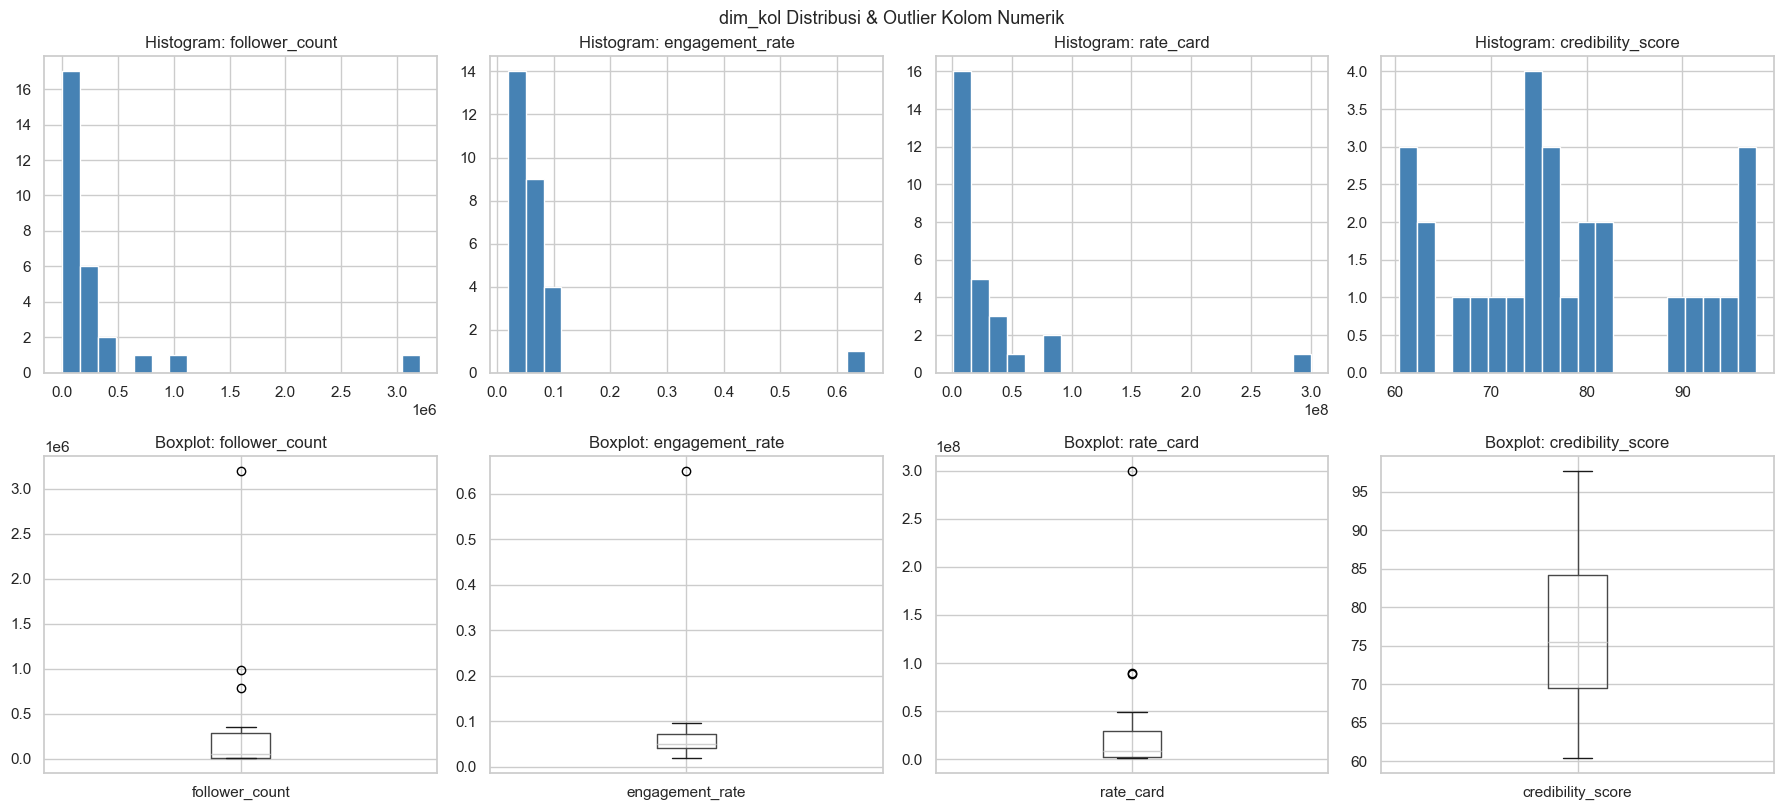

In [277]:
# Distribusi & Outlier kolom numerik
num_cols_kol = ['follower_count', 'engagement_rate', 'rate_card', 'credibility_score']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, col in enumerate(num_cols_kol):
    dim_kol[col].hist(ax=axes[0, i], bins=20, color='steelblue', edgecolor='white')
    axes[0, i].set_title(f'Histogram: {col}')
    dim_kol.boxplot(column=col, ax=axes[1, i])
    axes[1, i].set_title(f'Boxplot: {col}')
plt.tight_layout()
plt.suptitle('dim_kol Distribusi & Outlier Kolom Numerik', y=1.01, fontsize=13)
plt.show()

### 7.6 Outlier Analysis (IQR)

In [278]:
for col in num_cols_kol:
    Q1  = dim_kol[col].quantile(0.25)
    Q3  = dim_kol[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((dim_kol[col] < lower) | (dim_kol[col] > upper)).sum()
    print(f'{col:<20} | IQR [{lower:,.2f}, {upper:,.2f}] | Outlier: {n_out}')

follower_count       | IQR [-401,161.62, 691,565.38] | Outlier: 3
engagement_rate      | IQR [-0.00, 0.11] | Outlier: 1
rate_card            | IQR [-37,877,375.00, 69,453,625.00] | Outlier: 3
credibility_score    | IQR [47.60, 106.20] | Outlier: 0


### 7.7 Validasi Nilai

In [279]:
# engagement_rate dan credibility_score harus di rentang yang masuk akal
print('engagement_rate di luar [0, 1]:', ((dim_kol['engagement_rate'] < 0) | (dim_kol['engagement_rate'] > 1)).sum())
print('credibility_score di luar [0, 100]:', ((dim_kol['credibility_score'] < 0) | (dim_kol['credibility_score'] > 100)).sum())
print('follower_count negatif:', (dim_kol['follower_count'] < 0).sum())
print('rate_card negatif:', (dim_kol['rate_card'] < 0).sum())

engagement_rate di luar [0, 1]: 0
credibility_score di luar [0, 100]: 0
follower_count negatif: 0
rate_card negatif: 0


### 7.8 Cleaning dim_kol

In [280]:
dim_kol_clean = dim_kol.copy()

# 1. Strip whitespace pada semua kolom string
for col in dim_kol_clean.select_dtypes(include='object').columns:
    dim_kol_clean[col] = dim_kol_clean[col].str.strip()

# 2. Standardisasi kapital kategori 
for col in ['platform', 'niche', 'audience_gender_dominant', 'audience_age_group', 'kol_tier']:
    if col in dim_kol_clean.columns:
        dim_kol_clean[col] = dim_kol_clean[col].str.title()

# 3. Hapus duplicate 
before = len(dim_kol_clean)
dim_kol_clean.drop_duplicates(inplace=True)
print(f'Duplicate dihapus: {before - len(dim_kol_clean)} baris')

# Catatan: outlier pada follower_count dan rate_card TIDAK dihapus
# karena bisa mencerminkan perbedaan tier KOL yang valid (Nano, Micro, Macro, Mega)
print(f'Shape akhir: {dim_kol_clean.shape}')
print('dim_kol cleaning selesai ')

Duplicate dihapus: 0 baris
Shape akhir: (28, 12)
dim_kol cleaning selesai 


---
## 8. Analisis & Cleaning `dim_product`

Master data produk.

**Primary Key:** `product_id`

### 8.1 Gambaran Dataset

In [281]:
print('Shape :', dim_product.shape)
print()
dim_product.info()
display(dim_product.head())
display(dim_product.sample(min(5, len(dim_product)), random_state=42))

Shape : (40, 8)

<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   product_id         40 non-null     str    
 1   product_name       40 non-null     str    
 2   product_category   40 non-null     str    
 3   base_price         40 non-null     int64  
 4   margin_percentage  40 non-null     str    
 5   stock_status       40 non-null     str    
 6   launch_date        40 non-null     str    
 7   product_rating     40 non-null     float64
dtypes: float64(1), int64(1), str(6)
memory usage: 2.6 KB


,product_id,product_name,product_category,base_price,margin_percentage,stock_status,launch_date,product_rating
0,PRD001,Glow Serum 10%,Skincare,179000,0.54,In Stock,2023-03-09,4.7700
1,PRD002,Barrier Repair Moisturizer,Skincare,159000,0.52,In Stock,2024-08-11,4.6400
2,PRD003,Acne Calm Gel,Skincare,99000,0.5,In Stock,2024-01-26,4.5400
3,PRD004,Daily Sunscreen SPF50,Skincare,129000,0.48,Low Stock,2023-04-08,4.5800
4,PRD005,Retinol Night Cream,Skincare,219000,0.58,In Stock,2023-12-09,4.4600


,product_id,product_name,product_category,base_price,margin_percentage,stock_status,launch_date,product_rating
19,PRD020,Collagen Drink 7 Sachet,Wellness,229000,0.57,In Stock,2024-02-29,3.8000
16,PRD017,Hair Growth Tonic,Hair Care,169000,0.55,In Stock,2023-01-29,3.7000
15,PRD016,Body Serum Niacinamide,Body Care,149000,0.52,In Stock,2023-06-01,4.3900
26,PRD027,Sensitive Skin Kit,Bundle,389000,0.51,In Stock,2024-12-30,4.4400
4,PRD005,Retinol Night Cream,Skincare,219000,0.58,In Stock,2023-12-09,4.4600


### 8.2 Statistik Deskriptif

In [282]:
display(dim_product.describe(include='number'))

cat_cols_prd = dim_product.select_dtypes(include='object').columns.tolist()
for col in cat_cols_prd:
    if col not in ['product_id', 'product_name', 'launch_date']:
        print(f'\n{col} ({dim_product[col].nunique()} unique) ')
        print(dim_product[col].value_counts())

,base_price,product_rating
count,40.0000,40.0000
mean,"161,900.0000",4.2358
std,"94,004.8553",0.3107
min,"49,000.0000",3.6700
25%,"99,000.0000",3.9775
50%,"134,000.0000",4.3250
75%,"181,500.0000",4.4425
max,"459,000.0000",4.7700



product_category (9 unique) 
product_category
Skincare        11
Bundle           6
Body Care        5
Makeup           4
Hair Care        3
Wellness         3
Men Grooming     3
Family Care      3
Fragrance        2
Name: count, dtype: int64

margin_percentage (23 unique) 
margin_percentage
0.5       4
0.48      4
0.49      3
0.51      2
0.56      2
0.45      2
0.47      2
0.44      2
0.46      2
0.52      2
0.55      2
 0.51     2
0.54      1
 0.52     1
0.58      1
0.53      1
42.0%     1
0.57      1
0.6       1
0.43      1
0.41      1
0.39      1
0.34      1
Name: count, dtype: int64

stock_status (3 unique) 
stock_status
In Stock     34
Low Stock     3
Seasonal      3
Name: count, dtype: int64


In [283]:
# Cleaning kolom margin_percentage di dim_product
dim_product['margin_percentage'] = dim_product['margin_percentage'].astype(str)

# Hapus spasi dan karakter non-angka/koma/koma persen
dim_product['margin_percentage'] = dim_product['margin_percentage'].str.replace('%', '', regex=False)

# Konversi ke float
dim_product['margin_percentage'] = pd.to_numeric(dim_product['margin_percentage'], errors='coerce')

# Kalau sebelumnya ada persen, ubah ke decimal (misal 11.00 jadi 0.11)
# semua nilai yang awalnya ada tanda % harus dibagi 100
mask_percent = dim_product['margin_percentage'] > 1  # biasanya persen > 1
dim_product.loc[mask_percent, 'margin_percentage'] = dim_product.loc[mask_percent, 'margin_percentage'] / 100

# Cek hasil
print(dim_product[['margin_percentage']].head())


   margin_percentage
0             0.5400
1             0.5200
2             0.5000
3             0.4800
4             0.5800


### 8.3 Missing Value Analysis

In [284]:
mv = dim_product.isnull().sum()
mv_pct = (mv / len(dim_product) * 100).round(2)
mv_df = pd.DataFrame({'missing_count': mv, 'missing_pct': mv_pct})
mv_df = mv_df[mv_df['missing_count'] > 0]
if mv_df.empty:
    print(' Tidak ada missing value pada dim_product')
else:
    display(mv_df)

 Tidak ada missing value pada dim_product


### 8.4 Duplicate Analysis

In [285]:
print(f'Duplicate rows      : {dim_product.duplicated().sum()}')
print(f'Duplicate product_id: {dim_product.duplicated(subset=["product_id"]).sum()}')

Duplicate rows      : 0
Duplicate product_id: 0


### 8.5 Unique Value Analysis

In [286]:
print('Jumlah unique per kolom:')
print(dim_product.nunique())

for col in ['product_category', 'stock_status']:
    print(f'\nUnique [{col}] ')
    print(dim_product[col].value_counts())

Jumlah unique per kolom:
product_id           40
product_name         40
product_category      9
base_price           24
margin_percentage    21
stock_status          3
launch_date          40
product_rating       34
dtype: int64

Unique [product_category] 
product_category
Skincare        11
Bundle           6
Body Care        5
Makeup           4
Hair Care        3
Wellness         3
Men Grooming     3
Family Care      3
Fragrance        2
Name: count, dtype: int64

Unique [stock_status] 
stock_status
In Stock     34
Low Stock     3
Seasonal      3
Name: count, dtype: int64


### 8.6 Validasi Nilai

In [287]:
# Harga tidak boleh negatif
print('base_price negatif:', (dim_product['base_price'] < 0).sum())
print('margin_percentage negatif:', (dim_product['margin_percentage'] < 0).sum())
print('product_rating di luar [0, 5]:', ((dim_product['product_rating'] < 0) | (dim_product['product_rating'] > 5)).sum())

# Validasi launch_date
launch_parsed = pd.to_datetime(dim_product['launch_date'], errors='coerce')
print(f'launch_date tidak valid: {launch_parsed.isna().sum()}')
print(f'Rentang launch_date: {launch_parsed.min()} → {launch_parsed.max()}')

base_price negatif: 0
margin_percentage negatif: 0
product_rating di luar [0, 5]: 0
launch_date tidak valid: 0
Rentang launch_date: 2023-01-29 00:00:00 → 2025-01-07 00:00:00


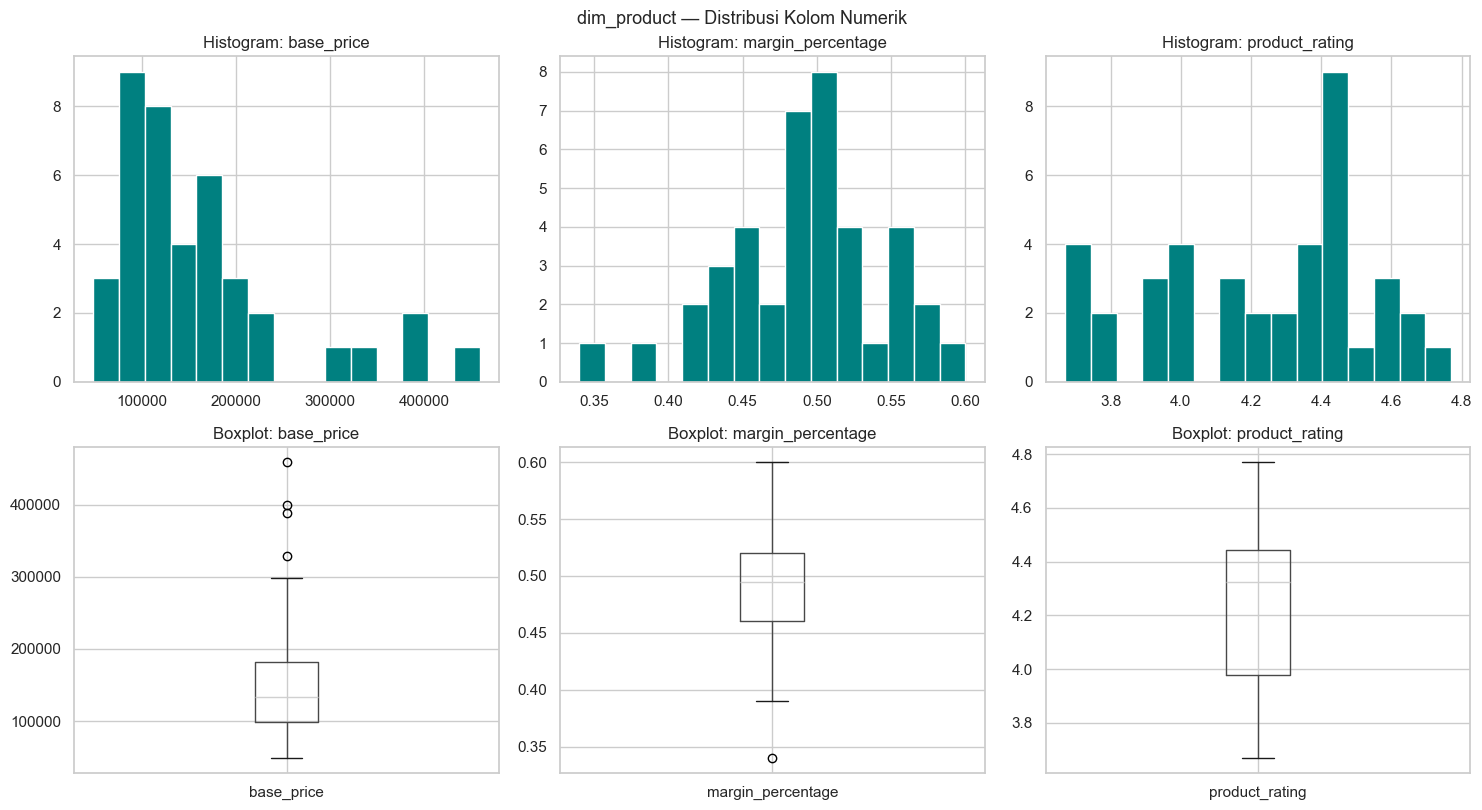

In [288]:
# Distribusi kolom numerik
num_cols_prd = ['base_price', 'margin_percentage', 'product_rating']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(num_cols_prd):
    dim_product[col].hist(ax=axes[0, i], bins=15, color='teal', edgecolor='white')
    axes[0, i].set_title(f'Histogram: {col}')
    dim_product.boxplot(column=col, ax=axes[1, i])
    axes[1, i].set_title(f'Boxplot: {col}')
plt.tight_layout()
plt.suptitle('dim_product — Distribusi Kolom Numerik', y=1.01, fontsize=13)
plt.show()

### 8.7 Cleaning dim_product

In [289]:
dim_product_clean = dim_product.copy()

# 1. Strip whitespace pada semua kolom string
for col in dim_product_clean.select_dtypes(include='object').columns:
    dim_product_clean[col] = dim_product_clean[col].str.strip()

# 2. Konversi margin_percentage yang mungkin punya spasi
dim_product_clean['margin_percentage'] = pd.to_numeric(
    dim_product_clean['margin_percentage'].astype(str).str.strip(), errors='coerce'
)

# 3. Konversi launch_date ke datetime
dim_product_clean['launch_date'] = pd.to_datetime(dim_product_clean['launch_date'], errors='coerce')

# 4. Standardisasi kapital kategori 
for col in ['product_category', 'stock_status']:
    if col in dim_product_clean.columns:
        dim_product_clean[col] = dim_product_clean[col].str.title()

# 5. Hapus duplicate 
before = len(dim_product_clean)
dim_product_clean.drop_duplicates(inplace=True)
print(f'Duplicate dihapus: {before - len(dim_product_clean)} baris')

print(f'Shape akhir: {dim_product_clean.shape}')
display(dim_product_clean.head())
print('dim_product cleaning selesai ')

Duplicate dihapus: 0 baris
Shape akhir: (40, 8)


,product_id,product_name,product_category,base_price,margin_percentage,stock_status,launch_date,product_rating
0,PRD001,Glow Serum 10%,Skincare,179000,0.5400,In Stock,2023-03-09,4.7700
1,PRD002,Barrier Repair Moisturizer,Skincare,159000,0.5200,In Stock,2024-08-11,4.6400
2,PRD003,Acne Calm Gel,Skincare,99000,0.5000,In Stock,2024-01-26,4.5400
3,PRD004,Daily Sunscreen SPF50,Skincare,129000,0.4800,Low Stock,2023-04-08,4.5800
4,PRD005,Retinol Night Cream,Skincare,219000,0.5800,In Stock,2023-12-09,4.4600


dim_product cleaning selesai 


---
## 9. Analisis & Cleaning `dim_customer`

Master data pelanggan sintetis.

**Primary Key:** `customer_id`

### 9.1 Gambaran Dataset

In [290]:
print('Shape :', dim_customer.shape)
print()
dim_customer.info()
display(dim_customer.head(5))
display(dim_customer.sample(5, random_state=42))

Shape : (15000, 12)

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             15000 non-null  str    
 1   customer_name           15000 non-null  str    
 2   email_hash              15000 non-null  str    
 3   gender                  14150 non-null  str    
 4   age                     14479 non-null  float64
 5   age_group               15000 non-null  str    
 6   city                    14328 non-null  str    
 7   province                15000 non-null  str    
 8   customer_segment        15000 non-null  str    
 9   acquisition_channel_id  15000 non-null  str    
 10  first_purchase_date     12334 non-null  str    
 11  loyalty_status          8451 non-null   str    
dtypes: float64(1), str(11)
memory usage: 1.4 MB


,customer_id,customer_name,email_hash,gender,age,age_group,city,province,customer_segment,acquisition_channel_id,first_purchase_date,loyalty_status
0,CUS000001,Citra Saputra,hash_64946979,Female,20.0000,18-24,Malang,Jawa Timur,At Risk,CH001,2025-03-04,Silver
1,CUS000002,Ayu Santoso,hash_48803585,Wanita,20.0000,18-24,Bekasi,Jawa Barat,Returning Customer,CH012,2025-02-12,NaN
2,CUS000003,Siti Wijaya,hash_46294622,Wanita,37.0000,35-44,NaN,Jawa Timur,New Customer,CH001,NaN,NaN
3,CUS000004,Putri Utami,hash_61097103,Female,30.0000,25-34,Jakarta,DKI Jakarta,Returning Customer,CH001,2025-02-09,Silver
4,CUS000005,Citra Pratama,hash_48361977,F,53.0000,45-54,Jakarta,DKI Jakarta,Returning Customer,CH003,2025-07-14,Platinum


,customer_id,customer_name,email_hash,gender,age,age_group,city,province,customer_segment,acquisition_channel_id,first_purchase_date,loyalty_status
11499,CUS011500,Siti Saputra,hash_55170438,female,NaN,Unknown,Tangerang,Banten,Discount Seeker,CH001,2025-03-31,Gold
6475,CUS006476,Nadia Santoso,hash_37426271,F,18.0000,18-24,Medan,Sumatera Utara,Loyal Customer,CH002,2025-05-02,NaN
13167,CUS013168,Niko Saputra,hash_94317959,M,31.0000,25-34,Malang,Jawa Timur,Loyal Customer,CH006,2025-05-25,Gold
862,CUS000863,Budi Santoso,hash_83195593,Male,30.0000,25-34,Surabaya,Jawa Timur,At Risk,CH001,2025-06-04,NaN
5970,CUS005971,Fitri Utami,hash_34074469,Wanita,40.0000,35-44,Balikpapan,Kalimantan Timur,Discount Seeker,CH006,2025-01-13,NaN


### 9.2 Statistik Deskriptif

In [291]:
display(dim_customer.describe(include='number'))

cat_cols_cus = dim_customer.select_dtypes(include='object').columns.tolist()
for col in cat_cols_cus:
    if col not in ['customer_id', 'customer_name', 'email_hash', 'first_purchase_date']:
        print(f'\n{col} ({dim_customer[col].nunique()} unique) ')
        print(dim_customer[col].value_counts())

,age
count,"14,479.0000"
mean,29.7111
std,9.1773
min,-5.0000
25%,23.0000
50%,29.0000
75%,36.0000
max,150.0000



gender (10 unique) 
gender
Female       3416
Perempuan    1775
Wanita       1632
Male         1614
female       1437
F            1339
Laki-laki     831
Pria          779
male          667
M             660
Name: count, dtype: int64

age_group (8 unique) 
age_group
25-34      6037
35-44      3440
18-24      2923
<18        1314
45-54       692
Unknown     520
55+          50
Invalid      24
Name: count, dtype: int64

city (26 unique) 
city
Jakarta            3685
Bandung            1228
Surabaya           1209
Bekasi             1167
Depok               858
Tangerang           857
Bogor               852
Semarang            737
Yogyakarta          662
Malang              589
Medan               561
Palembang           318
Makassar            277
Jakarta Selatan     161
 jakarta            159
JKT                 159
Balikpapan          153
DKI Jakarta         147
Denpasar            144
SBY                  78
surabaya             63
bandung              60
BDG                  59
DIY

### 9.3 Missing Value Analysis

,missing_count,missing_pct
gender,850,5.6700
age,521,3.4700
city,672,4.4800
first_purchase_date,2666,17.7700
loyalty_status,6549,43.6600


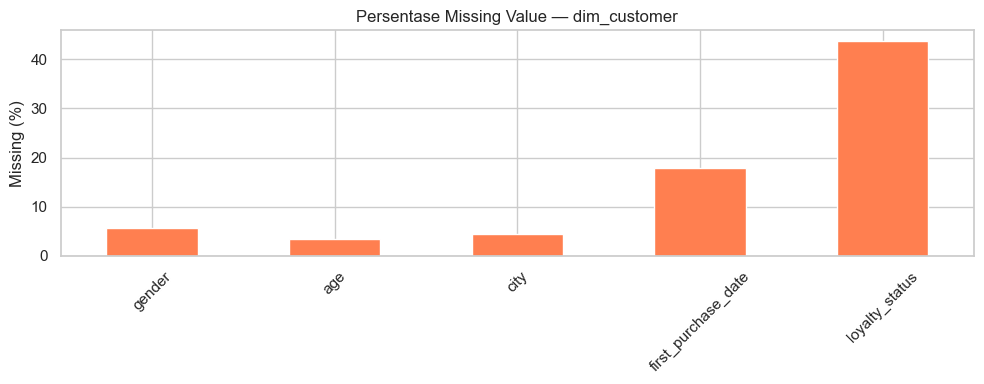

In [292]:
mv = dim_customer.isnull().sum()
mv_pct = (mv / len(dim_customer) * 100).round(2)
mv_df = pd.DataFrame({'missing_count': mv, 'missing_pct': mv_pct})
mv_df = mv_df[mv_df['missing_count'] > 0]
if mv_df.empty:
    print(' Tidak ada missing value pada dim_customer')
else:
    display(mv_df)
    # Visualisasi missing value
    mv_df['missing_pct'].plot(kind='bar', figsize=(10, 4), color='coral', edgecolor='white')
    plt.title('Persentase Missing Value — dim_customer')
    plt.ylabel('Missing (%)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### 9.4 Duplicate Analysis

In [293]:
print(f'Duplicate rows        : {dim_customer.duplicated().sum()}')
print(f'Duplicate customer_id : {dim_customer.duplicated(subset=["customer_id"]).sum()}')

Duplicate rows        : 0
Duplicate customer_id : 0


### 9.5 Unique Value & Inkonsistensi Kategori

In [294]:
print('Jumlah unique per kolom:')
print(dim_customer.nunique())

# Cek inkonsistensi gender secara detail
print('\nUnique [gender] (sebelum cleaning) ')
print(dim_customer['gender'].value_counts(dropna=False))

# Cek kolom lain
for col in ['age_group', 'customer_segment', 'loyalty_status']:
    print(f'\nUnique [{col}] ')
    print(dim_customer[col].value_counts(dropna=False))

Jumlah unique per kolom:
customer_id               15000
customer_name               260
email_hash                14920
gender                       10
age                          53
age_group                     8
city                         26
province                     22
customer_segment              6
acquisition_channel_id       12
first_purchase_date         730
loyalty_status                4
dtype: int64

Unique [gender] (sebelum cleaning) 
gender
Female       3416
Perempuan    1775
Wanita       1632
Male         1614
female       1437
F            1339
NaN           850
Laki-laki     831
Pria          779
male          667
M             660
Name: count, dtype: int64

Unique [age_group] 
age_group
25-34      6037
35-44      3440
18-24      2923
<18        1314
45-54       692
Unknown     520
55+          50
Invalid      24
Name: count, dtype: int64

Unique [customer_segment] 
customer_segment
New Customer          5282
Returning Customer    3720
Discount Seeker       1875

### 9.6 Distribusi & Outlier Kolom Numerik

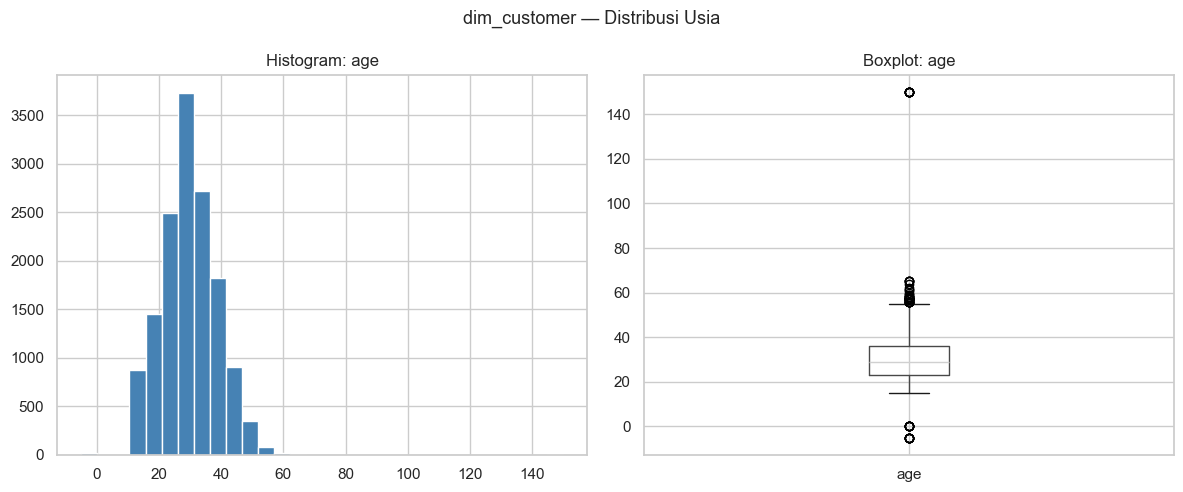

Usia negatif       : 8
Usia > 120         : 8
Usia min-max       : -5.0 — 150.0


In [295]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
dim_customer['age'].hist(ax=axes[0], bins=30, color='steelblue', edgecolor='white')
axes[0].set_title('Histogram: age')
dim_customer.boxplot(column='age', ax=axes[1])
axes[1].set_title('Boxplot: age')
plt.suptitle('dim_customer — Distribusi Usia', fontsize=13)
plt.tight_layout()
plt.show()

print(f'Usia negatif       : {(dim_customer["age"] < 0).sum()}')
print(f'Usia > 120         : {(dim_customer["age"] > 120).sum()}')
print(f'Usia min-max       : {dim_customer["age"].min()} — {dim_customer["age"].max()}')

In [296]:
# Filter rows dengan usia negatif atau lebih dari 120
anomali_age = dim_customer[(dim_customer['age'] < 0) | (dim_customer['age'] > 120)]

print(anomali_age)


      customer_id  customer_name     email_hash     gender      age age_group             city          province    customer_segment acquisition_channel_id first_purchase_date loyalty_status
65      CUS000066    Ayu Nugroho  hash_38010079  Perempuan 150.0000   Invalid        Tangerang            Banten        New Customer                  CH008                 NaN         Bronze
1225    CUS001226   Rani Nugroho  hash_33948104  Perempuan 150.0000   Invalid          Jakarta       DKI Jakarta  Returning Customer                  CH007          2024-02-21            NaN
1712    CUS001713   Dimas Wijaya  hash_74323881       Male 150.0000   Invalid       Yogyakarta               DIY  Returning Customer                  CH002          2025-11-03           Gold
2213    CUS002214   Rani Santoso  hash_52751630     Female  -5.0000   Invalid          Jakarta       DKI Jakarta     Discount Seeker                  CH002          2025-09-09            NaN
2913    CUS002914   Siti Permata  hash_625146

### 9.7 Validasi Nilai

In [297]:
# Validasi first_purchase_date
fp_parsed = pd.to_datetime(dim_customer['first_purchase_date'], errors='coerce')
print(f'first_purchase_date tidak valid: {fp_parsed.isna().sum()}')
print(f'Rentang first_purchase_date: {fp_parsed.min()} → {fp_parsed.max()}')

first_purchase_date tidak valid: 2666
Rentang first_purchase_date: 2024-01-01 00:00:00 → 2025-12-30 00:00:00


ini first_purchase_date ga validnya cuma karena null, bukan ada value aneh lain

In [298]:
# Rows invalid (NaT)
invalid_fp = dim_customer[fp_parsed.isna()]

# Bedakan null vs format salah
null_rows = dim_customer[dim_customer['first_purchase_date'].isna()]
format_salah_rows = invalid_fp[~invalid_fp['first_purchase_date'].isna()]

print("Null rows:")
print(null_rows)

print("\nFormat salah rows:")
print(format_salah_rows)


Null rows:
      customer_id  customer_name     email_hash     gender     age age_group      city        province customer_segment acquisition_channel_id first_purchase_date loyalty_status
2       CUS000003    Siti Wijaya  hash_46294622     Wanita 37.0000     35-44       NaN      Jawa Timur     New Customer                  CH001                 NaN            NaN
11      CUS000012     Niko Utami  hash_63304744  Laki-laki 22.0000     18-24   Jakarta     DKI Jakarta     New Customer                  CH005                 NaN         Bronze
20      CUS000021  Tasya Nugroho  hash_69944706  Perempuan 33.0000     25-34    Bekasi      Jawa Barat     New Customer                  CH003                 NaN         Silver
28      CUS000029      Aldi Sari  hash_59953805          M 26.0000     25-34       NaN      Jawa Timur     New Customer                  CH001                 NaN         Bronze
29      CUS000030   Niko Pratama  hash_54732325  Laki-laki 34.0000     25-34    Malang      Jawa Ti

### 9.8 Cleaning dim_customer

In [299]:
display(dim_customer.describe(include='number'))

cat_cols_cus = dim_customer.select_dtypes(include='object').columns.tolist()
for col in cat_cols_cus:
    if col not in ['customer_id', 'customer_name', 'email_hash', 'first_purchase_date']:
        print(f'\n{col} ({dim_customer[col].nunique()} unique) ')
        print(dim_customer[col].value_counts())

,age
count,"14,479.0000"
mean,29.7111
std,9.1773
min,-5.0000
25%,23.0000
50%,29.0000
75%,36.0000
max,150.0000



gender (10 unique) 
gender
Female       3416
Perempuan    1775
Wanita       1632
Male         1614
female       1437
F            1339
Laki-laki     831
Pria          779
male          667
M             660
Name: count, dtype: int64

age_group (8 unique) 
age_group
25-34      6037
35-44      3440
18-24      2923
<18        1314
45-54       692
Unknown     520
55+          50
Invalid      24
Name: count, dtype: int64

city (26 unique) 
city
Jakarta            3685
Bandung            1228
Surabaya           1209
Bekasi             1167
Depok               858
Tangerang           857
Bogor               852
Semarang            737
Yogyakarta          662
Malang              589
Medan               561
Palembang           318
Makassar            277
Jakarta Selatan     161
 jakarta            159
JKT                 159
Balikpapan          153
DKI Jakarta         147
Denpasar            144
SBY                  78
surabaya             63
bandung              60
BDG                  59
DIY

In [300]:
# Menandai usia yang tidak valid menjadi missing value
dim_customer.loc[
    (dim_customer["age"] < 0) |
    (dim_customer["age"] > 120),
    "age"
] = np.nan

In [301]:
# Filter rows dengan usia negatif atau lebih dari 120
anomali_age = dim_customer[(dim_customer['age'] < 0) | (dim_customer['age'] > 120)]

print(anomali_age)


Empty DataFrame
Columns: [customer_id, customer_name, email_hash, gender, age, age_group, city, province, customer_segment, acquisition_channel_id, first_purchase_date, loyalty_status]
Index: []


cleaning city dan province

In [302]:
# -------------------------
# Standardisasi City
# -------------------------
city_mapping = {
    "Jkt": "Jakarta",
    "JKT": "Jakarta",
    "Dki Jakarta": "Jakarta",
    "DKI Jakarta": "Jakarta",
    " jakarta ": "Jakarta",
    "Bdg": "Bandung",
    "bandung": "Bandung",
    "BDG": "Bandung",
    "Kota Bandung": "Bandung",
    "Sby": "Surabaya",
    "SBY": "Surabaya",
    "surabaya": "Surabaya",
    "Jogja": "Yogyakarta",
    "DIY": "Yogyakarta"
}

dim_customer["city"] = (
    dim_customer["city"]
    .replace(city_mapping)
    .fillna("Unknown")
)

# -------------------------
# Standardisasi Province
# -------------------------
province_mapping = {
    "West Java": "Jawa Barat",
    "Jabar": "Jawa Barat",

    "East Java": "Jawa Timur",
    "Jatim": "Jawa Timur",

    "Central Java": "Jawa Tengah",
    "Jateng": "Jawa Tengah",

    "Jakarta": "DKI Jakarta",
    "Dki Jakarta": "DKI Jakarta",
    " dki jakarta ": "DKI Jakarta",
    "Dki Jkt": "DKI Jakarta",
    "DKI JKT": "DKI Jakarta",

    "DIY": "DI Yogyakarta",
    "Diy": "DI Yogyakarta",
    "Yogyakarta": "DI Yogyakarta"
}

dim_customer["province"] = dim_customer["province"].replace(province_mapping)

# =============================================================================
# VERIFIKASI HASIL CLEANING
# =============================================================================

print("="*70)
print("CITY")
print("="*70)
print(dim_customer["city"].value_counts(dropna=False))
print(f"\nJumlah kategori city : {dim_customer['city'].nunique()}")

print("\n" + "="*70)
print("PROVINCE")
print("="*70)
print(dim_customer["province"].value_counts(dropna=False))
print(f"\nJumlah kategori province : {dim_customer['province'].nunique()}")


CITY
city
Jakarta            4150
Bandung            1395
Surabaya           1350
Bekasi             1167
Depok               858
Tangerang           857
Bogor               852
Yogyakarta          759
Semarang            737
Unknown             672
Malang              589
Medan               561
Palembang           318
Makassar            277
Jakarta Selatan     161
Balikpapan          153
Denpasar            144
Name: count, dtype: int64

Jumlah kategori city : 17

PROVINCE
province
DKI Jakarta         4524
Jawa Barat          4471
Jawa Timur          2035
Banten               891
DI Yogyakarta        783
Jawa Tengah          768
Sumatera Utara       588
Sumatera Selatan     334
Sulawesi Selatan     288
Kalimantan Timur     160
Bali                 158
Name: count, dtype: int64

Jumlah kategori province : 11


loyalty_status null diganti unknown

In [303]:
dim_customer["loyalty_status"] = (
    dim_customer["loyalty_status"]
    .fillna("Unknown")
)

kolom first_purchase_date:
Ubah tipe data menjadi datetime.
Biarkan nilai yang kosong tetap NaT (NaN untuk datetime).

In [304]:
dim_customer["first_purchase_date"] = pd.to_datetime(
    dim_customer["first_purchase_date"],
    errors="coerce"
)

In [305]:
# Cek jumlah nilai null per kolom
null_counts = dim_customer.isna().sum()

print("Jumlah nilai null per kolom:")
print(null_counts)

# lihat kolom mana saja yang punya null
print("\nKolom dengan nilai null:")
print(null_counts[null_counts > 0])

Jumlah nilai null per kolom:
customer_id                  0
customer_name                0
email_hash                   0
gender                     850
age                        537
age_group                    0
city                         0
province                     0
customer_segment             0
acquisition_channel_id       0
first_purchase_date       2666
loyalty_status               0
dtype: int64

Kolom dengan nilai null:
gender                  850
age                     537
first_purchase_date    2666
dtype: int64


In [306]:
dim_customer_clean = dim_customer.copy()

# 1. Strip whitespace pada semua kolom string
for col in dim_customer_clean.select_dtypes(include='object').columns:
    dim_customer_clean[col] = dim_customer_clean[col].str.strip()

# 2. Standardisasi gender
# Alasan: Ditemukan inkonsistensi: 'Wanita', 'Female', 'Pria', 'Male', 'M', 'L', dll.
# Standardisasi ke 'Male' / 'Female' / 'Unknown'
gender_map = {
    'female'   : 'Female',  'wanita'   : 'Female',  'perempuan': 'Female',
    'f'        : 'Female',  'pr'       : 'Female',
    'male'     : 'Male',    'pria'     : 'Male',     'laki-laki': 'Male',
    'm'        : 'Male',    'lk'       : 'Male',     'l'        : 'Male',
}
dim_customer_clean['gender'] = (
    dim_customer_clean['gender']
    .str.lower()
    .str.strip()
    .map(gender_map)
    .fillna('Unknown')
)

# 3. Standardisasi loyalty_status
# Alasan: Pastikan nilai None yang bukan NaN diidentifikasi
dim_customer_clean['loyalty_status'] = dim_customer_clean['loyalty_status'].replace('None', np.nan)


# 5. Standardisasi kolom kategorikal 
for col in ['age_group', 'customer_segment', 'loyalty_status', 'city', 'province']:
    if col in dim_customer_clean.columns:
        dim_customer_clean[col] = dim_customer_clean[col].str.strip().str.title()

# 6. Hapus duplicate 
before = len(dim_customer_clean)
dim_customer_clean.drop_duplicates(inplace=True)
print(f'Duplicate dihapus: {before - len(dim_customer_clean)} baris')

print(f'\nShape akhir: {dim_customer_clean.shape}')
print('\nDistribusi gender setelah cleaning:')
print(dim_customer_clean['gender'].value_counts(dropna=False))

Duplicate dihapus: 0 baris

Shape akhir: (15000, 12)

Distribusi gender setelah cleaning:
gender
Female     9599
Male       4551
Unknown     850
Name: count, dtype: int64


In [307]:
# after cleaning

# Cek jumlah nilai null per kolom
null_counts = dim_customer_clean.isna().sum()

print("Jumlah nilai null per kolom:")
print(null_counts)

# lihat kolom mana saja yang punya null
print("\nKolom dengan nilai null:")
print(null_counts[null_counts > 0])

Jumlah nilai null per kolom:
customer_id                  0
customer_name                0
email_hash                   0
gender                       0
age                        537
age_group                    0
city                         0
province                     0
customer_segment             0
acquisition_channel_id       0
first_purchase_date       2666
loyalty_status               0
dtype: int64

Kolom dengan nilai null:
age                     537
first_purchase_date    2666
dtype: int64


In [308]:
# after cleaning
print('Jumlah unique per kolom:')
print(dim_customer.nunique())

# Cek inkonsistensi gender secara detail
print('\nUnique [gender] (sebelum cleaning) ')
print(dim_customer_clean['gender'].value_counts(dropna=False))

# Cek kolom lain
for col in ['age_group', 'customer_segment', 'loyalty_status']:
    print(f'\nUnique [{col}] ')
    print(dim_customer_clean[col].value_counts(dropna=False))

Jumlah unique per kolom:
customer_id               15000
customer_name               260
email_hash                14920
gender                       10
age                          51
age_group                     8
city                         17
province                     11
customer_segment              6
acquisition_channel_id       12
first_purchase_date         730
loyalty_status                5
dtype: int64

Unique [gender] (sebelum cleaning) 
gender
Female     9599
Male       4551
Unknown     850
Name: count, dtype: int64

Unique [age_group] 
age_group
25-34      6037
35-44      3440
18-24      2923
<18        1314
45-54       692
Unknown     520
55+          50
Invalid      24
Name: count, dtype: int64

Unique [customer_segment] 
customer_segment
New Customer          5282
Returning Customer    3720
Discount Seeker       1875
Loyal Customer        1514
At Risk               1445
High Value            1164
Name: count, dtype: int64

Unique [loyalty_status] 
loyalty_status
U

---
## 10. Analisis & Cleaning — `fact_marketing_daily`

Data performa pemasaran harian.

**Grain:** satu baris = satu kombinasi `date_id × channel_id × campaign_id × ad_id`  
**Foreign Keys:** `date_id`, `channel_id`, `campaign_id`, `ad_id`, `kol_id`

### 10.1 Gambaran Dataset

In [309]:
print('Shape :', fact_marketing_daily.shape)
print()
fact_marketing_daily.info()
display(fact_marketing_daily.head(5))
display(fact_marketing_daily.sample(5, random_state=42))

Shape : (15849, 22)

<class 'pandas.DataFrame'>
RangeIndex: 15849 entries, 0 to 15848
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   date_id          15849 non-null  int64  
 1   channel_id       15849 non-null  str    
 2   campaign_id      15849 non-null  str    
 3   ad_id            15849 non-null  str    
 4   kol_id           1659 non-null   str    
 5   impressions      15849 non-null  int64  
 6   reach            15849 non-null  int64  
 7   clicks           15849 non-null  int64  
 8   spend            15849 non-null  float64
 9   video_views      15849 non-null  int64  
 10  likes            15849 non-null  int64  
 11  comments         15849 non-null  int64  
 12  shares           15849 non-null  int64  
 13  saves            15849 non-null  int64  
 14  leads            15849 non-null  int64  
 15  sessions         15849 non-null  int64  
 16  add_to_cart      15849 non-null  int64  
 17  ch

,date_id,channel_id,campaign_id,ad_id,kol_id,impressions,reach,clicks,spend,video_views,likes,comments,shares,saves,leads,sessions,add_to_cart,checkout,purchases,revenue,discount_amount,refund_amount
0,20250105,CH001,CMP0001,AD00001,NaN,51989,18219,744,"5,989,440.7000",20186,777,13,22,61,7,694,121,56,32,"-7,926,625.0000",0.0000,0.0000
1,20250106,CH001,CMP0001,AD00001,NaN,41602,11314,703,"4,937,344.8400",17243,305,17,8,7,15,653,155,75,37,"7,364,592.4200",0.0000,"301,269.9100"
2,20250107,CH001,CMP0001,AD00001,NaN,83970,21353,1168,"6,306,927.3000",48094,933,34,39,48,8,903,205,94,50,"11,767,343.0100",0.0000,"492,903.6400"
3,20250110,CH001,CMP0001,AD00001,NaN,58535,32826,890,"5,674,539.5400",17526,839,42,60,40,19,744,124,59,24,"4,724,332.0000",0.0000,"199,879.3800"
4,20250111,CH001,CMP0001,AD00001,NaN,76151,48318,845,"5,481,047.3800",14940,573,28,51,48,32,693,138,57,32,"6,399,578.8300",0.0000,0.0000


,date_id,channel_id,campaign_id,ad_id,kol_id,impressions,reach,clicks,spend,video_views,likes,comments,shares,saves,leads,sessions,add_to_cart,checkout,purchases,revenue,discount_amount,refund_amount
14503,20250807,CH012,CMP0057,AD00177,NaN,191,50,1,"3,684.3200",0,1,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000
14077,20250702,CH007,CMP0054,AD00170,NaN,1167,519,26,"27,503.0200",0,6,0,0,0,1,19,4,2,1,"315,789.8600",0.0000,"26,993.3600"
13856,20250829,CH011,CMP0053,AD00168,NaN,16755,5245,603,"2,098,365.4200",0,240,7,7,5,14,379,167,63,46,"8,411,037.3200","1,225,549.6700","438,238.8800"
5928,20250731,CH006,CMP0012,AD00040,NaN,621,271,342,"302,724.9500",0,5,0,0,0,4,262,95,59,43,"11,369,121.3200",0.0000,"880,804.9500"
14402,20250515,CH012,CMP0056,AD00175,NaN,2293,781,0,625.2100,0,14,0,0,1,0,0,0,0,0,0.0000,0.0000,0.0000


### 10.2 Statistik Deskriptif

In [310]:
display(fact_marketing_daily.describe())

,date_id,impressions,reach,clicks,spend,video_views,likes,comments,shares,saves,leads,sessions,add_to_cart,checkout,purchases,revenue,discount_amount,refund_amount
count,"15,849.0000","15,849.0000","15,849.0000","15,849.0000","15,849.0000","15,849.0000","15,849.0000","15,849.0000","15,849.0000","15,849.0000","15,849.0000","15,849.0000","15,849.0000","15,849.0000","15,849.0000","15,849.0000","15,849.0000","15,849.0000"
mean,"20,250,708.0101","51,812.5563","22,548.8497",492.2552,"1,861,612.4372","17,223.7602","1,161.9761",51.0538,79.4554,63.9335,11.9449,366.5280,78.1892,32.2376,14.9515,"3,304,434.6781","271,629.7573","97,026.0274"
std,318.6787,"229,934.5201","107,115.4481","1,272.4198","2,768,054.2832","106,084.9817","6,941.3089",312.1498,506.6235,377.1398,26.1410,761.0736,147.9330,67.8923,31.0429,"6,587,305.0186","835,793.1670","336,639.3098"
min,"20,250,101.0000",0.0000,9.0000,0.0000,"-7,747,932.4600",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,"-8,729,483.6500",0.0000,0.0000
25%,"20,250,424.0000","2,251.0000",848.0000,46.0000,"45,999.3900",0.0000,21.0000,0.0000,1.0000,0.0000,1.0000,34.0000,8.0000,4.0000,2.0000,"476,558.2500",0.0000,0.0000
50%,"20,250,720.0000","5,623.0000","2,374.0000",201.0000,"1,255,275.3700",0.0000,60.0000,2.0000,3.0000,3.0000,4.0000,150.0000,36.0000,16.0000,6.0000,"1,479,610.3700",0.0000,0.0000
75%,"20,251,005.0000","36,625.0000","14,401.0000",567.0000,"2,519,004.4600","6,588.0000",371.0000,15.0000,23.0000,19.0000,12.0000,430.0000,95.0000,38.0000,18.0000,"4,108,188.1100","247,024.7900","88,512.3600"
max,"20,251,231.0000","11,230,855.0000","3,859,259.0000","88,498.0000","116,709,285.0649","6,401,198.0000","360,344.0000","15,419.0000","18,760.0000","17,813.0000",617.0000,"23,478.0000","4,058.0000","2,263.0000",732.0000,"170,407,033.4000","29,245,530.7300","11,055,372.1600"


### 10.3 Missing Value Analysis

kol_id boleh kosong karena hanya digunakan pada kampanye KOL

,missing_count,missing_pct
kol_id,14190,89.5300


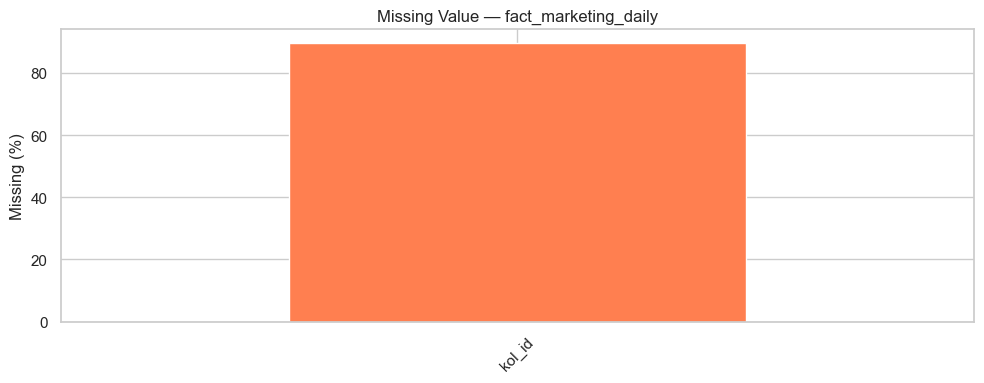

In [311]:
mv = fact_marketing_daily.isnull().sum()
mv_pct = (mv / len(fact_marketing_daily) * 100).round(2)
mv_df = pd.DataFrame({'missing_count': mv, 'missing_pct': mv_pct})
mv_df = mv_df[mv_df['missing_count'] > 0]
if mv_df.empty:
    print(' Tidak ada missing value pada fact_marketing_daily')
else:
    display(mv_df)
    # Catatan: kol_id boleh kosong karena hanya digunakan pada kampanye KOL
    mv_df['missing_pct'].plot(kind='bar', color='coral', edgecolor='white', figsize=(10, 4))
    plt.title('Missing Value — fact_marketing_daily')
    plt.ylabel('Missing (%)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### 10.4 Duplicate Analysis

In [312]:
grain_cols = ['date_id', 'channel_id', 'campaign_id', 'ad_id']
dup_grain  = fact_marketing_daily.duplicated(subset=grain_cols).sum()
print(f'Duplicate rows                  : {fact_marketing_daily.duplicated().sum()}')
print(f'Duplicate grain (date+ch+cmp+ad): {dup_grain}')
if dup_grain > 0:
    display(fact_marketing_daily[fact_marketing_daily.duplicated(subset=grain_cols, keep=False)].head(10))

Duplicate rows                  : 0
Duplicate grain (date+ch+cmp+ad): 0


### 10.5 Business Rule Validation

In [313]:
num_cols_mkt = ['impressions', 'reach', 'clicks', 'spend', 'video_views',
                'likes', 'comments', 'shares', 'saves', 'leads',
                'sessions', 'add_to_cart', 'checkout', 'purchases',
                'revenue', 'discount_amount', 'refund_amount']

print('Nilai negatif per kolom:')
for col in num_cols_mkt:
    neg = (fact_marketing_daily[col] < 0).sum()
    if neg > 0:
        print(f'  {col:<20} : {neg:,}')
    else:
        print(f'  {col:<20} :  0')

# CTR (clicks / impressions) — validasi
fmd = fact_marketing_daily.copy()
fmd['ctr_check'] = np.where(fmd['impressions'] > 0, fmd['clicks'] / fmd['impressions'], np.nan)
print(f'\nCTR > 1 (>100%) : {(fmd["ctr_check"] > 1).sum()}')
print(f'CTR < 0         : {(fmd["ctr_check"] < 0).sum()}')

# Conversion rate (purchases / clicks)
fmd['cvr_check'] = np.where(fmd['clicks'] > 0, fmd['purchases'] / fmd['clicks'], np.nan)
print(f'CVR > 1 (>100%) : {(fmd["cvr_check"] > 1).sum()}')

Nilai negatif per kolom:
  impressions          :  0
  reach                :  0
  clicks               :  0
  spend                : 13
  video_views          :  0
  likes                :  0
  comments             :  0
  shares               :  0
  saves                :  0
  leads                :  0
  sessions             :  0
  add_to_cart          :  0
  checkout             :  0
  purchases            :  0
  revenue              : 12
  discount_amount      :  0
  refund_amount        :  0

CTR > 1 (>100%) : 20
CTR < 0         : 0
CVR > 1 (>100%) : 8


In [314]:
# Cek nilai unik yang negatif per kolom
print("Nilai negatif unik per kolom:")
for col in num_cols_mkt:
    neg_values = fact_marketing_daily.loc[fact_marketing_daily[col] < 0, col].unique()
    if len(neg_values) > 0:
        print(f"  {col:<20} : {neg_values}")
    else:
        print(f"  {col:<20} : tidak ada")

# Cek nilai unik CTR > 1
ctr_invalid_values = fmd.loc[fmd['ctr_check'] > 1, 'ctr_check'].unique()
print("\nCTR > 1 unik:", ctr_invalid_values)

# Cek nilai unik CVR > 1
cvr_invalid_values = fmd.loc[fmd['cvr_check'] > 1, 'cvr_check'].unique()
print("CVR > 1 unik:", cvr_invalid_values)


Nilai negatif unik per kolom:
  impressions          : tidak ada
  reach                : tidak ada
  clicks               : tidak ada
  spend                : [-7.74793246e+06 -4.84209880e+05 -1.39752937e+06 -2.87571872e+06
 -3.99767843e+06 -4.29281700e+04 -5.85410400e+04 -1.84960381e+06
 -5.72810600e+04 -1.34238832e+06 -1.60580100e+04 -1.89518000e+03
 -3.36055185e+06]
  video_views          : tidak ada
  likes                : tidak ada
  comments             : tidak ada
  shares               : tidak ada
  saves                : tidak ada
  leads                : tidak ada
  sessions             : tidak ada
  add_to_cart          : tidak ada
  checkout             : tidak ada
  purchases            : tidak ada
  revenue              : [-7926625.    -992308.31 -3122284.85 -1127952.64 -6461545.89  -770701.1
 -8729483.65 -3076718.09  -814598.71  -186686.36 -4109983.54  -405114.56]
  discount_amount      : tidak ada
  refund_amount        : tidak ada

CTR > 1 unik: [ 1.46986971  1.12748

In [315]:
negative_revenue = fact_marketing_daily.loc[
    fact_marketing_daily["revenue"] < 0,
    [
        "date_id",
        "campaign_id",
        "channel_id",
        "spend",
        "revenue",
        "refund_amount",
        "discount_amount",
        "purchases",
        "clicks",
        "impressions"
    ]
]

display(negative_revenue)

,date_id,campaign_id,channel_id,spend,revenue,refund_amount,discount_amount,purchases,clicks,impressions
0,20250105,CMP0001,CH001,"5,989,440.7000","-7,926,625.0000",0.0000,0.0000,32,744,51989
1798,20250424,CMP0003,CH003,"3,089,862.8100","-992,308.3100",0.0000,0.0000,5,978,37993
1955,20250408,CMP0003,CH003,"4,371,606.8600","-3,122,284.8500",0.0000,"374,779.9400",19,1493,38132
2203,20250627,CMP0003,CH003,"4,907,946.7800","-1,127,952.6400",0.0000,"208,045.6100",6,1217,60514
3561,20251011,CMP0004,CH002,"1,748,710.6000","-6,461,545.8900","229,938.8500",0.0000,26,186,4480
4013,20250221,CMP0005,CH006,"23,522.1800","-770,701.1000",0.0000,"128,482.4500",3,39,429
5686,20251205,CMP0010,CH003,"6,416,106.6800","-8,729,483.6500",0.0000,"1,810,587.0800",50,2263,83051
7737,20251208,CMP0022,CH007,"93,861.1900","-3,076,718.0900","76,158.2700",0.0000,11,78,667
11277,20250404,CMP0040,CH006,"35,324.0700","-814,598.7100","21,127.7400","121,856.7700",3,37,136
12678,20251128,CMP0047,CH003,"1,333,872.5700","-186,686.3600",0.0000,"28,567.8100",1,373,29162


In [316]:
print(negative_revenue[["revenue", "refund_amount", "purchases"]])

              revenue  refund_amount  purchases
0     -7,926,625.0000         0.0000         32
1798    -992,308.3100         0.0000          5
1955  -3,122,284.8500         0.0000         19
2203  -1,127,952.6400         0.0000          6
3561  -6,461,545.8900   229,938.8500         26
4013    -770,701.1000         0.0000          3
5686  -8,729,483.6500         0.0000         50
7737  -3,076,718.0900    76,158.2700         11
11277   -814,598.7100    21,127.7400          3
12678   -186,686.3600         0.0000          1
14948 -4,109,983.5400    63,138.2000         20
15626   -405,114.5600         0.0000          2


revenue dan spend negatif dibuat nan

In [317]:
# Jumlah sebelum cleaning
print("===== Sebelum Cleaning =====")
print(f"Spend negatif   : {(fact_marketing_daily['spend'] < 0).sum()}")
print(f"Revenue negatif : {(fact_marketing_daily['revenue'] < 0).sum()}")

# Cleaning
fact_marketing_daily.loc[
    fact_marketing_daily["spend"] < 0,
    "spend"
] = np.nan

fact_marketing_daily.loc[
    fact_marketing_daily["revenue"] < 0,
    "revenue"
] = np.nan

# Verifikasi
print("\n===== Setelah Cleaning =====")
print(f"Spend negatif   : {(fact_marketing_daily['spend'] < 0).sum()}")
print(f"Revenue negatif : {(fact_marketing_daily['revenue'] < 0).sum()}")

print("\nJumlah NaN setelah cleaning:")
print(f"Spend NaN   : {fact_marketing_daily['spend'].isna().sum()}")
print(f"Revenue NaN : {fact_marketing_daily['revenue'].isna().sum()}")

===== Sebelum Cleaning =====
Spend negatif   : 13
Revenue negatif : 12

===== Setelah Cleaning =====
Spend negatif   : 0
Revenue negatif : 0

Jumlah NaN setelah cleaning:
Spend NaN   : 13
Revenue NaN : 12


### 10.6 Distribusi & Outlier Kolom Numerik

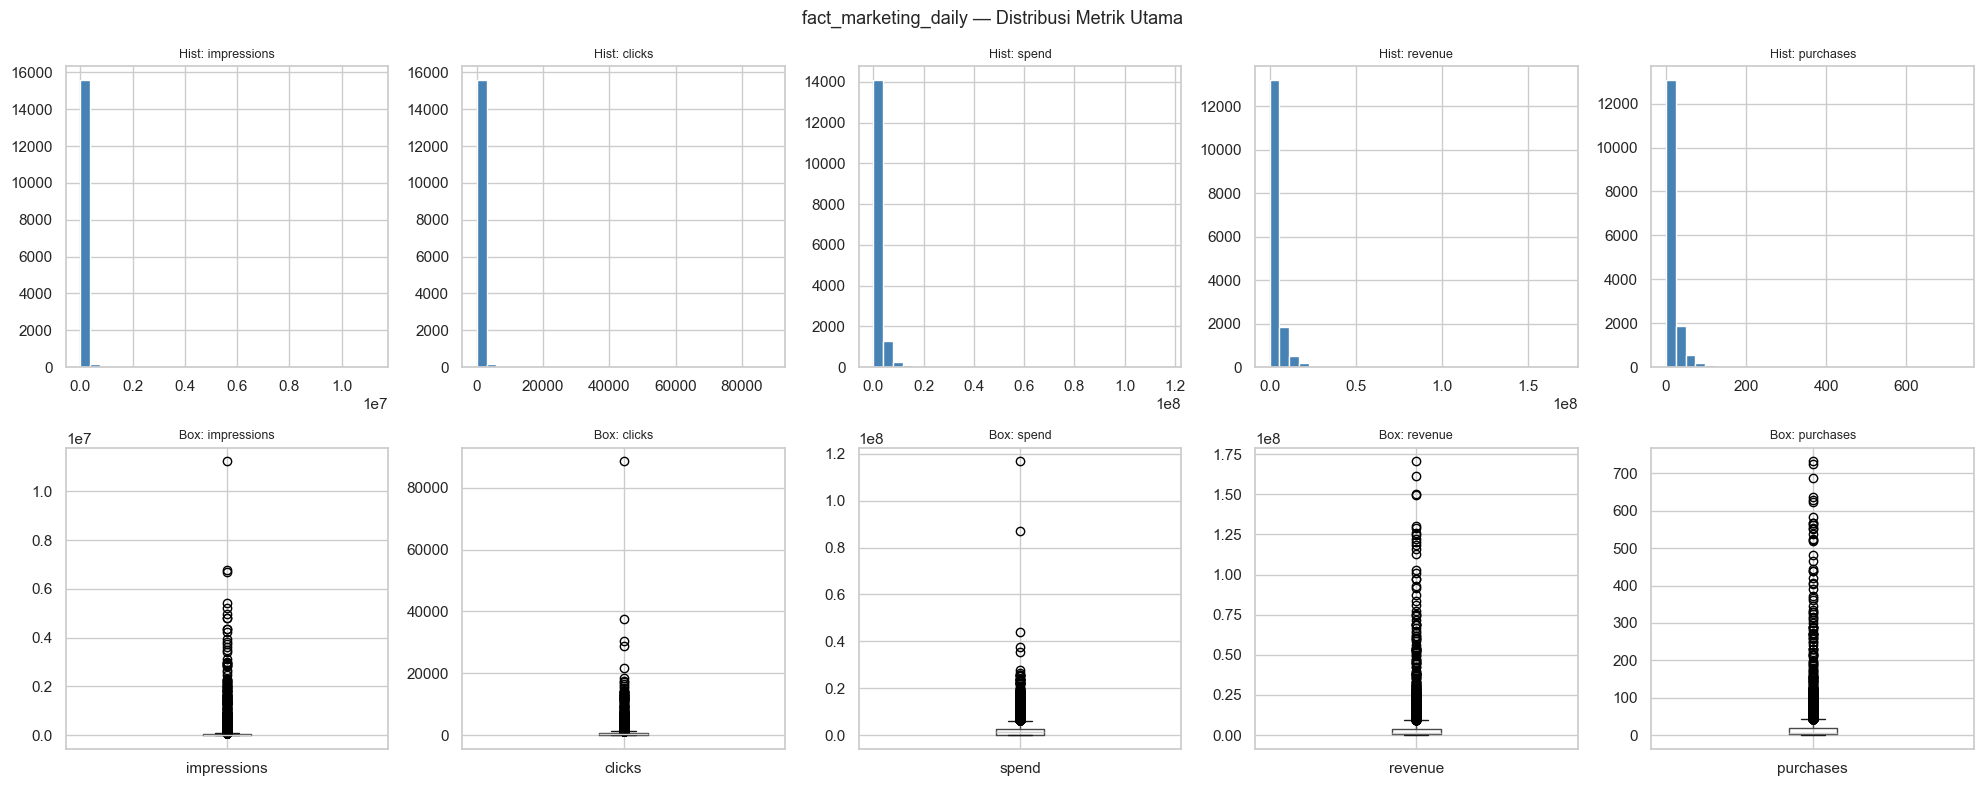

In [318]:
key_cols = ['impressions', 'clicks', 'spend', 'revenue', 'purchases']

fig, axes = plt.subplots(2, len(key_cols), figsize=(20, 8))
for i, col in enumerate(key_cols):
    fact_marketing_daily[col].hist(ax=axes[0, i], bins=30, color='steelblue', edgecolor='white')
    axes[0, i].set_title(f'Hist: {col}', fontsize=9)
    fact_marketing_daily.boxplot(column=col, ax=axes[1, i])
    axes[1, i].set_title(f'Box: {col}', fontsize=9)
plt.suptitle('fact_marketing_daily — Distribusi Metrik Utama', fontsize=13)
plt.tight_layout()
plt.show()

In [319]:
# IQR-based outlier count untuk kolom numerik utama
print('Outlier (IQR method) per kolom:')
for col in key_cols:
    Q1  = fact_marketing_daily[col].quantile(0.25)
    Q3  = fact_marketing_daily[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((fact_marketing_daily[col] < lower) | (fact_marketing_daily[col] > upper)).sum()
    print(f'  {col:<20} | Batas [{lower:,.2f}, {upper:,.2f}] | Outlier: {n_out}')

Outlier (IQR method) per kolom:
  impressions          | Batas [-49,310.00, 88,186.00] | Outlier: 2227
  clicks               | Batas [-735.50, 1,348.50] | Outlier: 1196
  spend                | Batas [-3,666,103.42, 6,233,372.31] | Outlier: 779
  revenue              | Batas [-4,971,898.85, 9,559,207.47] | Outlier: 1125
  purchases            | Batas [-22.00, 42.00] | Outlier: 1138


### 10.7 Foreign Key Validation (per tabel)

In [320]:
fk_checks = {
    'date_id'    : (fact_marketing_daily['date_id'].astype(str),    dim_date_clean['date_id']),
    'channel_id' : (fact_marketing_daily['channel_id'],             dim_channel_clean['channel_id']),
    'campaign_id': (fact_marketing_daily['campaign_id'],            dim_campaign_clean['campaign_id']),
    'ad_id'      : (fact_marketing_daily['ad_id'],                  dim_ad_content_clean['ad_id']),
}

for fk, (fact_col, dim_col) in fk_checks.items():
    orphan = ~fact_col.isin(dim_col)
    print(f'  FK [{fk:<12}] — orphan records: {orphan.sum():,}')

# kol_id: hanya baris yang tidak null yang perlu divalidasi
kol_fact = fact_marketing_daily['kol_id'].dropna()
orphan_kol = ~kol_fact.isin(dim_kol_clean['kol_id'])
print(f'  FK [kol_id      ] — orphan records: {orphan_kol.sum():,} (dari {len(kol_fact):,} baris non-null)')

  FK [date_id     ] — orphan records: 0
  FK [channel_id  ] — orphan records: 7
  FK [campaign_id ] — orphan records: 6
  FK [ad_id       ] — orphan records: 0
  FK [kol_id      ] — orphan records: 0 (dari 1,659 baris non-null)


date_id → orphan records: 0 → semua date_id di tabel fakta ada padanannya di dim_date_clean.

channel_id → orphan records: 7 → ada 7 baris di tabel fakta yang channel_id‑nya tidak ditemukan di dim_channel_clean.

campaign_id → orphan records: 6 → ada 6 baris di tabel fakta yang campaign_id‑nya tidak ada di dim_campaign_clean.

ad_id → orphan records: 0 → semua ad_id valid, ada di dim_ad_content_clean.

kol_id → orphan records: 0 dari 1,659 baris non‑null → artinya semua kol_id yang terisi punya padanan di dim_kol_clean, tidak ada orphan.

In [321]:
# Cek rows orphan untuk channel_id
orphan_channel = fact_marketing_daily[~fact_marketing_daily['channel_id'].isin(dim_channel_clean['channel_id'])]
print(orphan_channel)

# Cek rows orphan untuk campaign_id
orphan_campaign = fact_marketing_daily[~fact_marketing_daily['campaign_id'].isin(dim_campaign_clean['campaign_id'])]
print(orphan_campaign)


        date_id channel_id campaign_id    ad_id  kol_id  impressions   reach  clicks           spend  video_views  likes  comments  shares  saves  leads  sessions  add_to_cart  checkout  purchases  \
24     20250202    CH_META     CMP0001  AD00001     NaN       137953  100428    2015 11,974,757.0500        54264   1201        85      41     43     60      1682          319       151         65   
5869   20251217    CH_META     CMP0010  AD00035     NaN       131935   38040    2492  7,431,579.1300        52527   1288        53     101     59     86      2296          431        98         30   
7124   20250415    CH_META     CMP0018  AD00062     NaN         7605    2658     274    830,154.5400            0     67         2       6      2      2       217           60        28         22   
7470   20250206    CH_META     CMP0020  AD00067  KOL016        76954   57593     994  3,488,549.6100        15875   2887        48     308    256     37       663          164        46         21   


### 10.8 Cleaning fact_marketing_daily

In [322]:
fmd_clean = fact_marketing_daily.copy()

# 1. Konversi date_id ke string
fmd_clean['date_id'] = fmd_clean['date_id'].astype(str)

# 2. Hapus duplicate baris 
before = len(fmd_clean)
fmd_clean.drop_duplicates(inplace=True)
print(f'Duplicate rows dihapus: {before - len(fmd_clean)}')

# 3. Hapus duplicate grain 
# Alasan: setiap kombinasi (date, channel, campaign, ad) seharusnya unik
grain_cols = ['date_id', 'channel_id', 'campaign_id', 'ad_id']
before = len(fmd_clean)
fmd_clean.drop_duplicates(subset=grain_cols, keep='first', inplace=True)
print(f'Duplicate grain dihapus: {before - len(fmd_clean)}')

# # 4. Tambahkan derived metric (opsional, untuk verifikasi) ─
# # CTR dan CVR sebagai kolom validasi
# fmd_clean['ctr']  = np.where(fmd_clean['impressions'] > 0,
#                               fmd_clean['clicks'] / fmd_clean['impressions'], np.nan)
# fmd_clean['cvr']  = np.where(fmd_clean['clicks'] > 0,
#                               fmd_clean['purchases'] / fmd_clean['clicks'], np.nan)
# fmd_clean['roas'] = np.where(fmd_clean['spend'] > 0,
#                               fmd_clean['revenue'] / fmd_clean['spend'], np.nan)

print(f'Shape akhir: {fmd_clean.shape}')
print('fact_marketing_daily cleaning selesai ')

Duplicate rows dihapus: 0
Duplicate grain dihapus: 0
Shape akhir: (15849, 22)
fact_marketing_daily cleaning selesai 


---
## 11. Analisis & Cleaning — `fact_web_events`

Data perjalanan pelanggan pada website.

**Primary Key:** `event_id`  
**Grain:** satu baris = satu event pengguna  
**Foreign Keys:** `date_id`, `customer_id`, `channel_id`, `campaign_id`, `ad_id`, `product_id`

In [323]:
# # Path dataset
# DATA_PATH = 'dataset/'

# # Load semua tabel

# fact_web_events      = pd.read_csv(DATA_PATH + 'fact_web_events.csv')

# fact_web_events.head()

### 11.1 Gambaran Dataset

In [324]:
print('Shape :', fact_web_events.shape)
print()
fact_web_events.info()
display(fact_web_events.head(5))
display(fact_web_events.sample(5, random_state=42))

Shape : (72881, 19)

<class 'pandas.DataFrame'>
RangeIndex: 72881 entries, 0 to 72880
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   event_id         72881 non-null  str  
 1   event_timestamp  72881 non-null  str  
 2   date_id          72881 non-null  int64
 3   customer_id      72881 non-null  str  
 4   session_id       72881 non-null  str  
 5   channel_id       72881 non-null  str  
 6   campaign_id      51252 non-null  str  
 7   ad_id            51241 non-null  str  
 8   device           72881 non-null  str  
 9   browser          72881 non-null  str  
 10  landing_page     72881 non-null  str  
 11  event_name       72881 non-null  str  
 12  product_id       44835 non-null  str  
 13  traffic_source   72881 non-null  str  
 14  utm_source       72881 non-null  str  
 15  utm_medium       72881 non-null  str  
 16  utm_campaign     50895 non-null  str  
 17  city             72881 non-null  str  
 

,event_id,event_timestamp,date_id,customer_id,session_id,channel_id,campaign_id,ad_id,device,browser,landing_page,event_name,product_id,traffic_source,utm_source,utm_medium,utm_campaign,city,is_new_user
0,EV00000001,2025-01-02 16:15:39,20250102,CUS009319,SES0000001,CH006,NaN,NaN,Mobile,Chrome,/blog/skincare-routine,page_view,NaN,Email Marketing,email_marketing,email,NaN,JKT,False
1,EV00000002,2025-01-02 16:16:47,20250102,CUS009319,SES0000001,CH006,NaN,NaN,Mobile,Chrome,/blog/skincare-routine,product_view,PRD011,Email Marketing,email_marketing,email,NaN,JKT,False
2,EV00000003,2025-01-02 16:18:58,20250102,CUS009319,SES0000001,CH006,NaN,NaN,Mobile,Chrome,/blog/skincare-routine,add_to_cart,PRD011,Email Marketing,email_marketing,email,NaN,JKT,False
3,EV00000004,2025-01-02 16:20:11,20250102,CUS009319,SES0000001,CH006,NaN,NaN,Mobile,Chrome,/blog/skincare-routine,begin_checkout,PRD011,Email Marketing,email_marketing,email,NaN,JKT,False
4,EV00000005,2025-05-20 21:36:07,20250520,CUS006499,SES0000002,CH001,CMP0001,AD00002,mobile,Chrome,/bundle/glow-routine,page_view,NaN,meta ads,meta_ads,paid_social,CMP0001,Semarang,False


,event_id,event_timestamp,date_id,customer_id,session_id,channel_id,campaign_id,ad_id,device,browser,landing_page,event_name,product_id,traffic_source,utm_source,utm_medium,utm_campaign,city,is_new_user
66663,EV00066664,2025-01-08 11:38:15,20250108,CUS009548,SES0023781,CH007,NaN,NaN,Smartphone,Chrome,/,page_view,NaN,WA Blast,wa_blast,whatsapp,NaN,Denpasar,True
50201,EV00050202,2025-12-09 08:32:33,20251209,CUS003420,SES0017923,CH011,NaN,NaN,Mobile,Edge,/,product_view,PRD021,Tokopedia Ads,tokopedia_ads,marketplace_cpc,NaN,Bogor,True
65549,EV00065550,2025-05-30 00:14:13,20250530,CUS000509,SES0023383,CH006,CMP0005,AD00017,Smartphone,Samsung Internet,/blog/skincare-routine,product_view,PRD027,email,email,email,CMP0005,Yogyakarta,True
5897,EV00005898,2025-02-01 00:07:04,20250201,CUS014864,SES0002110,CH003,NaN,NaN,Mobile,Chrome Mobile,/,begin_checkout,PRD036,TikTok Ads,tiktok_ads,paid_social,NaN,Bogor,False
60940,EV00060941,2025-10-30 14:22:20,20251030,CUS008061,SES0021733,CH011,CMP0053,AD00168,iPhone,Chrome,/promo-flash-sale,product_view,PRD024,Shopee Ads,shopee_ads,marketplace_cpc,CMP0053,Jogja,True


### 11.2 Statistik Deskriptif

In [325]:
cat_cols_web = fact_web_events.select_dtypes(include='object').columns.tolist()
for col in cat_cols_web:
    if col not in ['event_id', 'event_timestamp', 'session_id', 'customer_id',
                   'landing_page', 'utm_campaign', 'city ']:
        print(f'\n{col} ({fact_web_events[col].nunique()} unique) ')
        print(fact_web_events[col].value_counts().head(50))


channel_id (13 unique) 
channel_id
CH001      15643
CH003      12404
CH002      10496
CH006       6244
CH008       5172
CH004       4938
CH005       4152
CH007       3730
CH010       3396
CH011       3101
CH009       2820
CH012        712
CH_META       73
Name: count, dtype: int64

campaign_id (62 unique) 
campaign_id
CMP0003    5772
CMP0004    5739
CMP0005    5273
CMP0002    5088
CMP0001    2961
CMP0050    1315
CMP0010    1257
CMP0047    1137
CMP0033    1057
CMP0019    1021
CMP0032     930
CMP0031     918
CMP0023     908
CMP0022     904
CMP0062     869
CMP0053     777
CMP0013     773
CMP0060     772
CMP0030     732
CMP0052     725
CMP0025     708
CMP0058     660
CMP0040     586
CMP0020     581
CMP0026     543
CMP0009     527
CMP0037     519
CMP0017     500
CMP0018     487
CMP0007     465
CMP0054     452
CMP0061     452
CMP0035     409
CMP0059     400
CMP0015     387
CMP0024     386
CMP0041     372
CMP0045     353
CMP0014     341
CMP0046     310
CMP0044     292
CMP0042     288
CMP0006

### 11.3 Missing Value Analysis

,missing_count,missing_pct
campaign_id,21629,29.6800
ad_id,21640,29.6900
product_id,28046,38.4800
utm_campaign,21986,30.1700


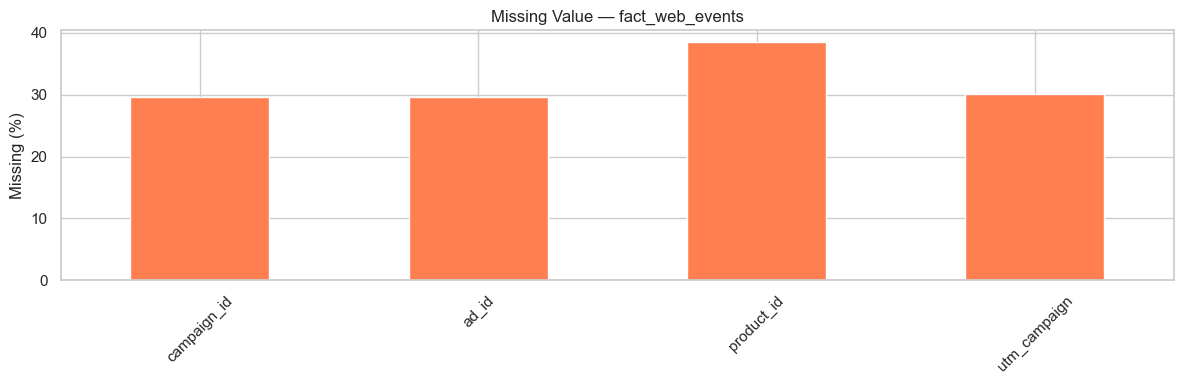


Catatan: campaign_id & ad_id kosong wajar untuk sesi organik/direct


In [326]:
mv = fact_web_events.isnull().sum()
mv_pct = (mv / len(fact_web_events) * 100).round(2)
mv_df = pd.DataFrame({'missing_count': mv, 'missing_pct': mv_pct})
mv_df = mv_df[mv_df['missing_count'] > 0]
if mv_df.empty:
    print(' Tidak ada missing value pada fact_web_events')
else:
    display(mv_df)
    mv_df['missing_pct'].plot(kind='bar', color='coral', edgecolor='white', figsize=(12, 4))
    plt.title('Missing Value — fact_web_events')
    plt.ylabel('Missing (%)')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    print('\nCatatan: campaign_id & ad_id kosong wajar untuk sesi organik/direct')

### 11.4 Duplicate Analysis

In [327]:
print(f'Duplicate rows     : {fact_web_events.duplicated().sum()}')
print(f'Duplicate event_id : {fact_web_events.duplicated(subset=["event_id"]).sum()}')

Duplicate rows     : 0
Duplicate event_id : 0


### 11.5 Unique Value Analysis

In [328]:
print('Jumlah unique per kolom:')
print(fact_web_events.nunique())

print('\nevent_name ')
print(fact_web_events['event_name'].value_counts())

print('\ndevice ')
print(fact_web_events['device'].value_counts())

print('\nis_new_user ')
print(fact_web_events['is_new_user'].value_counts(dropna=False))

Jumlah unique per kolom:
event_id           72881
event_timestamp    72795
date_id              365
customer_id        12301
session_id         25840
channel_id            13
campaign_id           62
ad_id                191
device                 9
browser                6
landing_page          10
event_name             7
product_id            39
traffic_source        41
utm_source            28
utm_medium            10
utm_campaign          61
city                  26
is_new_user            2
dtype: int64

event_name 
event_name
page_view         26000
product_view      20268
exit              17819
add_to_cart        5062
begin_checkout     2360
purchase           1273
form_submit          99
Name: count, dtype: int64

device 
device
Mobile           18217
Android Phone    11537
iPhone            9449
mobile            8669
Smartphone        8493
Desktop           7578
PC                3087
MOBILE            2949
Laptop            2902
Name: count, dtype: int64

is_new_user 
is_new

### 11.6 Validasi Waktu

In [329]:
ts_parsed = pd.to_datetime(fact_web_events['event_timestamp'], errors='coerce')
print(f'Timestamp tidak valid  : {ts_parsed.isna().sum()}')
print(f'Rentang event_timestamp: {ts_parsed.min()} → {ts_parsed.max()}')

# date_id: cek format
print(f'\nSample date_id: {fact_web_events["date_id"].head(5).values}')

Timestamp tidak valid  : 1309
Rentang event_timestamp: 2025-01-01 00:03:49 → 2025-12-31 23:47:14

Sample date_id: [20250102 20250102 20250102 20250102 20250520]


format tanggalnya jelek

In [330]:
# Parse timestamp
ts_parsed = pd.to_datetime(fact_web_events['event_timestamp'], errors='coerce')

# Ambil rows yang invalid (hasil parsing NaT)
invalid_ts = fact_web_events[ts_parsed.isna()]

print("Rows dengan event_timestamp tidak valid:")
print(invalid_ts)


Rows dengan event_timestamp tidak valid:
         event_id      event_timestamp   date_id customer_id  session_id channel_id campaign_id    ad_id         device        browser            landing_page    event_name product_id  \
21     EV00000022     28/06/2025 16:08  20250628   CUS004608  SES0000008      CH002     CMP0004  AD00012         mobile         Chrome       /promo-flash-sale  product_view     PRD038   
36     EV00000037     27/02/2025 17:30  20250227   CUS006776  SES0000014      CH003         NaN      NaN         Mobile         Chrome     /product/glow-serum     page_view        NaN   
60     EV00000061     11/05/2025 07:02  20250511   CUS012671  SES0000022      CH001     CMP0001  AD00002         Mobile         Chrome    /bundle/glow-routine          exit        NaN   
67     EV00000068     20/12/2025 08:06  20251220   CUS005272  SES0000025      CH006     CMP0005  AD00015         iPhone  Chrome Mobile     /product/glow-serum          exit     PRD040   
139    EV00000140     08

In [331]:
# Parsing pertama (format default / ISO)
ts = pd.to_datetime(
    fact_web_events["event_timestamp"],
    errors="coerce"
)

# Parsing kedua (DD/MM/YYYY HH:MM)
mask = ts.isna()

ts.loc[mask] = pd.to_datetime(
    fact_web_events.loc[mask, "event_timestamp"],
    format="%d/%m/%Y %H:%M",
    errors="coerce"
)

# Parsing ketiga (MM-DD-YYYY HH:MM AM/PM)
mask = ts.isna()

ts.loc[mask] = pd.to_datetime(
    fact_web_events.loc[mask, "event_timestamp"],
    format="%m-%d-%Y %I:%M %p",
    errors="coerce"
)

fact_web_events["event_timestamp"] = ts

print(
    fact_web_events["event_timestamp"].isna().sum()
)

0


In [332]:
event_date = (
    fact_web_events["event_timestamp"]
    .dt.strftime("%Y%m%d")
    .astype("Int64")
)

date_mismatch = fact_web_events[
    event_date != fact_web_events["date_id"]
]

print(f"Date mismatch: {len(date_mismatch)}")
display(date_mismatch.head())

Date mismatch: 0


,event_id,event_timestamp,date_id,customer_id,session_id,channel_id,campaign_id,ad_id,device,browser,landing_page,event_name,product_id,traffic_source,utm_source,utm_medium,utm_campaign,city,is_new_user


### 11.7 Foreign Key Validation

In [333]:
fk_checks_web = {
    'date_id'    : (fact_web_events['date_id'].astype(str), dim_date_clean['date_id']),
    'customer_id': (fact_web_events['customer_id'],         dim_customer_clean['customer_id']),
    'channel_id' : (fact_web_events['channel_id'],          dim_channel_clean['channel_id']),
}

for fk, (fact_col, dim_col) in fk_checks_web.items():
    orphan = ~fact_col.isin(dim_col)
    print(f'  FK [{fk:<14}] — orphan: {orphan.sum():,}')

# FK opsional (bisa null)
for fk, dim_col in [('campaign_id', dim_campaign_clean['campaign_id']),
                    ('ad_id',       dim_ad_content_clean['ad_id']),
                    ('product_id',  dim_product_clean['product_id'])]:
    non_null = fact_web_events[fk].dropna()
    orphan   = ~non_null.isin(dim_col)
    print(f'  FK [{fk:<14}] — orphan (non-null): {orphan.sum():,} dari {len(non_null):,}')

  FK [date_id       ] — orphan: 0
  FK [customer_id   ] — orphan: 0
  FK [channel_id    ] — orphan: 73
  FK [campaign_id   ] — orphan (non-null): 36 dari 51,252
  FK [ad_id         ] — orphan (non-null): 0 dari 51,241
  FK [product_id    ] — orphan (non-null): 36 dari 44,835


In [334]:
# =============================================================================
# INVESTIGASI ORPHAN FOREIGN KEY - FACT_WEB_EVENTS
# =============================================================================

# ---------------------------
# CHANNEL_ID
# ---------------------------
invalid_channel = fact_web_events[
    ~fact_web_events["channel_id"].isin(dim_channel_clean["channel_id"])
]

print("="*70)
print("CHANNEL_ID")
print("="*70)
print(f"Jumlah orphan : {len(invalid_channel)}")

print("\nUnique ID yang bermasalah:")
print(invalid_channel["channel_id"].unique())

print("\nFrekuensi tiap ID:")
print(invalid_channel["channel_id"].value_counts())

display(invalid_channel.head())


# ---------------------------
# CAMPAIGN_ID
# ---------------------------
invalid_campaign = fact_web_events[
    fact_web_events["campaign_id"].notna() &
    ~fact_web_events["campaign_id"].isin(dim_campaign_clean["campaign_id"])
]

print("\n" + "="*70)
print("CAMPAIGN_ID")
print("="*70)
print(f"Jumlah orphan : {len(invalid_campaign)}")

print("\nUnique ID yang bermasalah:")
print(invalid_campaign["campaign_id"].unique())

print("\nFrekuensi tiap ID:")
print(invalid_campaign["campaign_id"].value_counts())

display(invalid_campaign.head())


# ---------------------------
# PRODUCT_ID
# ---------------------------
invalid_product = fact_web_events[
    fact_web_events["product_id"].notna() &
    ~fact_web_events["product_id"].isin(dim_product_clean["product_id"])
]

print("\n" + "="*70)
print("PRODUCT_ID")
print("="*70)
print(f"Jumlah orphan : {len(invalid_product)}")

print("\nUnique ID yang bermasalah:")
print(invalid_product["product_id"].unique())

print("\nFrekuensi tiap ID:")
print(invalid_product["product_id"].value_counts())

display(invalid_product.head())

CHANNEL_ID
Jumlah orphan : 73

Unique ID yang bermasalah:
<StringArray>
['CH_META']
Length: 1, dtype: str

Frekuensi tiap ID:
channel_id
CH_META    73
Name: count, dtype: int64


,event_id,event_timestamp,date_id,customer_id,session_id,channel_id,campaign_id,ad_id,device,browser,landing_page,event_name,product_id,traffic_source,utm_source,utm_medium,utm_campaign,city,is_new_user
987,EV00000988,2025-09-23 11:32:47,20250923,CUS014465,SES0000363,CH_META,NaN,NaN,Android Phone,Chrome,/product/glow-serum,page_view,NaN,TikTok Paid,tiktok_paid,paid_social,NaN,Bandung,True
1609,EV00001610,2025-08-02 05:35:07,20250802,CUS001366,SES0000574,CH_META,CMP0003,AD00009,Mobile,Firefox,/quiz/skincare,product_view,PRD004,tiktok ads,tiktok_ads,paid_social,CMP0003,Depok,False
2568,EV00002569,2025-03-03 22:04:55,20250303,CUS002850,SES0000923,CH_META,CMP0004,AD00011,Android Phone,Chrome,/blog/skincare-routine,exit,PRD002,google ads,google_ads,cpc,CMP0004,Depok,False
3078,EV00003079,2025-04-12 14:29:25,20250412,CUS010018,SES0001105,CH_META,NaN,NaN,Mobile,Samsung Internet,/product/glow-serum,page_view,NaN,TikTok Organic,tiktok_organic,organic_social,NaN,JKT,False
5610,EV00005611,2025-11-21 22:32:22,20251121,CUS002657,SES0002008,CH_META,CMP0060,AD00188,mobile,Chrome,/product/acne-calm,exit,PRD019,FB Ads,fb_ads,paid_social,CMP0060,Surabaya,True



CAMPAIGN_ID
Jumlah orphan : 36

Unique ID yang bermasalah:
<StringArray>
['CMP9999']
Length: 1, dtype: str

Frekuensi tiap ID:
campaign_id
CMP9999    36
Name: count, dtype: int64


,event_id,event_timestamp,date_id,customer_id,session_id,channel_id,campaign_id,ad_id,device,browser,landing_page,event_name,product_id,traffic_source,utm_source,utm_medium,utm_campaign,city,is_new_user
323,EV00000324,2025-12-23 04:50:02,20251223,CUS010910,SES0000117,CH011,CMP9999,NaN,Mobile,Chrome,/blog/skincare-routine,product_view,PRD025,Tokopedia Ads,tokopedia_ads,marketplace_cpc,NaN,Bekasi,False
4686,EV00004687,2025-08-15 00:16:28,20250815,CUS011500,SES0001673,CH002,CMP9999,AD00103,Desktop,Safari,/marketplace-official-store,exit,PRD025,Google Ads,google_ads,cpc,CMP0033,Tangerang,False
5742,EV00005743,2025-07-12 12:10:50,20250712,CUS010870,SES0002053,CH003,CMP9999,AD00008,Mobile,Chrome Mobile,/promo-flash-sale,product_view,PRD001,TIKTOK ADS,tiktok_ads,paid_social,CMP0003,Malang,False
13276,EV00013277,2025-05-22 14:26:27,20250522,CUS002702,SES0004767,CH003,CMP9999,AD00008,Desktop,Chrome,/promo-flash-sale,exit,PRD002,tiktok ads,tiktok_ads,paid_social,CMP0003,Depok,True
14422,EV00014423,2025-03-28 11:23:57,20250328,CUS002816,SES0005171,CH005,CMP9999,NaN,mobile,Samsung Internet,/bundle/glow-routine,add_to_cart,PRD023,TikTok Organic,tiktok_organic,organic_social,NaN,Bandung,True



PRODUCT_ID
Jumlah orphan : 36

Unique ID yang bermasalah:
<StringArray>
['PRD999']
Length: 1, dtype: str

Frekuensi tiap ID:
product_id
PRD999    36
Name: count, dtype: int64


,event_id,event_timestamp,date_id,customer_id,session_id,channel_id,campaign_id,ad_id,device,browser,landing_page,event_name,product_id,traffic_source,utm_source,utm_medium,utm_campaign,city,is_new_user
1604,EV00001605,2025-07-05 13:27:01,20250705,CUS005895,SES0000572,CH001,CMP0017,AD00056,Android Phone,Chrome,/promo-flash-sale,exit,PRD999,FB Ads,fb_ads,paid_social,CMP0017,Bogor,False
3622,EV00003623,2025-05-07 23:35:58,20250507,CUS014597,SES0001301,CH009,NaN,NaN,Android Phone,Firefox,/,page_view,PRD999,Partner,partner,affiliate,NaN,jakarta,False
3741,EV00003742,2025-12-13 00:26:01,20251213,CUS009281,SES0001342,CH001,CMP0060,AD00188,iPhone,Chrome,/product/acne-calm,page_view,PRD999,META ADS,meta_ads,paid_social,CMP0060,Kota Bandung,True
7387,EV00007388,2025-01-20 17:03:49,20250120,CUS012293,SES0002643,CH001,CMP0001,AD00003,Mobile,Firefox,/promo-flash-sale,product_view,PRD999,Facebook/Instagram Ads,facebook_instagram_ads,paid_social,CMP0001,Jakarta,True
8712,EV00008713,2025-05-31 00:16:01,20250531,CUS008213,SES0003127,CH007,CMP0054,AD00171,Mobile,Chrome,/marketplace-official-store,product_view,PRD999,WhatsApp Broadcast,whatsapp_broadcast,whatsapp,CMP0054,Jakarta,False


### 11.8 Cleaning fact_web_events

In [335]:
# -------------------------
# Standardisasi City
# -------------------------
city_mapping = {
    "Jkt": "Jakarta",
    "JKT": "Jakarta",
    "Dki Jakarta": "Jakarta",
    "DKI Jakarta": "Jakarta",
    " jakarta ": "Jakarta",
    "Bdg": "Bandung",
    "bandung": "Bandung",
    "BDG": "Bandung",
    "Kota Bandung": "Bandung",
    "Sby": "Surabaya",
    "SBY": "Surabaya",
    "surabaya": "Surabaya",
    "Jogja": "Yogyakarta",
    "DIY": "Yogyakarta"
}

fact_web_events["city"] = (
    fact_web_events["city"]
    .replace(city_mapping)
    .fillna("Unknown")
)


# =============================================================================
# VERIFIKASI HASIL CLEANING
# =============================================================================

print("="*70)
print("CITY")
print("="*70)
print(fact_web_events["city"].value_counts(dropna=False))
print(f"\nJumlah kategori city : {fact_web_events['city'].nunique()}")



CITY
city
Jakarta            20181
Bandung             7207
Surabaya            6618
Bekasi              6094
Tangerang           4529
Depok               4224
Bogor               4137
Yogyakarta          3961
Semarang            3687
Malang              3251
Medan               3066
Palembang           1713
Makassar            1521
Balikpapan          1011
Denpasar             963
Jakarta Selatan      718
Name: count, dtype: int64

Jumlah kategori city : 16


In [336]:
cat_cols_web = fact_web_events.select_dtypes(include='object').columns.tolist()
for col in cat_cols_web:
    if col not in ['event_id', 'event_timestamp', 'session_id', 'customer_id',
                   'landing_page', 'utm_campaign']:
        print(f'\n{col} ({fact_web_events[col].nunique()} unique) ')
        print(fact_web_events[col].value_counts().head(50))


channel_id (13 unique) 
channel_id
CH001      15643
CH003      12404
CH002      10496
CH006       6244
CH008       5172
CH004       4938
CH005       4152
CH007       3730
CH010       3396
CH011       3101
CH009       2820
CH012        712
CH_META       73
Name: count, dtype: int64

campaign_id (62 unique) 
campaign_id
CMP0003    5772
CMP0004    5739
CMP0005    5273
CMP0002    5088
CMP0001    2961
CMP0050    1315
CMP0010    1257
CMP0047    1137
CMP0033    1057
CMP0019    1021
CMP0032     930
CMP0031     918
CMP0023     908
CMP0022     904
CMP0062     869
CMP0053     777
CMP0013     773
CMP0060     772
CMP0030     732
CMP0052     725
CMP0025     708
CMP0058     660
CMP0040     586
CMP0020     581
CMP0026     543
CMP0009     527
CMP0037     519
CMP0017     500
CMP0018     487
CMP0007     465
CMP0054     452
CMP0061     452
CMP0035     409
CMP0059     400
CMP0015     387
CMP0024     386
CMP0041     372
CMP0045     353
CMP0014     341
CMP0046     310
CMP0044     292
CMP0042     288
CMP0006

In [337]:
# =============================================================================
# DATA CLEANING: Standardisasi Kategori
# =============================================================================

# ------------------------------------------------------------------
# DEVICE
# ------------------------------------------------------------------
device_map = {
    "mobile": "Mobile",
    "Mobile": "Mobile",
    "MOBILE": "Mobile",

    "Android Phone": "Android Phone",
    "iPhone": "iPhone",
    "Smartphone": "Smartphone",
    "Desktop": "Desktop",
    "Laptop": "Laptop",
    "PC": "PC"
}

fact_web_events["device"] = (
    fact_web_events["device"]
    .replace(device_map)
)

# ------------------------------------------------------------------
# EVENT NAME
# ------------------------------------------------------------------
fact_web_events["event_name"] = (
    fact_web_events["event_name"]
    .str.replace("_", " ", regex=False)
    .str.title()
)

# ------------------------------------------------------------------
# TRAFFIC SOURCE
# ------------------------------------------------------------------
traffic_map = {
    "GOOGLE ADS": "Google Ads",
    "google ads": "Google Ads",
    "Google Ads": "Google Ads",

    "META ADS": "Meta Ads",
    "meta ads": "Meta Ads",
    "Meta Ads": "Meta Ads",

    "TIKTOK ADS": "TikTok Ads",
    "tiktok ads": "TikTok Ads",
    "TikTok Ads": "TikTok Ads",

    "SEO": "SEO",
    "seo": "SEO",

    "IG Organic": "Instagram Organic",
    "instagram organic": "Instagram Organic",
    "Instagram Organic": "Instagram Organic",

    "tiktok organic": "TikTok Organic",
    "TikTok Organic": "TikTok Organic",

    "email": "Email",
    "Newsletter": "Newsletter",
    "Email Marketing": "Email Marketing",

    "whatsapp broadcast": "WhatsApp Broadcast",
    "WhatsApp Broadcast": "WhatsApp Broadcast",

    "Affiliate": "Affiliate",
    "affiliate": "Affiliate",

    "kol": "KOL",
    "KOL": "KOL",

    "Partner": "Partner",

    "direct": "Direct",
    "Direct": "Direct",
    "(direct)": "Direct"
}

fact_web_events["traffic_source"] = (
    fact_web_events["traffic_source"]
    .replace(traffic_map)
)

# ------------------------------------------------------------------
# UTM SOURCE
# ------------------------------------------------------------------
utm_source_map = {
    "google_ads": "Google Ads",
    "meta_ads": "Meta Ads",
    "tiktok_ads": "TikTok Ads",
    "tiktok_paid": "TikTok Paid",
    "tiktok_organic": "TikTok Organic",
    "tiktok_organic_": "TikTok Organic",
    "facebook_ads": "Facebook Ads",
    "facebook_instagram_ads": "Facebook/Instagram Ads",
    "fb_ads": "FB Ads",
    "instagram_organic": "Instagram Organic",
    "ig_organic": "Instagram Organic",
    "seo": "SEO",
    "organic_search": "Organic Search",
    "google_search": "Google Search",
    "newsletter": "Newsletter",
    "email": "Email",
    "email_marketing": "Email Marketing",
    "whatsapp_broadcast": "WhatsApp Broadcast",
    "wa_blast": "WA Blast",
    "kol": "KOL",
    "influencer": "Influencer",
    "affiliate": "Affiliate",
    "partner": "Partner",
    "marketplace_ads": "Marketplace Ads",
    "shopee_ads": "Shopee Ads",
    "tokopedia_ads": "Tokopedia Ads",
    "direct": "Direct",
    "(direct)": "Direct"
}

fact_web_events["utm_source"] = (
    fact_web_events["utm_source"]
    .replace(utm_source_map)
)

# ------------------------------------------------------------------
# UTM MEDIUM
# ------------------------------------------------------------------
utm_medium_map = {
    "paid_social": "Paid Social",
    "organic_social": "Organic Social",
    "cpc": "CPC",
    "marketplace_cpc": "Marketplace CPC",
    "organic": "Organic",
    "email": "Email",
    "whatsapp": "WhatsApp",
    "affiliate": "Affiliate",
    "influencer": "Influencer",
    "direct": "Direct"
}

fact_web_events["utm_medium"] = (
    fact_web_events["utm_medium"]
    .replace(utm_medium_map)
)

print("✅ Standardisasi kategori selesai.")

✅ Standardisasi kategori selesai.


In [338]:
cat_cols_web = fact_web_events.select_dtypes(include='object').columns.tolist()
for col in cat_cols_web:
    if col not in ['event_id', 'event_timestamp', 'session_id', 'customer_id',
                   'landing_page', 'utm_campaign']:
        print(f'\n{col} ({fact_web_events[col].nunique()} unique) ')
        print(fact_web_events[col].value_counts().head(50))


channel_id (13 unique) 
channel_id
CH001      15643
CH003      12404
CH002      10496
CH006       6244
CH008       5172
CH004       4938
CH005       4152
CH007       3730
CH010       3396
CH011       3101
CH009       2820
CH012        712
CH_META       73
Name: count, dtype: int64

campaign_id (62 unique) 
campaign_id
CMP0003    5772
CMP0004    5739
CMP0005    5273
CMP0002    5088
CMP0001    2961
CMP0050    1315
CMP0010    1257
CMP0047    1137
CMP0033    1057
CMP0019    1021
CMP0032     930
CMP0031     918
CMP0023     908
CMP0022     904
CMP0062     869
CMP0053     777
CMP0013     773
CMP0060     772
CMP0030     732
CMP0052     725
CMP0025     708
CMP0058     660
CMP0040     586
CMP0020     581
CMP0026     543
CMP0009     527
CMP0037     519
CMP0017     500
CMP0018     487
CMP0007     465
CMP0054     452
CMP0061     452
CMP0035     409
CMP0059     400
CMP0015     387
CMP0024     386
CMP0041     372
CMP0045     353
CMP0014     341
CMP0046     310
CMP0044     292
CMP0042     288
CMP0006

In [339]:
fwe_clean = fact_web_events.copy()

# 1. Konversi event_timestamp ke datetime 
fwe_clean['event_timestamp'] = pd.to_datetime(fwe_clean['event_timestamp'], errors='coerce')

# 2. Konversi date_id ke string
fwe_clean['date_id'] = fwe_clean['date_id'].astype(str)

# 3. Standardisasi is_new_user ke boolean 
if fwe_clean['is_new_user'].dtype == object:
    fwe_clean['is_new_user'] = fwe_clean['is_new_user'].map({'True': True, 'False': False})

# 4. Strip whitespace kolom string 
for col in fwe_clean.select_dtypes(include='object').columns:
    fwe_clean[col] = fwe_clean[col].str.strip()

# 5. Standardisasi kategori 
for col in ['device', 'browser', 'event_name', 'traffic_source']:
    if col in fwe_clean.columns:
        fwe_clean[col] = fwe_clean[col].str.title()

# 6. Hapus duplicate rows 
before = len(fwe_clean)
fwe_clean.drop_duplicates(inplace=True)
print(f'Duplicate rows dihapus: {before - len(fwe_clean)}')

# 7. Hapus duplicate event_id (primary key) 
before = len(fwe_clean)
fwe_clean.drop_duplicates(subset=['event_id'], keep='first', inplace=True)
print(f'Duplicate event_id dihapus: {before - len(fwe_clean)}')

print(f'Shape akhir: {fwe_clean.shape}')
print('fact_web_events cleaning selesai ')

Duplicate rows dihapus: 0
Duplicate event_id dihapus: 0
Shape akhir: (72881, 19)
fact_web_events cleaning selesai 


---
## 12. Analisis & Cleaning — `fact_orders`

Data transaksi dan pemesanan.

**Primary Key:** `order_id`  
**Grain:** satu baris = satu transaksi order  
**Foreign Keys:** `customer_id`, `channel_id`, `campaign_id`, `product_id`, `session_id`, `first_touch_channel_id`, `last_touch_channel_id`

### 12.1 Gambaran Dataset

In [340]:
print('Shape :', fact_orders.shape)
print()
fact_orders.info()
display(fact_orders.head(5))
display(fact_orders.sample(5, random_state=42))

Shape : (1490, 17)

<class 'pandas.DataFrame'>
RangeIndex: 1490 entries, 0 to 1489
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   order_id                1490 non-null   str    
 1   order_date              1490 non-null   str    
 2   customer_id             1490 non-null   str    
 3   session_id              1490 non-null   str    
 4   channel_id              1490 non-null   str    
 5   campaign_id             1163 non-null   str    
 6   product_id              1490 non-null   str    
 7   quantity                1490 non-null   int64  
 8   gross_revenue           1490 non-null   float64
 9   discount_amount         1490 non-null   float64
 10  net_revenue             1490 non-null   float64
 11  payment_method          1490 non-null   str    
 12  order_status            1490 non-null   str    
 13  refund_status           1325 non-null   str    
 14  shipping_city           1490 no

,order_id,order_date,customer_id,session_id,channel_id,campaign_id,product_id,quantity,gross_revenue,discount_amount,net_revenue,payment_method,order_status,refund_status,shipping_city,first_touch_channel_id,last_touch_channel_id
0,ORD0000001,2025-11-27,CUS007467,SES0000046,CH002,CMP0035,PRD022,1,"149,000.0000",0.0000,"149,000.0000",Credit Card,Completed,No Refund,Malang,CH003,CH002
1,ORD0000002,2025-08-31,CUS010318,SES0000050,CH001,CMP0002,PRD023,1,"329,000.0000","29,603.9200","299,396.0800",E-Wallet,Completed,No Refund,Semarang,CH002,CH001
2,ORD0000003,2025-10-20,CUS002526,SES0000116,CH005,NaN,PRD013,4,"556,000.0000",0.0000,"556,000.0000",PayLater,Completed,No Refund,DKI Jakarta,CH010,CH005
3,ORD0000004,2025-10-28,CUS006307,SES0000122,CH002,CMP0032,PRD026,1,"189,000.0000",0.0000,"189,000.0000",E-Wallet,Completed,No Refund,Surabaya,CH007,CH002
4,ORD0000005,2025-08-08,CUS001879,SES0000161,CH006,CMP0005,PRD026,1,"189,000.0000","18,940.3800","170,059.6200",E-Wallet,Completed,No Refund,Tangerang,CH006,CH006


,order_id,order_date,customer_id,session_id,channel_id,campaign_id,product_id,quantity,gross_revenue,discount_amount,net_revenue,payment_method,order_status,refund_status,shipping_city,first_touch_channel_id,last_touch_channel_id
941,ORD0000942,2025-05-30,CUS013476,SES0016700,CH001,CMP0001,PRD039,2,"178,000.0000","15,639.2100","162,360.7900",Virtual Account,Paid,No Refund,Bandung,CH005,CH001
297,ORD0000298,2025-12-30,CUS012414,SES0005070,CH002,CMP0031,PRD002,2,"318,000.0000",0.0000,"318,000.0000",Virtual Account,Completed,No Refund,Depok,CH008,CH002
271,ORD0000272,2025-08-10,CUS010523,SES0004702,CH007,CMP0014,PRD016,1,"149,000.0000",0.0000,"149,000.0000",E-Wallet,Success,No Refund,Jakarta,CH008,CH007
774,ORD0000775,2025-12-25,CUS011620,SES0013635,CH010,NaN,PRD020,1,"229,000.0000",0.0000,"229,000.0000",Bank Transfer,Completed,No Refund,Jakarta,CH003,CH010
420,ORD0000421,2025-12-15,CUS012954,SES0007308,CH006,CMP0005,PRD023,2,"658,000.0000",0.0000,"658,000.0000",E-Wallet,Paid,No Refund,Surabaya,CH007,CH006


### 12.2 Statistik Deskriptif

In [341]:
display(fact_orders.describe(include='number'))

cat_cols_ord = ['payment_method', 'order_status', 'refund_status', 'shipping_city']
for col in cat_cols_ord:
    print(f'\n{col} ')
    print(f'\n{col} ({fact_orders[col].nunique()} unique) ')
    print(fact_orders[col].value_counts())

,quantity,gross_revenue,discount_amount,net_revenue
count,"1,490.0000","1,490.0000","1,490.0000","1,490.0000"
mean,1.6872,"377,716.1074","17,874.6124","305,907.4842"
std,2.4139,"600,856.1917","43,303.6176","547,711.3159"
min,-1.0000,"49,000.0000",0.0000,"-409,802.7100"
25%,1.0000,"149,000.0000",0.0000,"98,000.0000"
50%,1.0000,"267,000.0000",0.0000,"189,000.0000"
75%,2.0000,"399,000.0000","26,446.2250","378,000.0000"
max,34.0000,"10,166,000.0000","1,064,684.0800","10,166,000.0000"



payment_method 

payment_method (6 unique) 
payment_method
E-Wallet           548
Virtual Account    299
Credit Card        225
COD                161
Bank Transfer      147
PayLater           110
Name: count, dtype: int64

order_status 

order_status (11 unique) 
order_status
Completed         790
Paid              163
Success           135
complete          117
Failed             76
COMPLETED          68
payment failed     58
Pending            31
Cancelled          25
cancel             14
CANCELED           13
Name: count, dtype: int64

refund_status 

refund_status (5 unique) 
refund_status
No Refund         1230
Refunded            42
Partial Refund      27
REFUNDED            14
refund              12
Name: count, dtype: int64

shipping_city 

shipping_city (26 unique) 
shipping_city
Jakarta            342
Bekasi             132
Surabaya           130
Bandung            129
Tangerang           99
Yogyakarta          80
Bogor               80
Semarang            79
Depok        

In [342]:
# -------------------------
# Standardisasi shipping_city
# -------------------------
city_mapping = {
    "Jkt": "Jakarta",
    "JKT": "Jakarta",
    "Dki Jakarta": "Jakarta",
    "DKI Jakarta": "Jakarta",
    " jakarta ": "Jakarta",
    "Bdg": "Bandung",
    "bandung": "Bandung",
    "BDG": "Bandung",
    "Kota Bandung": "Bandung",
    "Sby": "Surabaya",
    "SBY": "Surabaya",
    "surabaya": "Surabaya",
    "Jogja": "Yogyakarta",
    "DIY": "Yogyakarta"
}

fact_orders["shipping_city"] = (
    fact_orders["shipping_city"]
    .replace(city_mapping)
    .fillna("Unknown")
)


# =============================================================================
# VERIFIKASI HASIL CLEANING
# =============================================================================

print("="*70)
print("CITY")
print("="*70)
print(fact_orders["shipping_city"].value_counts(dropna=False))
print(f"\nJumlah kategori city : {fact_orders['shipping_city'].nunique()}")

CITY
shipping_city
Jakarta            388
Surabaya           144
Bandung            141
Bekasi             132
Tangerang           99
Yogyakarta          91
Bogor               80
Semarang            79
Depok               74
Malang              68
Medan               56
Palembang           38
Makassar            33
Balikpapan          30
Denpasar            21
Jakarta Selatan     16
Name: count, dtype: int64

Jumlah kategori city : 16


In [343]:
# =============================================================================
# DATA CLEANING: Standardisasi Order Status & Refund Status
# =============================================================================

# ------------------------------------------------------------------
# ORDER STATUS
# ------------------------------------------------------------------
order_status_map = {
    # Completed
    "Completed": "Completed",
    "complete": "Completed",
    "COMPLETED": "Completed",
    "Success": "Completed",
    "Paid": "Paid",

    # Failed
    "Failed": "Failed",
    "payment failed": "Failed",

    # Cancelled
    "Cancelled": "Cancelled",
    "cancel": "Cancelled",
    "CANCELED": "Cancelled",

    # Pending
    "Pending": "Pending"
}

fact_orders["order_status"] = (
    fact_orders["order_status"]
    .replace(order_status_map)
)

# ------------------------------------------------------------------
# REFUND STATUS
# ------------------------------------------------------------------
refund_status_map = {
    "No Refund": "No Refund",
    "Refunded": "Refunded",
    "REFUNDED": "Refunded",
    "refund": "Refunded",
    "Partial Refund": "Partial Refund"
}

fact_orders["refund_status"] = (
    fact_orders["refund_status"]
    .replace(refund_status_map)
)

print("✅ Standardisasi order_status dan refund_status selesai.")

✅ Standardisasi order_status dan refund_status selesai.


### 12.3 Missing Value Analysis

In [344]:
mv = fact_orders.isnull().sum()
mv_pct = (mv / len(fact_orders) * 100).round(2)
mv_df = pd.DataFrame({'missing_count': mv, 'missing_pct': mv_pct})
mv_df = mv_df[mv_df['missing_count'] > 0]
if mv_df.empty:
    print(' Tidak ada missing value pada fact_orders')
else:
    display(mv_df)

,missing_count,missing_pct
campaign_id,327,21.9500
refund_status,165,11.0700


In [345]:
fact_orders.loc[
    fact_orders["refund_status"].isna(),
    ["order_status"]
].value_counts()

order_status
Failed          134
Pending          31
Name: count, dtype: int64

In [346]:
# =============================================================================
# DATA CLEANING: Refund Status
# =============================================================================

fact_orders["refund_status"] = (
    fact_orders["refund_status"]
    .fillna("Not Applicable")
)

print("✅ Missing value pada refund_status berhasil ditangani.")
print(fact_orders["refund_status"].value_counts())

✅ Missing value pada refund_status berhasil ditangani.
refund_status
No Refund         1230
Not Applicable     165
Refunded            68
Partial Refund      27
Name: count, dtype: int64


### 12.4 Duplicate Analysis

In [347]:
print(f'Duplicate rows     : {fact_orders.duplicated().sum()}')
print(f'Duplicate order_id : {fact_orders.duplicated(subset=["order_id"]).sum()}')

Duplicate rows     : 0
Duplicate order_id : 14


In [348]:
# =============================================================================
# Tampilkan setiap order_id yang duplikat
# =============================================================================

dup_ids = fact_orders.loc[
    fact_orders.duplicated(subset="order_id", keep=False),
    "order_id"
].unique()

for oid in dup_ids:
    print("="*80)
    print(f"ORDER_ID : {oid}")
    print("="*80)

    idx = fact_orders.index[fact_orders["order_id"] == oid]

    context_idx = []

    for i in idx:
        context_idx.extend(range(max(0, i-1), min(len(fact_orders), i+2)))

    context_idx = sorted(set(context_idx))

    display(fact_orders.loc[context_idx])

ORDER_ID : ORD0000050


,order_id,order_date,customer_id,session_id,channel_id,campaign_id,product_id,quantity,gross_revenue,discount_amount,net_revenue,payment_method,order_status,refund_status,shipping_city,first_touch_channel_id,last_touch_channel_id
48,ORD0000049,2025-06-29,CUS008349,SES0000978,CH006,CMP0005,PRD025,3,"1,197,000.0000","129,446.7200","1,067,553.2800",Bank Transfer,Completed,No Refund,Malang,CH010,CH006
49,ORD0000050,2025-11-16,CUS012001,SES0000991,CH001,CMP0060,PRD017,2,"338,000.0000","27,404.1000","310,595.9000",E-Wallet,Completed,No Refund,Palembang,CH003,CH001
50,ORD0000050,2025-02-16,CUS007594,SES0001050,CH002,CMP0004,PRD003,1,"99,000.0000","8,225.2000","90,774.8000",COD,Completed,No Refund,Bandung,CH003,CH002
51,ORD0000052,2025-11-29,CUS009556,SES0001055,CH002,CMP0031,PRD002,1,"159,000.0000",0.0000,0.0000,Virtual Account,Failed,Not Applicable,Depok,CH001,CH002


ORDER_ID : ORD0000330


,order_id,order_date,customer_id,session_id,channel_id,campaign_id,product_id,quantity,gross_revenue,discount_amount,net_revenue,payment_method,order_status,refund_status,shipping_city,first_touch_channel_id,last_touch_channel_id
328,ORD0000329,2025-12-08,CUS007875,SES0005631,CH003,CMP0019,PRD012,2,"218,000.0000","22,611.8400","195,388.1600",Credit Card,Completed,No Refund,Bekasi,CH008,CH003
329,ORD0000330,2025-11-19,CUS012540,SES0005634,CH010,CMP0046,PRD022,3,"447,000.0000","96,704.4300","350,295.5700",E-Wallet,Completed,No Refund,Bandung,CH001,CH010
330,ORD0000330,2025-06-17,CUS010707,SES0005671,CH010,NaN,PRD027,4,"1,556,000.0000",0.0000,"1,556,000.0000",Credit Card,Completed,No Refund,Bogor,CH005,CH010
331,ORD0000332,2025-05-13,CUS012148,SES0005673,CH001,CMP0002,PRD026,1,"189,000.0000","16,852.9000",0.0000,E-Wallet,Failed,Not Applicable,Bogor,CH005,CH001


ORDER_ID : ORD0000369


,order_id,order_date,customer_id,session_id,channel_id,campaign_id,product_id,quantity,gross_revenue,discount_amount,net_revenue,payment_method,order_status,refund_status,shipping_city,first_touch_channel_id,last_touch_channel_id
367,ORD0000368,2025-09-11,CUS007734,SES0006294,CH001,CMP0062,PRD004,1,"129,000.0000",0.0000,"129,000.0000",COD,Completed,No Refund,Denpasar,CH001,CH001
368,ORD0000369,2025-06-21,CUS003316,SES0006312,CH008,NaN,PRD007,4,"796,000.0000",0.0000,"796,000.0000",Virtual Account,Completed,No Refund,Yogyakarta,CH008,CH008
369,ORD0000369,2025-09-20,CUS004232,SES0006323,CH008,NaN,PRD040,1,"299,000.0000",0.0000,"299,000.0000",COD,Completed,Refunded,Yogyakarta,CH003,CH008
370,ORD0000371,2025-01-06,CUS003464,SES0006400,CH011,NaN,PRD040,1,"299,000.0000",0.0000,"299,000.0000",E-Wallet,Completed,No Refund,Jakarta,CH001,CH011


... (18 outputs left out)

ORDER_ID : ORD0001425


,order_id,order_date,customer_id,session_id,channel_id,campaign_id,product_id,quantity,gross_revenue,discount_amount,net_revenue,payment_method,order_status,refund_status,shipping_city,first_touch_channel_id,last_touch_channel_id
1423,ORD0001424,2025-12-17,CUS002629,SES0024734,CH005,NaN,PRD001,1,"179,000.0000",0.0000,"179,000.0000",E-Wallet,Completed,No Refund,Surabaya,CH006,CH005
1424,ORD0001425,2025-12-21,CUS004105,SES0024749,CH010,NaN,PRD039,1,"89,000.0000",0.0000,0.0000,Credit Card,Failed,Not Applicable,Tangerang,CH008,CH010
1425,ORD0001425,2025-08-24,CUS006392,SES0024791,CH003,CMP0003,PRD003,1,"99,000.0000",0.0000,"99,000.0000",Virtual Account,Completed,No Refund,Jakarta,CH003,CH003
1426,ORD0001427,2025-03-19,CUS000979,SES0024800,CH001,CMP0002,PRD027,1,"389,000.0000","33,600.8300","355,399.1700",Virtual Account,Completed,No Refund,Makassar,CH001,CH001


ORDER_ID : ORD0001476


,order_id,order_date,customer_id,session_id,channel_id,campaign_id,product_id,quantity,gross_revenue,discount_amount,net_revenue,payment_method,order_status,refund_status,shipping_city,first_touch_channel_id,last_touch_channel_id
1474,ORD0001475,2025-05-11,CUS002808,SES0025667,CH011,CMP0018,PRD021,1,"99,000.0000","8,826.8900","90,173.1100",Bank Transfer,Completed,No Refund,Yogyakarta,CH002,CH011
1475,ORD0001476,2025-07-05,CUS008444,SES0025690,CH002,CMP0033,PRD027,2,"778,000.0000",0.0000,0.0000,Virtual Account,Failed,Not Applicable,Jakarta,CH001,CH002
1476,ORD0001476,2025-04-28,CUS013186,SES0025708,CH002,CMP0004,PRD004,1,"129,000.0000","26,423.2900","102,576.7100",E-Wallet,Completed,No Refund,Jakarta,CH008,CH002
1477,ORD0001478,2025-07-23,CUS002722,SES0025715,CH011,NaN,PRD009,1,"79,000.0000",0.0000,"79,000.0000",E-Wallet,Paid,No Refund,Surabaya,CH008,CH011


In [349]:
fact_orders[fact_orders["order_id"].duplicated(keep=False)] \
    .sort_values("order_id")

,order_id,order_date,customer_id,session_id,channel_id,campaign_id,product_id,quantity,gross_revenue,discount_amount,net_revenue,payment_method,order_status,refund_status,shipping_city,first_touch_channel_id,last_touch_channel_id
49,ORD0000050,2025-11-16,CUS012001,SES0000991,CH001,CMP0060,PRD017,2,"338,000.0000","27,404.1000","310,595.9000",E-Wallet,Completed,No Refund,Palembang,CH003,CH001
50,ORD0000050,2025-02-16,CUS007594,SES0001050,CH002,CMP0004,PRD003,1,"99,000.0000","8,225.2000","90,774.8000",COD,Completed,No Refund,Bandung,CH003,CH002
329,ORD0000330,2025-11-19,CUS012540,SES0005634,CH010,CMP0046,PRD022,3,"447,000.0000","96,704.4300","350,295.5700",E-Wallet,Completed,No Refund,Bandung,CH001,CH010
330,ORD0000330,2025-06-17,CUS010707,SES0005671,CH010,NaN,PRD027,4,"1,556,000.0000",0.0000,"1,556,000.0000",Credit Card,Completed,No Refund,Bogor,CH005,CH010
368,ORD0000369,2025-06-21,CUS003316,SES0006312,CH008,NaN,PRD007,4,"796,000.0000",0.0000,"796,000.0000",Virtual Account,Completed,No Refund,Yogyakarta,CH008,CH008
369,ORD0000369,2025-09-20,CUS004232,SES0006323,CH008,NaN,PRD040,1,"299,000.0000",0.0000,"299,000.0000",COD,Completed,Refunded,Yogyakarta,CH003,CH008
405,ORD0000406,2025-11-11,CUS014868,SES0007116,CH011,NaN,PRD021,1,"99,000.0000",0.0000,"99,000.0000",Credit Card,Completed,Refunded,Bekasi,CH002,CH011
406,ORD0000406,26/04/2025,CUS000004,SES0007132,CH012,NaN,PRD038,1,"159,000.0000",0.0000,"159,000.0000",E-Wallet,Completed,No Refund,Jakarta,CH001,CH012
584,ORD0000585,2025-05-17,CUS014055,SES0010355,CH001,CMP0002,PRD026,1,"189,000.0000","14,899.4800","174,100.5200",Credit Card,Completed,No Refund,Semarang,CH006,CH001
585,ORD0000585,2025-07-19,CUS007774,SES0010375,CH007,CMP0014,PRD036,4,"196,000.0000",0.0000,"196,000.0000",E-Wallet,Completed,No Refund,Jakarta,CH009,CH007


In [350]:
# Ambil nomor urut order_id
order_num = (
    fact_orders["order_id"]
    .str.replace("ORD", "", regex=False)
    .astype(int)
)

# Semua nomor yang ada
all_numbers = set(order_num)

# Nomor yang hilang
missing_numbers = sorted(set(range(order_num.min(), order_num.max()+1)) - all_numbers)

print("Jumlah nomor yang hilang:", len(missing_numbers))
print(missing_numbers[:30])

Jumlah nomor yang hilang: 14
[51, 331, 370, 407, 586, 668, 684, 780, 1230, 1343, 1376, 1414, 1426, 1477]


### 12.5 Validasi Nilai Numerik

In [351]:
for col in ['gross_revenue', 'discount_amount', 'net_revenue', 'quantity']:
    neg = (fact_orders[col] < 0).sum()
    print(f'{col:<20} negatif: {neg}')

# Logika: net_revenue = gross_revenue - discount_amount
fact_orders['net_rev_check'] = fact_orders['gross_revenue'] - fact_orders['discount_amount']
inconsistent = (abs(fact_orders['net_revenue'] - fact_orders['net_rev_check']) > 1).sum()
print(f'\nKetidaksesuaian net_revenue (> Rp1 selisih): {inconsistent}')

gross_revenue        negatif: 0
discount_amount      negatif: 0
net_revenue          negatif: 7
quantity             negatif: 5

Ketidaksesuaian net_revenue (> Rp1 selisih): 224


In [352]:
invalid_net["selisih"].value_counts().head(20)

selisih
-89,000.0000     11
-299,000.0000     9
-189,000.0000     6
-99,000.0000      6
-399,000.0000     6
-459,000.0000     5
-199,000.0000     5
-139,000.0000     5
-389,000.0000     5
-49,000.0000      4
-329,000.0000     4
-778,000.0000     4
-198,000.0000     4
-159,000.0000     3
-219,000.0000     3
-598,000.0000     3
-298,000.0000     3
-378,000.0000     3
-218,000.0000     2
-129,000.0000     2
Name: count, dtype: int64

In [353]:
# =============================================================================
# Validasi Net Revenue
# =============================================================================

# Hitung net revenue berdasarkan rumus bisnis
fact_orders["net_rev_check"] = (
    fact_orders["gross_revenue"] - fact_orders["discount_amount"]
)

# Samakan presisi menjadi 2 angka di belakang koma
net_actual = fact_orders["net_revenue"].round(2)
net_check  = fact_orders["net_rev_check"].round(2)

# Cek apakah nilainya sama
fact_orders["is_match"] = np.where(
    net_actual == net_check,
    "Sama",
    "Tidak Sama"
)

# Hitung jumlah yang tidak sama
inconsistent = (fact_orders["is_match"] == "Tidak Sama").sum()

print(f"Jumlah net_revenue yang tidak sesuai rumus: {inconsistent:,} baris\n")

# Tampilkan hanya yang tidak sama
display(
    fact_orders.loc[
        fact_orders["is_match"] == "Tidak Sama",
        [
            "order_id",
            "gross_revenue",
            "discount_amount",
            "net_revenue",
            "net_rev_check",
            "order_status",
            "is_match"
        ]
    ]
)

Jumlah net_revenue yang tidak sesuai rumus: 224 baris



,order_id,gross_revenue,discount_amount,net_revenue,net_rev_check,order_status,is_match
8,ORD0000009,"139,000.0000","26,606.0100",0.0000,"112,393.9900",Cancelled,Tidak Sama
10,ORD0000011,"159,000.0000",0.0000,0.0000,"159,000.0000",Failed,Tidak Sama
20,ORD0000021,"218,000.0000",0.0000,0.0000,"218,000.0000",Failed,Tidak Sama
32,ORD0000033,"299,000.0000","32,917.8600",0.0000,"266,082.1400",Failed,Tidak Sama
36,ORD0000037,"189,000.0000",0.0000,0.0000,"189,000.0000",Cancelled,Tidak Sama
...,...,...,...,...,...,...,...
1454,ORD0001455,"378,000.0000","43,194.6700","-334,805.3300","334,805.3300",Completed,Tidak Sama
1460,ORD0001461,"149,000.0000","19,327.7700",0.0000,"129,672.2300",Cancelled,Tidak Sama
1462,ORD0001463,"189,000.0000","26,972.1100",0.0000,"162,027.8900",Failed,Tidak Sama
1475,ORD0001476,"778,000.0000",0.0000,0.0000,"778,000.0000",Failed,Tidak Sama


In [354]:
negative_qty = fact_orders[fact_orders["quantity"] < 0]

display(
    negative_qty[
        [
            "order_id",
            "quantity",
            "order_status",
            "refund_status",
            "gross_revenue",
            "net_revenue"
        ]
    ]
)

,order_id,quantity,order_status,refund_status,gross_revenue,net_revenue
313,ORD0000314,-1,Completed,No Refund,"299,000.0000","270,074.5200"
538,ORD0000539,-1,Completed,No Refund,"99,000.0000","89,625.4100"
1223,ORD0001224,-1,Completed,No Refund,"267,000.0000","267,000.0000"
1308,ORD0001309,-1,Completed,No Refund,"399,000.0000","399,000.0000"
1481,ORD0001482,-1,Completed,No Refund,"267,000.0000","267,000.0000"


-1 diubah jadi nilai absolut (1)

In [355]:
fact_orders["quantity"] = fact_orders["quantity"].abs()

In [356]:
negative_net = fact_orders[fact_orders["net_revenue"] < 0]

display(
    negative_net[
        [
            "order_id",
            "gross_revenue",
            "discount_amount",
            "net_revenue",
            "quantity",
            "order_status",
            "refund_status"
        ]
    ]
)

,order_id,gross_revenue,discount_amount,net_revenue,quantity,order_status,refund_status
243,ORD0000244,"389,000.0000","47,245.5900","-341,754.4100",1,Paid,No Refund
926,ORD0000927,"69,000.0000","12,209.9800","-56,790.0200",1,Paid,No Refund
988,ORD0000989,"99,000.0000",0.0000,"-99,000.0000",1,Paid,Partial Refund
1208,ORD0001209,"189,000.0000",0.0000,"-189,000.0000",1,Completed,No Refund
1300,ORD0001301,"459,000.0000","49,197.2900","-409,802.7100",1,Completed,No Refund
1332,ORD0001333,"438,000.0000","38,447.8500","-399,552.1500",2,Completed,No Refund
1454,ORD0001455,"378,000.0000","43,194.6700","-334,805.3300",2,Completed,No Refund


In [357]:
fact_orders["calc_net"] = (
    fact_orders["gross_revenue"]
    - fact_orders["discount_amount"]
)

fact_orders["selisih"] = (
    fact_orders["net_revenue"]
    - fact_orders["calc_net"]
)

invalid_net = fact_orders[
    fact_orders["selisih"].abs() > 1
]

display(
    invalid_net[
        [
            "order_id",
            "gross_revenue",
            "discount_amount",
            "net_revenue",
            "calc_net",
            "selisih",
            "order_status",
            "refund_status"
        ]
    ].head(30)
)

,order_id,gross_revenue,discount_amount,net_revenue,calc_net,selisih,order_status,refund_status
8,ORD0000009,"139,000.0000","26,606.0100",0.0000,"112,393.9900","-112,393.9900",Cancelled,No Refund
10,ORD0000011,"159,000.0000",0.0000,0.0000,"159,000.0000","-159,000.0000",Failed,Not Applicable
20,ORD0000021,"218,000.0000",0.0000,0.0000,"218,000.0000","-218,000.0000",Failed,Not Applicable
32,ORD0000033,"299,000.0000","32,917.8600",0.0000,"266,082.1400","-266,082.1400",Failed,Not Applicable
36,ORD0000037,"189,000.0000",0.0000,0.0000,"189,000.0000","-189,000.0000",Cancelled,No Refund
40,ORD0000041,"99,000.0000","20,161.9000",0.0000,"78,838.1000","-78,838.1000",Failed,Not Applicable
42,ORD0000043,"459,000.0000",0.0000,0.0000,"459,000.0000","-459,000.0000",Failed,Not Applicable
51,ORD0000052,"159,000.0000",0.0000,0.0000,"159,000.0000","-159,000.0000",Failed,Not Applicable
68,ORD0000069,"159,000.0000","31,305.9300",0.0000,"127,694.0700","-127,694.0700",Failed,Not Applicable
69,ORD0000070,"1,197,000.0000",0.0000,0.0000,"1,197,000.0000","-1,197,000.0000",Failed,Not Applicable


In [358]:
# =============================================================================
# DATA CLEANING: Memperbaiki nilai net_revenue negatif
# =============================================================================

# Ubah hanya nilai net_revenue yang negatif menjadi positif
fact_orders.loc[
    fact_orders["net_revenue"] < 0,
    "net_revenue"
] *= -1

print("✅ Nilai net_revenue negatif berhasil diperbaiki.")
print(f"Jumlah net_revenue negatif setelah cleaning: {(fact_orders['net_revenue'] < 0).sum()}")

✅ Nilai net_revenue negatif berhasil diperbaiki.
Jumlah net_revenue negatif setelah cleaning: 0


In [359]:
negative_net = fact_orders[fact_orders["net_revenue"] < 0]

display(
    negative_net[
        [
            "order_id",
            "gross_revenue",
            "discount_amount",
            "net_revenue",
            "quantity",
            "order_status",
            "refund_status"
        ]
    ]
)

,order_id,gross_revenue,discount_amount,net_revenue,quantity,order_status,refund_status


### 12.6 Distribusi & Outlier

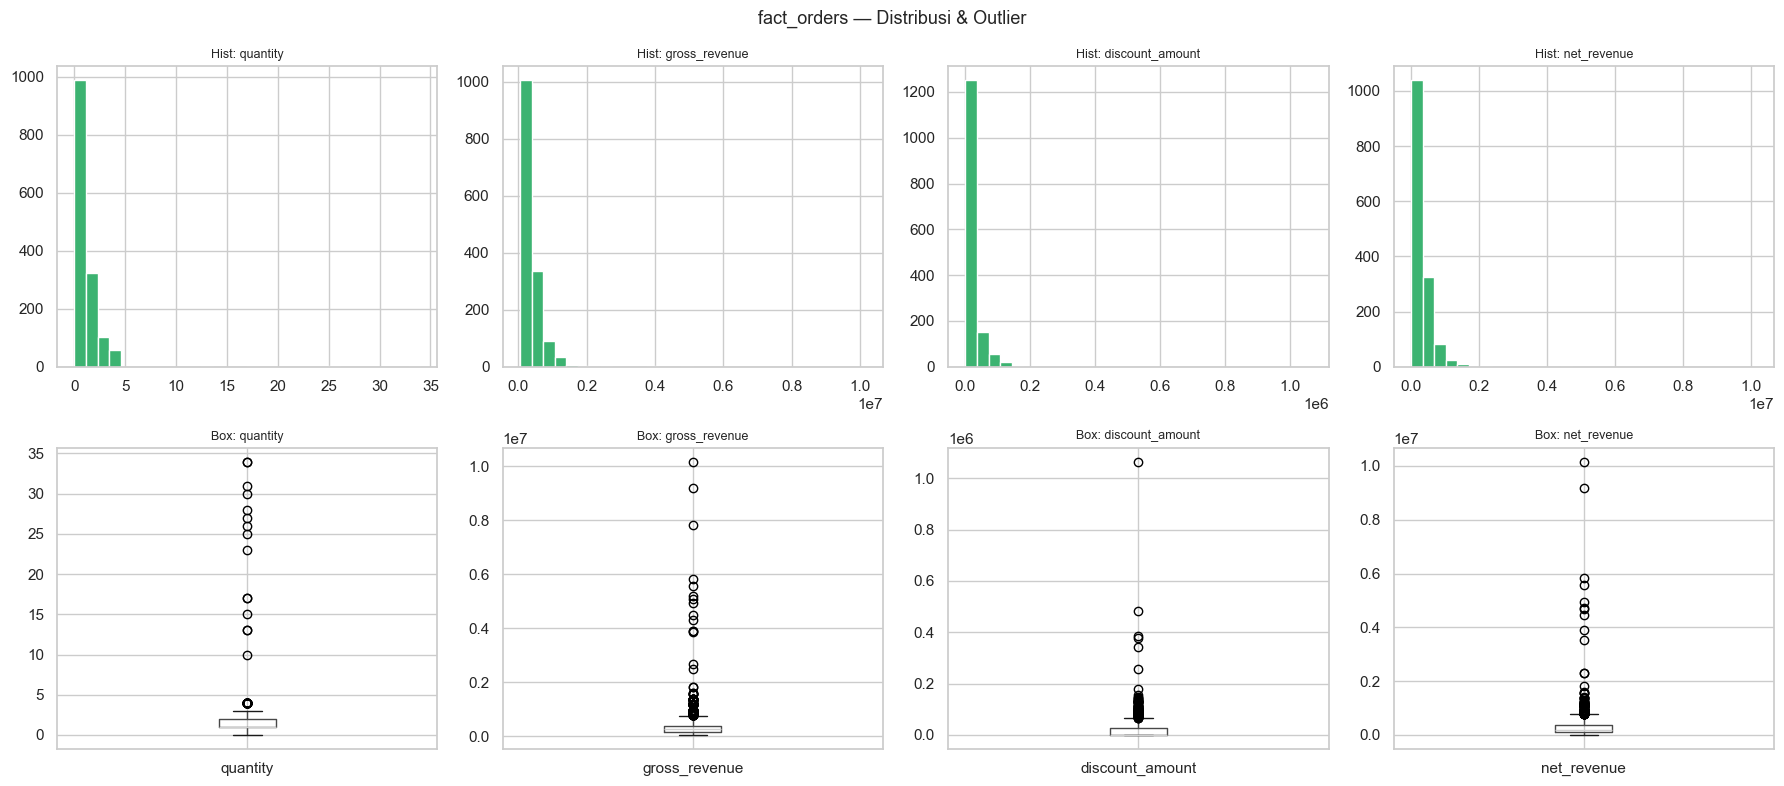


Outlier (IQR method):
  quantity             | Outlier: 74
  gross_revenue        | Outlier: 141
  discount_amount      | Outlier: 94
  net_revenue          | Outlier: 89


In [360]:
num_cols_ord = ['quantity', 'gross_revenue', 'discount_amount', 'net_revenue']

fig, axes = plt.subplots(2, len(num_cols_ord), figsize=(18, 8))
for i, col in enumerate(num_cols_ord):
    fact_orders[col].hist(ax=axes[0, i], bins=30, color='mediumseagreen', edgecolor='white')
    axes[0, i].set_title(f'Hist: {col}', fontsize=9)
    fact_orders.boxplot(column=col, ax=axes[1, i])
    axes[1, i].set_title(f'Box: {col}', fontsize=9)
plt.suptitle('fact_orders — Distribusi & Outlier', fontsize=13)
plt.tight_layout()
plt.show()

print('\nOutlier (IQR method):')
for col in num_cols_ord:
    Q1  = fact_orders[col].quantile(0.25)
    Q3  = fact_orders[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((fact_orders[col] < lower) | (fact_orders[col] > upper)).sum()
    print(f'  {col:<20} | Outlier: {n_out}')

### 12.7 Validasi Waktu

In [361]:
order_date_parsed = pd.to_datetime(fact_orders['order_date'], errors='coerce')
print(f'order_date tidak valid: {order_date_parsed.isna().sum()}')
print(f'Rentang order_date    : {order_date_parsed.min()} → {order_date_parsed.max()}')

order_date tidak valid: 25
Rentang order_date    : 2025-01-01 00:00:00 → 2025-12-31 00:00:00


In [362]:
# Parse timestamp
ts_parsed = pd.to_datetime(fact_orders['order_date'], errors='coerce')

# Ambil rows yang invalid (hasil parsing NaT)
invalid_ts = fact_orders[ts_parsed.isna()]

print("Rows dengan order_date tidak valid:")
print(invalid_ts)


Rows dengan order_date tidak valid:
        order_id  order_date customer_id  session_id channel_id campaign_id product_id  quantity  gross_revenue  discount_amount    net_revenue   payment_method order_status   refund_status  \
186   ORD0000187  12-24-2025   CUS014451  SES0003135      CH009         NaN     PRD009         2   158,000.0000           0.0000   158,000.0000         E-Wallet    Completed       No Refund   
197   ORD0000198  25/08/2025   CUS013797  SES0003323      CH001     CMP0002     PRD025         1   399,000.0000      33,494.7400   365,505.2600    Bank Transfer    Completed       No Refund   
242   ORD0000243  11-04-2025   CUS002731  SES0004115      CH004         NaN     PRD010         2   378,000.0000           0.0000   378,000.0000         E-Wallet    Completed       No Refund   
251   ORD0000252  07-13-2025   CUS005346  SES0004355      CH004         NaN     PRD037         1   139,000.0000           0.0000   139,000.0000              COD    Completed       No Refund   

In [363]:
# =============================================================================
# Cleaning order_date (mixed date format)
# =============================================================================

# Backup kolom asli (opsional untuk dokumentasi)
fact_orders["order_date_raw"] = fact_orders["order_date"]

# 1. Format ISO (2025-01-31)
order_date = pd.to_datetime(
    fact_orders["order_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

# 2. Format DD/MM/YYYY
mask = order_date.isna()
order_date.loc[mask] = pd.to_datetime(
    fact_orders.loc[mask, "order_date"],
    format="%d/%m/%Y",
    errors="coerce"
)

# 3. Format MM-DD-YYYY
mask = order_date.isna()
order_date.loc[mask] = pd.to_datetime(
    fact_orders.loc[mask, "order_date"],
    format="%m-%d-%Y",
    errors="coerce"
)

# Simpan kembali dalam format standar YYYY-MM-DD
fact_orders["order_date"] = order_date.dt.strftime("%Y-%m-%d")

print(f"Masih gagal diparsing : {fact_orders['order_date'].isna().sum()} baris")

Masih gagal diparsing : 0 baris


In [364]:
# =============================================================================
# Validasi order_date setelah cleaning
# =============================================================================

order_date_check = pd.to_datetime(
    fact_orders["order_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

print(f"Order_date tidak valid : {order_date_check.isna().sum()}")
print(f"Rentang tanggal        : {order_date_check.min()} → {order_date_check.max()}")

Order_date tidak valid : 0
Rentang tanggal        : 2025-01-01 00:00:00 → 2025-12-31 00:00:00


### 12.8 Foreign Key Validation

In [365]:
fk_checks_ord = {
    'customer_id'          : (fact_orders['customer_id'],           dim_customer_clean['customer_id']),
    'channel_id'           : (fact_orders['channel_id'],            dim_channel_clean['channel_id']),
    'product_id'           : (fact_orders['product_id'],            dim_product_clean['product_id']),
    'first_touch_channel_id': (fact_orders['first_touch_channel_id'], dim_channel_clean['channel_id']),
    'last_touch_channel_id' : (fact_orders['last_touch_channel_id'],  dim_channel_clean['channel_id']),
}

for fk, (fact_col, dim_col) in fk_checks_ord.items():
    orphan = ~fact_col.isin(dim_col)
    print(f'  FK [{fk:<25}] — orphan: {orphan.sum():,}')

# campaign_id — opsional (bisa null)
cid_non_null = fact_orders['campaign_id'].dropna()
orphan_cid   = ~cid_non_null.isin(dim_campaign_clean['campaign_id'])
print(f'  FK [campaign_id (non-null)      ] — orphan: {orphan_cid.sum():,} dari {len(cid_non_null):,}')

  FK [customer_id              ] — orphan: 8
  FK [channel_id               ] — orphan: 0
  FK [product_id               ] — orphan: 6
  FK [first_touch_channel_id   ] — orphan: 0
  FK [last_touch_channel_id    ] — orphan: 0
  FK [campaign_id (non-null)      ] — orphan: 6 dari 1,163


In [366]:
# customer id anomali
customer_orphan = fact_orders[
    ~fact_orders["customer_id"].isin(dim_customer_clean["customer_id"])
]

print(customer_orphan["customer_id"].unique())

display(customer_orphan)

<StringArray>
['CUS999999']
Length: 1, dtype: str


,order_id,order_date,customer_id,session_id,channel_id,campaign_id,product_id,quantity,gross_revenue,discount_amount,net_revenue,payment_method,order_status,refund_status,shipping_city,first_touch_channel_id,last_touch_channel_id,net_rev_check,is_match,calc_net,selisih,order_date_raw
160,ORD0000161,2025-12-19,CUS999999,SES0002625,CH007,CMP0022,PRD002,1,"159,000.0000",0.0000,"159,000.0000",E-Wallet,Completed,No Refund,Bekasi,CH001,CH007,"159,000.0000",Sama,"159,000.0000",0.0000,2025-12-19
346,ORD0000347,2025-12-23,CUS999999,SES0005860,CH008,NaN,PRD025,1,"399,000.0000",0.0000,0.0000,Virtual Account,Cancelled,No Refund,Medan,CH007,CH008,"399,000.0000",Tidak Sama,"399,000.0000","-399,000.0000",2025-12-23
349,ORD0000350,2025-09-06,CUS999999,SES0005882,CH002,CMP0004,PRD001,1,"179,000.0000","39,481.0300","139,518.9700",E-Wallet,Completed,No Refund,Malang,CH004,CH002,"139,518.9700",Sama,"139,518.9700",0.0000,2025-09-06
601,ORD0000602,2025-11-21,CUS999999,SES0010683,CH002,CMP0031,PRD005,1,"219,000.0000",0.0000,"219,000.0000",E-Wallet,Completed,No Refund,Malang,CH009,CH002,"219,000.0000",Sama,"219,000.0000",0.0000,2025-11-21
739,ORD0000740,2025-12-11,CUS999999,SES0013009,CH004,NaN,PRD007,1,"199,000.0000",0.0000,"199,000.0000",Credit Card,Paid,No Refund,Yogyakarta,CH001,CH004,"199,000.0000",Sama,"199,000.0000",0.0000,2025-12-11
869,ORD0000870,2025-09-14,CUS999999,SES0015337,CH001,CMP0002,PRD027,1,"389,000.0000",0.0000,"389,000.0000",Virtual Account,Completed,No Refund,Bandung,CH010,CH001,"389,000.0000",Sama,"389,000.0000",0.0000,2025-09-14
976,ORD0000977,2025-06-04,CUS999999,SES0017212,CH007,CMP0054,PRD040,2,"598,000.0000","85,369.4000","512,630.6000",Bank Transfer,Completed,Refunded,Jakarta,CH002,CH007,"512,630.6000",Sama,"512,630.6000",0.0000,2025-06-04
1244,ORD0001245,2025-11-28,CUS999999,SES0021582,CH002,CMP0004,PRD002,1,"159,000.0000","29,025.0400",0.0000,Credit Card,Cancelled,No Refund,Medan,CH003,CH002,"129,974.9600",Tidak Sama,"129,974.9600","-129,974.9600",2025-11-28


In [367]:
# product id anomali
product_orphan = fact_orders[
    ~fact_orders["product_id"].isin(dim_product_clean["product_id"])
]

print(product_orphan["product_id"].unique())

display(product_orphan)

<StringArray>
['PRD999']
Length: 1, dtype: str


,order_id,order_date,customer_id,session_id,channel_id,campaign_id,product_id,quantity,gross_revenue,discount_amount,net_revenue,payment_method,order_status,refund_status,shipping_city,first_touch_channel_id,last_touch_channel_id,net_rev_check,is_match,calc_net,selisih,order_date_raw
182,ORD0000183,2025-04-25,CUS004887,SES0003090,CH011,CMP0018,PRD999,1,"99,000.0000",0.0000,"99,000.0000",E-Wallet,Completed,Refunded,Bandung,CH005,CH011,"99,000.0000",Sama,"99,000.0000",0.0000,2025-04-25
663,ORD0000664,2025-06-28,CUS004872,SES0011828,CH006,CMP0005,PRD999,1,"329,000.0000","26,990.7100","302,009.2900",Virtual Account,Completed,No Refund,Yogyakarta,CH001,CH006,"302,009.2900",Sama,"302,009.2900",0.0000,2025-06-28
746,ORD0000747,2025-09-18,CUS008132,SES0013139,CH002,CMP0048,PRD999,1,"49,000.0000",0.0000,"49,000.0000",E-Wallet,Completed,No Refund,Medan,CH001,CH002,"49,000.0000",Sama,"49,000.0000",0.0000,2025-09-18
799,ORD0000800,2025-02-03,CUS011474,SES0014101,CH006,CMP0005,PRD999,1,"329,000.0000","36,932.5600","292,067.4400",E-Wallet,Completed,No Refund,Jakarta,CH002,CH006,"292,067.4400",Sama,"292,067.4400",0.0000,2025-02-03
975,ORD0000976,2025-09-25,CUS005582,SES0017192,CH001,CMP0002,PRD999,1,"459,000.0000",0.0000,"459,000.0000",Credit Card,Completed,No Refund,Jakarta,CH001,CH001,"459,000.0000",Sama,"459,000.0000",0.0000,2025-09-25
1121,ORD0001122,2025-09-26,CUS004307,SES0019661,CH011,CMP0053,PRD999,1,"389,000.0000","76,604.9900","312,395.0100",Virtual Account,Completed,No Refund,Makassar,CH006,CH011,"312,395.0100",Sama,"312,395.0100",0.0000,2025-09-26


In [368]:
# campaign id anomali

campaign_orphan = fact_orders[
    fact_orders["campaign_id"].notna() &
    ~fact_orders["campaign_id"].isin(dim_campaign_clean["campaign_id"])
]

print(campaign_orphan["campaign_id"].unique())

display(campaign_orphan)

<StringArray>
['CMP9999']
Length: 1, dtype: str


,order_id,order_date,customer_id,session_id,channel_id,campaign_id,product_id,quantity,gross_revenue,discount_amount,net_revenue,payment_method,order_status,refund_status,shipping_city,first_touch_channel_id,last_touch_channel_id,net_rev_check,is_match,calc_net,selisih,order_date_raw
58,ORD0000059,2025-11-04,CUS003769,SES0001125,CH006,CMP9999,PRD024,2,"918,000.0000","93,313.5900","824,686.4100",Credit Card,Completed,No Refund,Tangerang,CH001,CH006,"824,686.4100",Sama,"824,686.4100",0.0000,2025-11-04
165,ORD0000166,2025-07-16,CUS007951,SES0002679,CH007,CMP9999,PRD014,1,"99,000.0000","8,073.4600","90,926.5400",COD,Completed,No Refund,Jakarta,CH006,CH007,"90,926.5400",Sama,"90,926.5400",0.0000,2025-07-16
461,ORD0000462,2025-10-30,CUS007584,SES0008144,CH004,CMP9999,PRD006,1,"119,000.0000",0.0000,"119,000.0000",Virtual Account,Completed,Partial Refund,Medan,CH010,CH004,"119,000.0000",Sama,"119,000.0000",0.0000,2025-10-30
484,ORD0000485,2025-04-01,CUS007275,SES0008649,CH011,CMP9999,PRD021,4,"396,000.0000","35,329.5600","360,670.4400",COD,Completed,No Refund,Jakarta,CH009,CH011,"360,670.4400",Sama,"360,670.4400",0.0000,2025-04-01
589,ORD0000590,2025-04-20,CUS000228,SES0010447,CH001,CMP9999,PRD026,2,"378,000.0000","25,715.9400","352,284.0600",Credit Card,Completed,No Refund,Jakarta,CH007,CH001,"352,284.0600",Sama,"352,284.0600",0.0000,2025-04-20
599,ORD0000600,2025-07-30,CUS011886,SES0010617,CH001,CMP9999,PRD026,1,"189,000.0000",0.0000,0.0000,Virtual Account,Failed,Not Applicable,Bandung,CH001,CH001,"189,000.0000",Tidak Sama,"189,000.0000","-189,000.0000",2025-07-30


### 12.9 Cleaning fact_orders

In [369]:
# =============================================================================
# DATA CLEANING: Memperbaiki duplicate order_id
# =============================================================================
# Alasan:
# - Ditemukan 14 order_id duplikat.
# - Tidak ada duplicate row; seluruh atribut transaksi berbeda.
# - Terdapat 14 nomor order_id yang hilang dan polanya konsisten
#   (off-by-one numbering bug).
# - order_id hanya merupakan identifier dan tidak menjadi foreign key
#   pada tabel lain, sehingga identifier dapat dikoreksi tanpa
#   mengubah informasi bisnis transaksi.
# =============================================================================

# Salin dataframe
fact_orders_clean = fact_orders.copy()

# Ambil nomor order
order_num = (
    fact_orders_clean["order_id"]
    .str.replace("ORD", "", regex=False)
    .astype(int)
)

# Cari nomor yang hilang
missing_numbers = sorted(
    set(range(order_num.min(), order_num.max() + 1))
    - set(order_num)
)

# Cari semua duplicate order_id
dup_ids = (
    fact_orders_clean.loc[
        fact_orders_clean["order_id"].duplicated(keep=False),
        "order_id"
    ]
    .unique()
)

# Perbaiki kemunculan kedua dari setiap duplicate
for dup_id in dup_ids:

    current_num = int(dup_id.replace("ORD", ""))

    # nomor yang seharusnya
    new_num = current_num + 1

    if new_num in missing_numbers:

        idx = fact_orders_clean.index[
            fact_orders_clean["order_id"] == dup_id
        ][1]   # ambil kemunculan kedua

        fact_orders_clean.loc[idx, "order_id"] = f"ORD{new_num:07d}"

print("✅ Duplicate order_id berhasil diperbaiki.")

print(f"Duplicate order_id sesudah cleaning : {fact_orders_clean['order_id'].duplicated().sum()}")

✅ Duplicate order_id berhasil diperbaiki.
Duplicate order_id sesudah cleaning : 0


In [370]:
print(f'Duplicate rows     : {fact_orders_clean.duplicated().sum()}')
print(f'Duplicate order_id : {fact_orders_clean.duplicated(subset=["order_id"]).sum()}')

Duplicate rows     : 0
Duplicate order_id : 0


In [371]:
ford_clean = fact_orders_clean.copy()

# 1. Konversi order_date ke datetime 
ford_clean['order_date'] = pd.to_datetime(ford_clean['order_date'], errors='coerce')

# 2. Hapus kolom bantu validasi ─
if 'net_rev_check' in ford_clean.columns:
    ford_clean.drop(columns=['net_rev_check'], inplace=True)

# 3. Strip whitespace pada kolom string ─
for col in ford_clean.select_dtypes(include='object').columns:
    ford_clean[col] = ford_clean[col].str.strip()

# 4. Standardisasi kolom kategorikal 
for col in ['payment_method', 'order_status', 'refund_status']:
    if col in ford_clean.columns:
        ford_clean[col] = ford_clean[col].str.title()

# 5. Hapus duplicate order_id 
before = len(ford_clean)
ford_clean.drop_duplicates(subset=['order_id'], keep='first', inplace=True)
print(f'Duplicate order_id dihapus: {before - len(ford_clean)}')

# 6. Hapus duplicate rows 
before = len(ford_clean)
ford_clean.drop_duplicates(inplace=True)
print(f'Duplicate rows dihapus: {before - len(ford_clean)}')

print(f'Shape akhir: {ford_clean.shape}')
print('fact_orders cleaning selesai ')

Duplicate order_id dihapus: 0
Duplicate rows dihapus: 0
Shape akhir: (1490, 21)
fact_orders cleaning selesai 


---
## 13. Analisis & Cleaning — `fact_budget`

Data anggaran rencana dan realisasi.

**Primary Key:** `budget_id`  
**Grain:** satu baris = satu alokasi anggaran per bulan × channel × campaign  
**Foreign Keys:** `channel_id`, `campaign_id`

### 13.1 Gambaran Dataset

In [372]:
print('Shape :', fact_budget.shape)
print()
fact_budget.info()
display(fact_budget.head(5))
display(fact_budget.sample(5, random_state=42))

Shape : (228, 8)

<class 'pandas.DataFrame'>
RangeIndex: 228 entries, 0 to 227
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   budget_id        228 non-null    str  
 1   month            228 non-null    str  
 2   channel_id       228 non-null    str  
 3   campaign_id      228 non-null    str  
 4   planned_budget   228 non-null    str  
 5   actual_spend     228 non-null    str  
 6   budget_owner     228 non-null    str  
 7   approval_status  228 non-null    str  
dtypes: str(8)
memory usage: 14.4 KB


,budget_id,month,channel_id,campaign_id,planned_budget,actual_spend,budget_owner,approval_status
0,BUD00001,2025-01,CH001,CMP0001,158333333.33,412940311.69,Marketplace Team,Approved
1,BUD00002,2025-01,CH001,CMP0044,89075000.0,331181161.65,CRM Team,Approved
2,BUD00003,2025-01,CH001,CMP0050,29549000.0,41553808.99,Performance Team,Approved
3,BUD00004,2025-01,CH002,CMP0004,51666666.67,323109374.87,Performance Team,Approved
4,BUD00005,2025-01,CH002,CMP0037,32501500.0,198334222.77,CRM Team,Pending


,budget_id,month,channel_id,campaign_id,planned_budget,actual_spend,budget_owner,approval_status
215,BUD00216,2025-12,CH001,CMP0030,54251750.0,11717505.59,Performance Team,Approved
66,BUD00067,2025-05,CH004,CMP0041,2469250.0,673384.59,Marketplace Team,Approved
9,BUD00010,2025-02,CH001,CMP0002,23636363.64,74811559.33,CRM Team,Approved
200,BUD00201,2025-11,CH002,CMP9999,1577571.47,3132178.98,Unmapped,Need Revision
15,BUD00016,2025-02,CH006,CMP0040,4409333.33,3156222.88,Brand Team,Approved


### 13.2 Statistik Deskriptif

In [373]:
display(fact_budget.describe(include='all'))

print('\napproval_status ')
print(fact_budget['approval_status'].value_counts())

print('\nbudget_owner ')
print(fact_budget['budget_owner'].value_counts())

print('\nmonth ')
print(sorted(fact_budget['month'].unique()))

,budget_id,month,channel_id,campaign_id,planned_budget,actual_spend,budget_owner,approval_status
count,228,228,228,228,228,228,228,228
unique,228,12,12,62,75,228,6,4
top,BUD00001,2025-08,CH001,CMP0004,51666666.67,412940311.69,Performance Team,Approved
freq,1,27,47,12,12,1,72,176



approval_status 
approval_status
Approved         176
Need Revision     21
Pending           20
Rejected          11
Name: count, dtype: int64

budget_owner 
budget_owner
Performance Team    72
CRM Team            45
Brand Team          41
Marketplace Team    33
Growth Team         24
Unmapped            13
Name: count, dtype: int64

month 
['2025-01', '2025-02', '2025-03', '2025-04', '2025-05', '2025-06', '2025-07', '2025-08', '2025-09', '2025-10', '2025-11', '2025-12']


### 13.3 Missing Value Analysis

In [374]:
mv = fact_budget.isnull().sum()
mv_pct = (mv / len(fact_budget) * 100).round(2)
mv_df = pd.DataFrame({'missing_count': mv, 'missing_pct': mv_pct})
mv_df = mv_df[mv_df['missing_count'] > 0]
if mv_df.empty:
    print(' Tidak ada missing value pada fact_budget')
else:
    display(mv_df)

 Tidak ada missing value pada fact_budget


### 13.4 Duplicate Analysis

In [375]:
grain_budget = ['month', 'channel_id', 'campaign_id']
print(f'Duplicate rows                         : {fact_budget.duplicated().sum()}')
print(f'Duplicate budget_id PK                 : {fact_budget.duplicated(subset=["budget_id"]).sum()}')
print(f'Duplicate grain (month+channel+campaign): {fact_budget.duplicated(subset=grain_budget).sum()}')

Duplicate rows                         : 0
Duplicate budget_id PK                 : 0
Duplicate grain (month+channel+campaign): 0


### 13.5 Validasi Nilai

In [376]:
fact_budget.info()

<class 'pandas.DataFrame'>
RangeIndex: 228 entries, 0 to 227
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   budget_id        228 non-null    str  
 1   month            228 non-null    str  
 2   channel_id       228 non-null    str  
 3   campaign_id      228 non-null    str  
 4   planned_budget   228 non-null    str  
 5   actual_spend     228 non-null    str  
 6   budget_owner     228 non-null    str  
 7   approval_status  228 non-null    str  
dtypes: str(8)
memory usage: 14.4 KB


In [377]:
fact_budget.dtypes

budget_id          str
month              str
channel_id         str
campaign_id        str
planned_budget     str
actual_spend       str
budget_owner       str
approval_status    str
dtype: object

In [378]:
# planned_budget
planned_check = pd.to_numeric(fact_budget["planned_budget"], errors="coerce")

invalid_planned = fact_budget.loc[
    planned_check.isna(),
    ["budget_id", "planned_budget"]
]

print(f"Planned_budget tidak valid: {len(invalid_planned)}")
display(invalid_planned)

Planned_budget tidak valid: 1


,budget_id,planned_budget
68,BUD00069,"4,484,500"


In [379]:
# actual_spend
actual_check = pd.to_numeric(fact_budget["actual_spend"], errors="coerce")

invalid_actual = fact_budget.loc[
    actual_check.isna(),
    ["budget_id", "actual_spend"]
]

print(f"Actual_spend tidak valid: {len(invalid_actual)}")
display(invalid_actual)

Actual_spend tidak valid: 2


,budget_id,actual_spend
35,BUD00036,"105,602,706"
218,BUD00219,Rp 140.180.494


In [380]:
# =============================================================================
# Standardisasi format nilai budget
# =============================================================================

budget_cols = ["planned_budget", "actual_spend"]

for col in budget_cols:

    fact_budget[col] = (
        fact_budget[col]
        .astype(str)
        .str.strip()
        .str.replace("Rp", "", regex=False)
        .str.replace(" ", "", regex=False)
    )

    # Jika ada koma, diasumsikan sebagai pemisah ribuan
    fact_budget[col] = fact_budget[col].str.replace(",", "", regex=False)

    # Jika masih ada titik lebih dari satu berarti titik tsb pemisah ribuan
    mask = fact_budget[col].str.count(r"\.") > 1
    fact_budget.loc[mask, col] = (
        fact_budget.loc[mask, col]
        .str.replace(".", "", regex=False)
    )

    # Ubah menjadi numerik
    fact_budget[col] = pd.to_numeric(
        fact_budget[col],
        errors="coerce"
    )

In [381]:
print(fact_budget[budget_cols].dtypes)

print("planned_budget NaN :", fact_budget["planned_budget"].isna().sum())
print("actual_spend NaN   :", fact_budget["actual_spend"].isna().sum())

planned_budget    float64
actual_spend      float64
dtype: object
planned_budget NaN : 0
actual_spend NaN   : 0


In [382]:
print('planned_budget negatif:', (fact_budget['planned_budget'] < 0).sum())
print('actual_spend negatif  :', (fact_budget['actual_spend'] < 0).sum())

# Budget utilization rate
fact_budget['utilization_rate'] = np.where(
    fact_budget['planned_budget'] > 0,
    fact_budget['actual_spend'] / fact_budget['planned_budget'],
    np.nan
)
print(f'\nBudget utilization rate (aktual/planned):')
print(fact_budget['utilization_rate'].describe())
print(f'Utilization > 2x rencana (>200%): {(fact_budget["utilization_rate"] > 2).sum()}')

planned_budget negatif: 0
actual_spend negatif  : 0

Budget utilization rate (aktual/planned):
count   228.0000
mean      2.7364
std       2.0330
min       0.0063
25%       0.8380
50%       2.6000
75%       4.1161
max       8.5067
Name: utilization_rate, dtype: float64
Utilization > 2x rencana (>200%): 130


### 13.6 Distribusi & Outlier

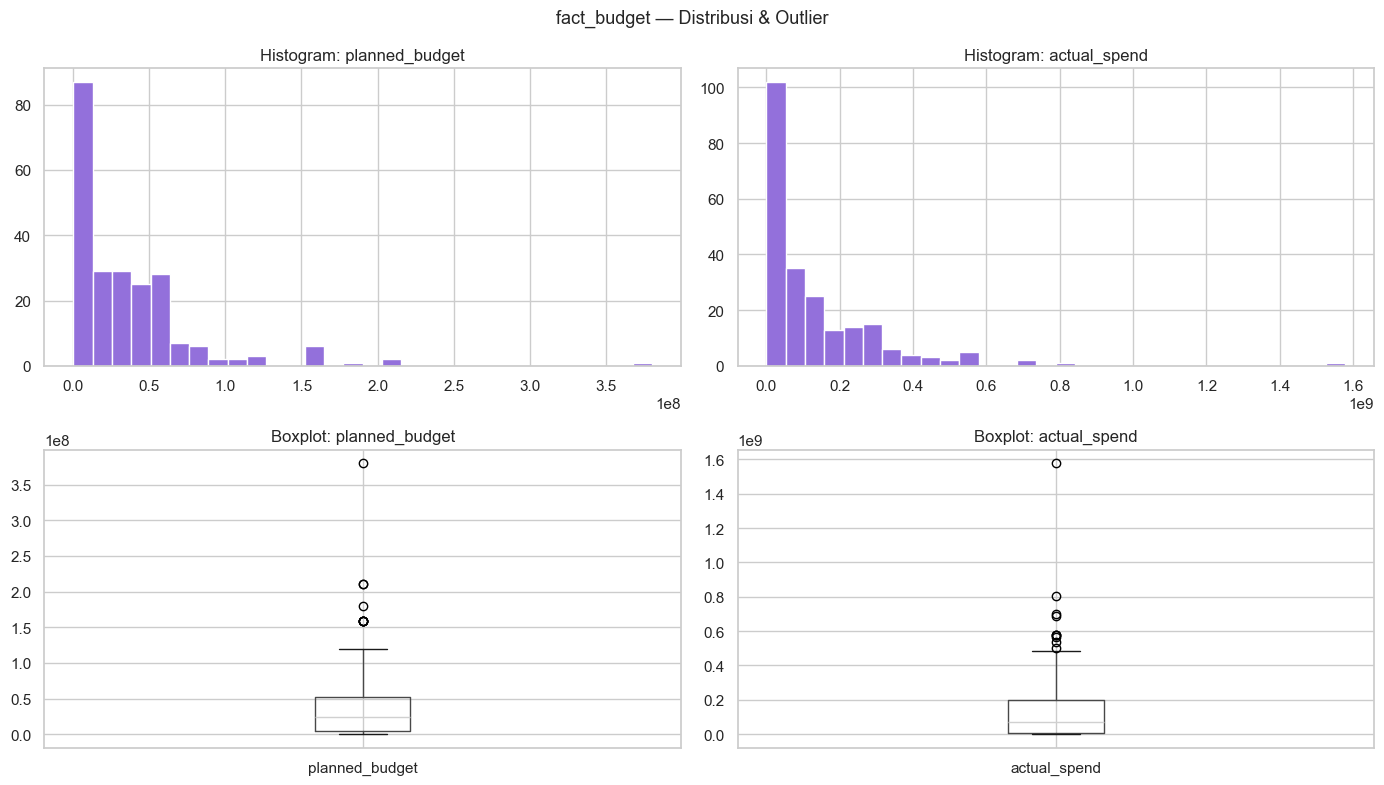

In [383]:
num_cols_bud = ['planned_budget', 'actual_spend']

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for i, col in enumerate(num_cols_bud):
    fact_budget[col].hist(ax=axes[0, i], bins=30, color='mediumpurple', edgecolor='white')
    axes[0, i].set_title(f'Histogram: {col}')
    fact_budget.boxplot(column=col, ax=axes[1, i])
    axes[1, i].set_title(f'Boxplot: {col}')
plt.suptitle('fact_budget — Distribusi & Outlier', fontsize=13)
plt.tight_layout()
plt.show()

### 13.7 Foreign Key Validation

In [384]:
for fk, fact_col, dim_col in [
    ('channel_id',  fact_budget['channel_id'],  dim_channel_clean['channel_id']),
    ('campaign_id', fact_budget['campaign_id'], dim_campaign_clean['campaign_id']),
]:
    orphan = ~fact_col.isin(dim_col)
    print(f'  FK [{fk:<12}] — orphan: {orphan.sum():,}')

  FK [channel_id  ] — orphan: 7
  FK [campaign_id ] — orphan: 6


In [385]:
# Channel yang orphan
channel_orphan = fact_budget[
    ~fact_budget["channel_id"].isin(dim_channel_clean["channel_id"])
]

print("Channel ID bermasalah:")
print(channel_orphan["channel_id"].unique())

display(channel_orphan)


# Campaign yang orphan
campaign_orphan = fact_budget[
    ~fact_budget["campaign_id"].isin(dim_campaign_clean["campaign_id"])
]

print("Campaign ID bermasalah:")
print(campaign_orphan["campaign_id"].unique())

display(campaign_orphan)

Channel ID bermasalah:
<StringArray>
['CH_META']
Length: 1, dtype: str


,budget_id,month,channel_id,campaign_id,planned_budget,actual_spend,budget_owner,approval_status,utilization_rate
22,BUD00023,2025-02,CH_META,CMP0001,"5,239,962.5400","11,797,068.7400",Unmapped,Approved,2.2514
23,BUD00024,2025-02,CH_META,CMP0020,"2,970,331.2400","3,334,526.8500",Unmapped,Need Revision,1.1226
59,BUD00060,2025-04,CH_META,CMP0018,"528,776.0300","863,338.4800",Unmapped,Need Revision,1.6327
121,BUD00122,2025-07,CH_META,CMP0026,"514,972.5700","956,681.1600",Unmapped,Approved,1.8577
148,BUD00149,2025-08,CH_META,CMP0053,"2,199,731.9600","2,453,907.3900",Unmapped,Approved,1.1155
188,BUD00189,2025-10,CH_META,CMP0035,"1,034,932.9600","2,000,384.0200",Unmapped,Approved,1.9329
227,BUD00228,2025-12,CH_META,CMP0010,"4,817,946.8500","7,746,105.4400",Unmapped,Approved,1.6078


Campaign ID bermasalah:
<StringArray>
['CMP9999']
Length: 1, dtype: str


,budget_id,month,channel_id,campaign_id,planned_budget,actual_spend,budget_owner,approval_status,utilization_rate
96,BUD00097,2025-06,CH011,CMP9999,"2,155,382.2900","4,101,219.5805",Unmapped,Pending,1.9028
140,BUD00141,2025-08,CH009,CMP9999,"283,224.6900","613,533.4400",Unmapped,Need Revision,2.1662
143,BUD00144,2025-08,CH010,CMP9999,"1,399,693.6800","1,749,302.2200",Unmapped,Approved,1.2498
164,BUD00165,2025-09,CH010,CMP9999,"1,131,013.8300","1,287,663.3900",Unmapped,Approved,1.1385
195,BUD00196,2025-11,CH001,CMP9999,"635,055.9500","947,871.5400",Unmapped,Pending,1.4926
200,BUD00201,2025-11,CH002,CMP9999,"1,577,571.4700","3,132,178.9800",Unmapped,Need Revision,1.9854


### 13.8 Cleaning fact_budget

In [386]:
fbud_clean = fact_budget.copy()

# 1. Drop kolom bantu 
if 'utilization_rate' in fbud_clean.columns:
    fbud_clean.drop(columns=['utilization_rate'], inplace=True)

# 2. Strip whitespace pada kolom string ─
for col in fbud_clean.select_dtypes(include='object').columns:
    fbud_clean[col] = fbud_clean[col].str.strip()

# 3. Standardisasi approval_status dan budget_owner 
fbud_clean['approval_status'] = fbud_clean['approval_status'].str.title()
fbud_clean['budget_owner']    = fbud_clean['budget_owner'].str.title()

# 4. Hapus duplicate 
before = len(fbud_clean)
fbud_clean.drop_duplicates(inplace=True)
print(f'Duplicate dihapus: {before - len(fbud_clean)}')

print(f'Shape akhir: {fbud_clean.shape}')
print('fact_budget cleaning selesai ')

Duplicate dihapus: 0
Shape akhir: (228, 8)
fact_budget cleaning selesai 


In [387]:
fbud_clean.head()

,budget_id,month,channel_id,campaign_id,planned_budget,actual_spend,budget_owner,approval_status
0,BUD00001,2025-01,CH001,CMP0001,"158,333,333.3300","412,940,311.6900",Marketplace Team,Approved
1,BUD00002,2025-01,CH001,CMP0044,"89,075,000.0000","331,181,161.6500",Crm Team,Approved
2,BUD00003,2025-01,CH001,CMP0050,"29,549,000.0000","41,553,808.9900",Performance Team,Approved
3,BUD00004,2025-01,CH002,CMP0004,"51,666,666.6700","323,109,374.8700",Performance Team,Approved
4,BUD00005,2025-01,CH002,CMP0037,"32,501,500.0000","198,334,222.7700",Crm Team,Pending


---
## 14. Analisis Relasi Antar Tabel (Star Schema Integrity)

Validasi komprehensif integritas foreign key pada seluruh tabel setelah cleaning.

### 14.1 Ringkasan Dimensi (Primary Key Check)

In [388]:
dim_summary = {
    'dim_date'       : ('date_id',     dim_date_clean),
    'dim_channel'    : ('channel_id',  dim_channel_clean),
    'dim_campaign'   : ('campaign_id', dim_campaign_clean),
    'dim_ad_content' : ('ad_id',       dim_ad_content_clean),
    'dim_kol'        : ('kol_id',      dim_kol_clean),
    'dim_product'    : ('product_id',  dim_product_clean),
    'dim_customer'   : ('customer_id', dim_customer_clean),
}

print('=' * 60)
print(f'{"Dimensi":<20} {"PK":<15} {"Baris":>8} {"PK Unik?":>10}')
print('=' * 60)
for name, (pk, df) in dim_summary.items():
    is_unique = df[pk].nunique() == len(df)
    status = ' Ya' if is_unique else '❌ TIDAK'
    print(f'{name:<20} {pk:<15} {len(df):>8,} {status:>10}')
print('=' * 60)

Dimensi              PK                 Baris   PK Unik?
dim_date             date_id              365         Ya
dim_channel          channel_id            12         Ya
dim_campaign         campaign_id           62         Ya
dim_ad_content       ad_id                194         Ya
dim_kol              kol_id                28         Ya
dim_product          product_id            40         Ya
dim_customer         customer_id       15,000         Ya


### 14.2 Validasi FK — fact_marketing_daily

In [389]:
def check_fk(fact_df, fact_col, dim_df, dim_col, fk_name, nullable=False):
    """Helper: validasi foreign key dan tampilkan ringkasan."""
    col_data = fact_df[fact_col]
    if nullable:
        col_data = col_data.dropna()
    orphan_count = (~col_data.isin(dim_df[dim_col])).sum()
    total = len(col_data)
    pct   = orphan_count / total * 100 if total > 0 else 0
    status = '' if orphan_count == 0 else '⚠️'
    print(f'  {status} {fk_name:<25} orphan: {orphan_count:,} / {total:,} ({pct:.2f}%)')
    return orphan_count

print('fact_marketing_daily ')
check_fk(fmd_clean, 'date_id',     dim_date_clean,        'date_id',     'date_id')
check_fk(fmd_clean, 'channel_id',  dim_channel_clean,     'channel_id',  'channel_id')
check_fk(fmd_clean, 'campaign_id', dim_campaign_clean,    'campaign_id', 'campaign_id')
check_fk(fmd_clean, 'ad_id',       dim_ad_content_clean,  'ad_id',       'ad_id')
check_fk(fmd_clean, 'kol_id',      dim_kol_clean,         'kol_id',      'kol_id (nullable)', nullable=True)

fact_marketing_daily 
   date_id                   orphan: 0 / 15,849 (0.00%)
  ⚠️ channel_id                orphan: 7 / 15,849 (0.04%)
  ⚠️ campaign_id               orphan: 6 / 15,849 (0.04%)
   ad_id                     orphan: 0 / 15,849 (0.00%)
   kol_id (nullable)         orphan: 0 / 1,659 (0.00%)


np.int64(0)

### 14.3 Validasi FK — fact_web_events

In [390]:
print('fact_web_events ')
check_fk(fwe_clean, 'date_id',     dim_date_clean,       'date_id',     'date_id')
check_fk(fwe_clean, 'customer_id', dim_customer_clean,   'customer_id', 'customer_id')
check_fk(fwe_clean, 'channel_id',  dim_channel_clean,    'channel_id',  'channel_id')
check_fk(fwe_clean, 'campaign_id', dim_campaign_clean,   'campaign_id', 'campaign_id (nullable)', nullable=True)
check_fk(fwe_clean, 'ad_id',       dim_ad_content_clean, 'ad_id',       'ad_id (nullable)',       nullable=True)
check_fk(fwe_clean, 'product_id',  dim_product_clean,    'product_id',  'product_id (nullable)',  nullable=True)

fact_web_events 
   date_id                   orphan: 0 / 72,881 (0.00%)
   customer_id               orphan: 0 / 72,881 (0.00%)
  ⚠️ channel_id                orphan: 73 / 72,881 (0.10%)
  ⚠️ campaign_id (nullable)    orphan: 36 / 51,252 (0.07%)
   ad_id (nullable)          orphan: 0 / 51,241 (0.00%)
  ⚠️ product_id (nullable)     orphan: 36 / 44,835 (0.08%)


np.int64(36)

### 14.4 Validasi FK — fact_orders

In [391]:
print('fact_orders ')
check_fk(ford_clean, 'customer_id',           dim_customer_clean,  'customer_id', 'customer_id')
check_fk(ford_clean, 'channel_id',            dim_channel_clean,   'channel_id',  'channel_id')
check_fk(ford_clean, 'product_id',            dim_product_clean,   'product_id',  'product_id')
check_fk(ford_clean, 'first_touch_channel_id',dim_channel_clean,   'channel_id',  'first_touch_channel_id')
check_fk(ford_clean, 'last_touch_channel_id', dim_channel_clean,   'channel_id',  'last_touch_channel_id')
check_fk(ford_clean, 'campaign_id',           dim_campaign_clean,  'campaign_id', 'campaign_id (nullable)', nullable=True)

fact_orders 
  ⚠️ customer_id               orphan: 8 / 1,490 (0.54%)
   channel_id                orphan: 0 / 1,490 (0.00%)
  ⚠️ product_id                orphan: 6 / 1,490 (0.40%)
   first_touch_channel_id    orphan: 0 / 1,490 (0.00%)
   last_touch_channel_id     orphan: 0 / 1,490 (0.00%)
  ⚠️ campaign_id (nullable)    orphan: 6 / 1,163 (0.52%)


np.int64(6)

### 14.5 Validasi FK — fact_budget

In [392]:
print('fact_budget ')
check_fk(fbud_clean, 'channel_id',  dim_channel_clean,  'channel_id',  'channel_id')
check_fk(fbud_clean, 'campaign_id', dim_campaign_clean, 'campaign_id', 'campaign_id')

fact_budget 
  ⚠️ channel_id                orphan: 7 / 228 (3.07%)
  ⚠️ campaign_id               orphan: 6 / 228 (2.63%)


np.int64(6)

### 14.6 Cardinality Check (Star Schema)

In [393]:
print('Cardinality — satu dimensi ke banyak fakta (One-to-Many)')
print('=' * 70)

relations = [
    ('dim_channel',     'channel_id',  'fact_marketing_daily', fmd_clean),
    ('dim_channel',     'channel_id',  'fact_orders',          ford_clean),
    ('dim_campaign',    'campaign_id', 'fact_marketing_daily', fmd_clean),
    ('dim_campaign',    'campaign_id', 'fact_orders',          ford_clean),
    ('dim_product',     'product_id',  'fact_orders',          ford_clean),
    ('dim_customer',    'customer_id', 'fact_orders',          ford_clean),
    ('dim_ad_content',  'ad_id',       'fact_marketing_daily', fmd_clean),
]

for dim_name, key, fact_name, fact_df in relations:
    dim_unique  = dim_summary[dim_name][1][key].nunique()
    fact_count  = fact_df[key].nunique()
    ratio       = fact_df.shape[0] / dim_unique if dim_unique > 0 else 0
    print(f'  {dim_name:<18} ({dim_unique:>5} dim) → {fact_name:<25} ({fact_count:>5} used) | ratio ≈ {ratio:,.1f}x')

Cardinality — satu dimensi ke banyak fakta (One-to-Many)
  dim_channel        (   12 dim) → fact_marketing_daily      (   12 used) | ratio ≈ 1,320.8x
  dim_channel        (   12 dim) → fact_orders               (   12 used) | ratio ≈ 124.2x
  dim_campaign       (   62 dim) → fact_marketing_daily      (   62 used) | ratio ≈ 255.6x
  dim_campaign       (   62 dim) → fact_orders               (   57 used) | ratio ≈ 24.0x
  dim_product        (   40 dim) → fact_orders               (   39 used) | ratio ≈ 37.2x
  dim_customer       (15000 dim) → fact_orders               ( 1414 used) | ratio ≈ 0.1x
  dim_ad_content     (  194 dim) → fact_marketing_daily      (  192 used) | ratio ≈ 81.7x


### 14.7 Ringkasan Akhir Masalah Data

In [394]:
cleaned_tables = {
    'dim_date'             : dim_date_clean,
    'dim_channel'          : dim_channel_clean,
    'dim_campaign'         : dim_campaign_clean,
    'dim_ad_content'       : dim_ad_content_clean,
    'dim_kol'              : dim_kol_clean,
    'dim_product'          : dim_product_clean,
    'dim_customer'         : dim_customer_clean,
    'fact_marketing_daily' : fmd_clean,
    'fact_web_events'      : fwe_clean,
    'fact_orders'          : ford_clean,
    'fact_budget'          : fbud_clean,
}

print('=' * 70)
print(f'{"Tabel":<25} {"Baris (raw)":>12} {"Baris (clean)":>14} {"Missing":>10}')
print('=' * 70)
for name, df_clean in cleaned_tables.items():
    df_raw   = tables[name]
    missing  = df_clean.isnull().sum().sum()
    print(f'{name:<25} {df_raw.shape[0]:>12,} {df_clean.shape[0]:>14,} {missing:>10,}')
print('=' * 70)

Tabel                      Baris (raw)  Baris (clean)    Missing
dim_date                           365            365          0
dim_channel                         12             12          0
dim_campaign                        62             62          0
dim_ad_content                     194            194          0
dim_kol                             28             28          0
dim_product                         40             40          0
dim_customer                    15,000         15,000      3,203
fact_marketing_daily            15,849         15,849     14,215
fact_web_events                 72,881         72,881     93,301
fact_orders                      1,490          1,490        327
fact_budget                        228            228          0


---
## 15. Simpan Dataset Hasil Cleaning

Dataset bersih disimpan ke folder `dataset_clean/` dalam format CSV.

### 15.1 Final Validation Sebelum Simpan

In [395]:
print('Pengecekan ulang MISSING VALUE (tabel bersih):')
print('-' * 50)
for name, df in cleaned_tables.items():
    total_missing = df.isnull().sum().sum()
    # Tampilkan hanya yang masih ada missing, lengkap dengan kolom mana
    mv_remaining = df.isnull().sum()
    mv_remaining = mv_remaining[mv_remaining > 0]
    if mv_remaining.empty:
        print(f'  {name:<25}:  0 missing')
    else:
        print(f'  {name:<25}: ⚠️  {total_missing} missing pada kolom: {mv_remaining.index.tolist()}')
        print(f'      (Catatan: missing pada kolom FK opsional adalah expected behavior)')

Pengecekan ulang MISSING VALUE (tabel bersih):
--------------------------------------------------
  dim_date                 :  0 missing
  dim_channel              :  0 missing
  dim_campaign             :  0 missing
  dim_ad_content           :  0 missing
  dim_kol                  :  0 missing
  dim_product              :  0 missing
  dim_customer             : ⚠️  3203 missing pada kolom: ['age', 'first_purchase_date']
      (Catatan: missing pada kolom FK opsional adalah expected behavior)
  fact_marketing_daily     : ⚠️  14215 missing pada kolom: ['kol_id', 'spend', 'revenue']
      (Catatan: missing pada kolom FK opsional adalah expected behavior)
  fact_web_events          : ⚠️  93301 missing pada kolom: ['campaign_id', 'ad_id', 'product_id', 'utm_campaign']
      (Catatan: missing pada kolom FK opsional adalah expected behavior)
  fact_orders              : ⚠️  327 missing pada kolom: ['campaign_id']
      (Catatan: missing pada kolom FK opsional adalah expected behavior)
  fa

In [396]:
print('Pengecekan ulang DUPLICATE (tabel bersih):')
print('-' * 50)

pk_map = {
    'dim_date'             : 'date_id',
    'dim_channel'          : 'channel_id',
    'dim_campaign'         : 'campaign_id',
    'dim_ad_content'       : 'ad_id',
    'dim_kol'              : 'kol_id',
    'dim_product'          : 'product_id',
    'dim_customer'         : 'customer_id',
    'fact_marketing_daily' : None,  # grain: (date_id, channel_id, campaign_id, ad_id)
    'fact_web_events'      : 'event_id',
    'fact_orders'          : 'order_id',
    'fact_budget'          : 'budget_id',
}

for name, df in cleaned_tables.items():
    dup_rows = df.duplicated().sum()
    pk = pk_map[name]
    if pk:
        dup_pk = df.duplicated(subset=[pk]).sum()
        status = '' if dup_rows == 0 and dup_pk == 0 else '⚠️'
        print(f'  {status} {name:<25}: dup_rows={dup_rows}, dup_pk({pk})={dup_pk}')
    else:
        print(f'  {"" if dup_rows == 0 else "⚠️"} {name:<25}: dup_rows={dup_rows} (no single PK, grain-based)')

Pengecekan ulang DUPLICATE (tabel bersih):
--------------------------------------------------
   dim_date                 : dup_rows=0, dup_pk(date_id)=0
   dim_channel              : dup_rows=0, dup_pk(channel_id)=0
   dim_campaign             : dup_rows=0, dup_pk(campaign_id)=0
   dim_ad_content           : dup_rows=0, dup_pk(ad_id)=0
   dim_kol                  : dup_rows=0, dup_pk(kol_id)=0
   dim_product              : dup_rows=0, dup_pk(product_id)=0
   dim_customer             : dup_rows=0, dup_pk(customer_id)=0
   fact_marketing_daily     : dup_rows=0 (no single PK, grain-based)
   fact_web_events          : dup_rows=0, dup_pk(event_id)=0
   fact_orders              : dup_rows=0, dup_pk(order_id)=0
   fact_budget              : dup_rows=0, dup_pk(budget_id)=0


### 15.2 Simpan ke CSV

In [397]:
OUTPUT_PATH = 'dataset_clean/'
os.makedirs(OUTPUT_PATH, exist_ok=True)

for name, df in cleaned_tables.items():
    filepath = OUTPUT_PATH + name + '_clean.csv'
    df.to_csv(filepath, index=False)
    print(f'  Tersimpan: {filepath}  ({df.shape[0]:,} baris × {df.shape[1]} kolom)')

print('\n Seluruh dataset berhasil disimpan ke folder:', OUTPUT_PATH)

  Tersimpan: dataset_clean/dim_date_clean.csv  (365 baris × 12 kolom)
  Tersimpan: dataset_clean/dim_channel_clean.csv  (12 baris × 6 kolom)
  Tersimpan: dataset_clean/dim_campaign_clean.csv  (62 baris × 12 kolom)
  Tersimpan: dataset_clean/dim_ad_content_clean.csv  (194 baris × 9 kolom)
  Tersimpan: dataset_clean/dim_kol_clean.csv  (28 baris × 12 kolom)
  Tersimpan: dataset_clean/dim_product_clean.csv  (40 baris × 8 kolom)
  Tersimpan: dataset_clean/dim_customer_clean.csv  (15,000 baris × 12 kolom)
  Tersimpan: dataset_clean/fact_marketing_daily_clean.csv  (15,849 baris × 22 kolom)
  Tersimpan: dataset_clean/fact_web_events_clean.csv  (72,881 baris × 19 kolom)
  Tersimpan: dataset_clean/fact_orders_clean.csv  (1,490 baris × 21 kolom)
  Tersimpan: dataset_clean/fact_budget_clean.csv  (228 baris × 8 kolom)

 Seluruh dataset berhasil disimpan ke folder: dataset_clean/


---
## 16. Ringkasan Dokumentasi Keputusan Cleaning

| Tabel | Isu Ditemukan | Aksi Cleaning | Catatan |
|---|---|---|---|
| dim_date | Kolom `date` bertipe object, `is_weekend`/`is_holiday` string | Konversi datetime & boolean | OK |
| dim_channel | Inkonsistensi kapitalisasi | Strip + title case | OK |
| dim_campaign | Kolom tanggal sebagai object, end_date < start_date | Konversi datetime, flag invalid | Perlu verifikasi manual |
| dim_ad_content | Whitespace pada nilai | Strip + title case | OK |
| dim_kol | Outlier follower & rate_card | TIDAK dihapus (valid: perbedaan tier KOL) | Didokumentasikan |
| dim_product | `margin_percentage` ada spasi, `launch_date` object | Strip + konversi numerik & datetime | OK |
| dim_customer | Inkonsistensi gender (Wanita/Female/Pria/Male/M/L) | Standardisasi ke Male/Female/Unknown | Perlu verifikasi domain |
| fact_marketing_daily | Revenue negatif, duplicate grain | Flag + hapus duplicate | Outlier numerik tidak dihapus |
| fact_web_events | FK opsional null (campaign/ad/product) | Dipertahankan (wajar untuk sesi organik) | OK |
| fact_orders | Validasi net_revenue formula | Flag ketidaksesuaian | Perlu verifikasi manual |
| fact_budget | Utilization rate > 200% | Flag, tidak dihapus | Perlu justifikasi bisnis |

> **Asumsi:** Outlier pada metrik bisnis (revenue, spend, follower) TIDAK dihapus tanpa justifikasi analitis, sesuai panduan. Data ekstrem diidentifikasi dan didokumentasikan.

> **Keterbatasan:** Dataset bersifat sintetis sehingga beberapa anomali mungkin merupakan bagian dari desain dataset, bukan kesalahan data nyata.